# 02 · Exploratory data analysis

**Goal:** understand how TTC bus incidents behave *in general*, so that `03_event_effect` compares events against the right baseline.

Input: `data/processed/*.csv` (created by `01_data_prep`). Output: charts only, no files.

This notebook is built **step by step**; steps are added as they are agreed.

| Step | Question |
|---|---|
| 1 | How many incidents are there, and how do they change over time? |
| 2 | How long are the delays, and how are they distributed? |
| 3 | At which hours of the day do incidents happen? |
| 4 | Why do incidents happen (cause codes), and did the logging change? |
| 5 | Which routes and places have the most incidents, and which are near venues? |
| 6 | How do weather and holidays change the number of incidents? |
| 7 | What does the event calendar look like? |
| 8 | Takeaways: what this means for notebook 03 |


## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Works whether the kernel starts in notebooks/ or in the project root
PROCESSED = next(p for p in (Path("../data/processed"), Path("data/processed")) if p.exists())

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"

WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

In [2]:
incidents = pd.read_csv(PROCESSED / "incidents.csv", parse_dates=["date", "datetime"])
daily = pd.read_csv(PROCESSED / "daily.csv", parse_dates=["date"])

# `daily` has one row per calendar day, including days with 0 incidents (none here)
print(f"{len(incidents):,} incidents on {len(daily)} days, {daily['date'].min():%Y-%m-%d} to {daily['date'].max():%Y-%m-%d}")

107,049 incidents on 638 days, 2025-01-01 to 2026-09-30


## Step 1. Incidents over time

Four views of the same series (incidents per day). They are kept side by side so we can decide which to keep.

### 1A. Daily line
One point per day. Shows every spike and gap, but is noisy.

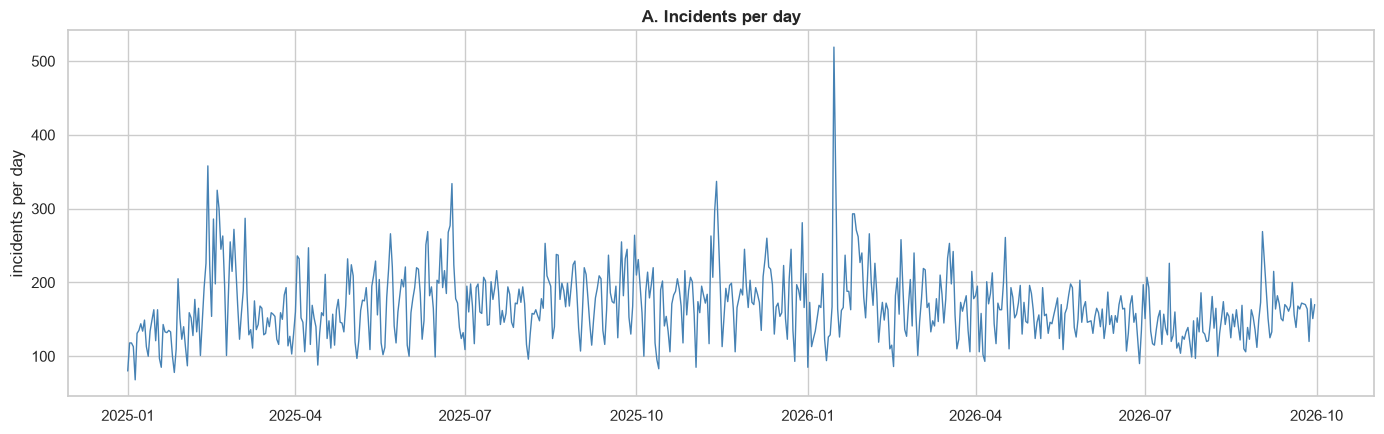

In [3]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(daily["date"], daily["n_incidents"], color="steelblue", lw=1)
ax.set(title="A. Incidents per day", xlabel="", ylabel="incidents per day")
plt.tight_layout()

**What you see:** each point is one day. A normal day has about 170 incidents (median 163), and most days sit between 100 and 250.

**What stands out:** a few days shoot far above the rest. The worst is **2026-01-15 with 519 incidents**, about three times a normal day.
Next come 2025-02-13 (358), 2025-11-13 (337), 2026-01-16 (336) and 2025-06-24 (334). The quietest days are early January 2025 (68 to 85 incidents).

**Why it matters:** the line zig-zags a lot, so it is hard to see the trend. The next chart smooths it.

### 1B. Daily line + 7-day average
The grey line is the raw day; the blue line is the average of the surrounding 7 days (centred), so it shows the level
without the weekday rhythm. The three busiest days are labelled.

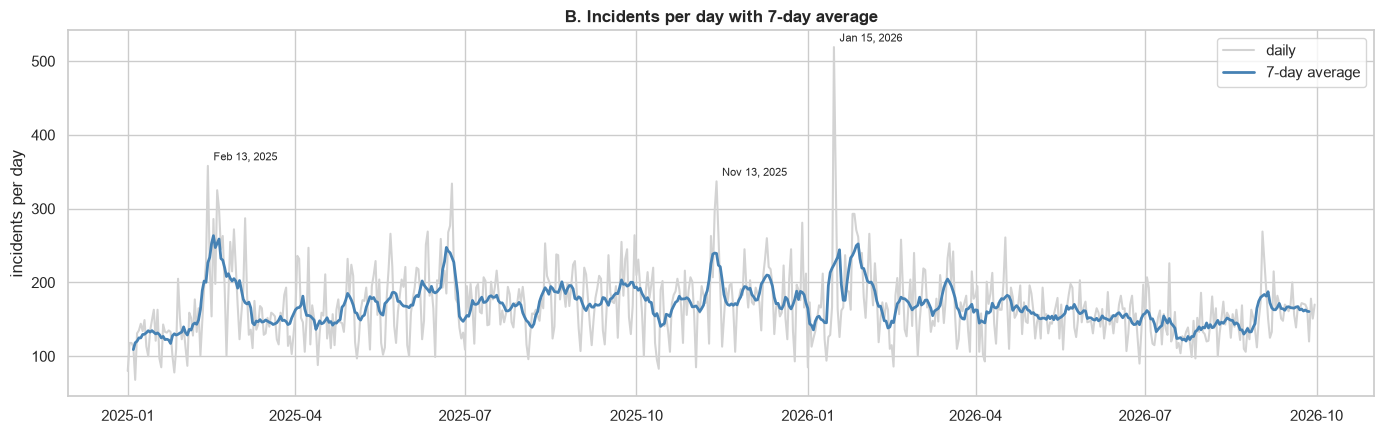

In [4]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(daily["date"], daily["n_incidents"], color="lightgray", label="daily")
ax.plot(daily["date"], daily["n_incidents"].rolling(7, center=True).mean(), color="steelblue", lw=2, label="7-day average")
for _, row in daily.nlargest(3, "n_incidents").iterrows():
    ax.annotate(f"{row['date']:%b %d, %Y}", (row["date"], row["n_incidents"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set(title="B. Incidents per day with 7-day average", xlabel="", ylabel="incidents per day")
ax.legend()
plt.tight_layout()

**How to read it:** the grey line is the raw day. The blue line is the average of the surrounding week, so the Monday-to-Sunday ups and downs cancel out. What is left is the *level* of service trouble.

**What stands out:**
- Three clear bumps: **mid-February 2025**, **mid-November 2025** and **January to February 2026**. In each, the weekly level jumps from about 150 to 250 incidents a day.
- Most of 2025 sits at 150 to 200 a day. In 2026 the level drifts down, to about 140 in July and August.
  Averaged over each year, 2025 has 172 incidents a day and 2026 has 162.
- The very start of January 2025 is low (about 125), which could be the holiday period or just how logging began. We can't tell from this chart.

**Why it matters:** the "normal" level is not constant. If we compared an event day in 2025 with a non-event day in 2026, part of the difference would just be this drift.

### 1C. Monthly bars
Left: total incidents per month. Months have different lengths, and the first and last month are not
comparable in total, so the right panel shows incidents **per day**, which is the fairer comparison.

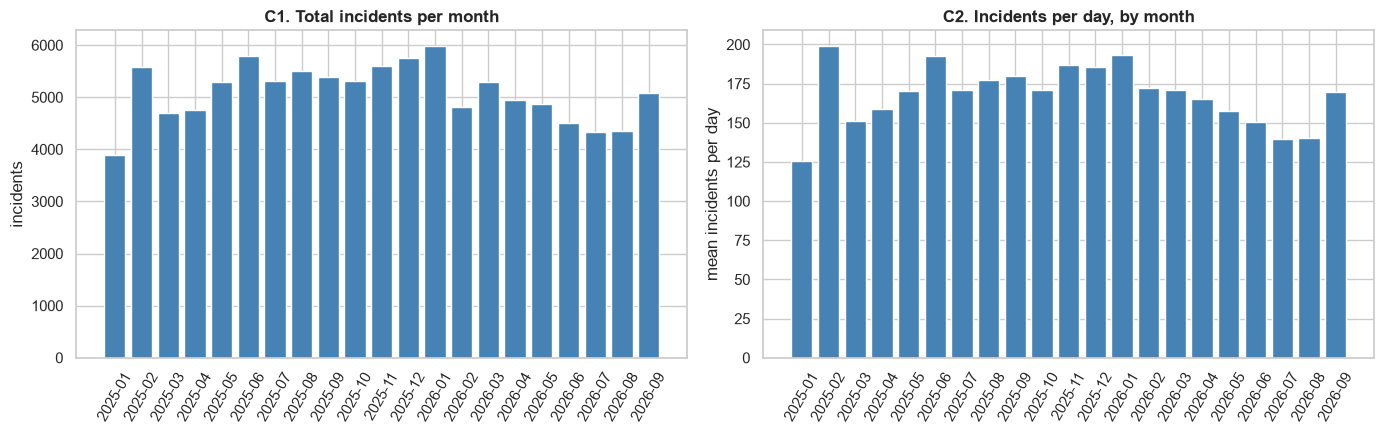

In [5]:
monthly = daily.groupby(daily["date"].dt.to_period("M")).agg(
    total=("n_incidents", "sum"), days=("date", "size"), per_day=("n_incidents", "mean")
)
months = monthly.index.astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(months, monthly["total"], color="steelblue")
axes[0].set(title="C1. Total incidents per month", ylabel="incidents")
axes[1].bar(months, monthly["per_day"], color="steelblue")
axes[1].set(title="C2. Incidents per day, by month", ylabel="mean incidents per day")
for ax in axes:
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()

**How to read it:** the left panel counts incidents per month. The right panel divides by the number of days in the month, which is the fairer comparison, because February is shorter than July.

**What stands out (right panel):**
- The busiest months are **February 2025 (199 a day)**, June 2025 (193) and January 2026 (193). The quietest are **January 2025 (126)** and **July and August 2026 (140)**.
- Summer 2026 is clearly quieter than summer 2025 (140 vs 171 to 193 a day). With under two years of data we cannot say if that is a trend or a one-off.
- The left panel is misleading for January 2025, which looks very low in total partly because it is the first month. Use the right panel when comparing months.

**Why it matters:** months differ by up to 50%, and baseball season (summer) and hockey season (winter) fall in different months. Month will need to be a control in notebook 03.

### 1D. Calendar heatmap
One cell = one day. Columns are weeks, rows are weekdays, colour = incidents. Dark cells are spike days;
the light Saturday and Sunday rows show the weekday pattern.

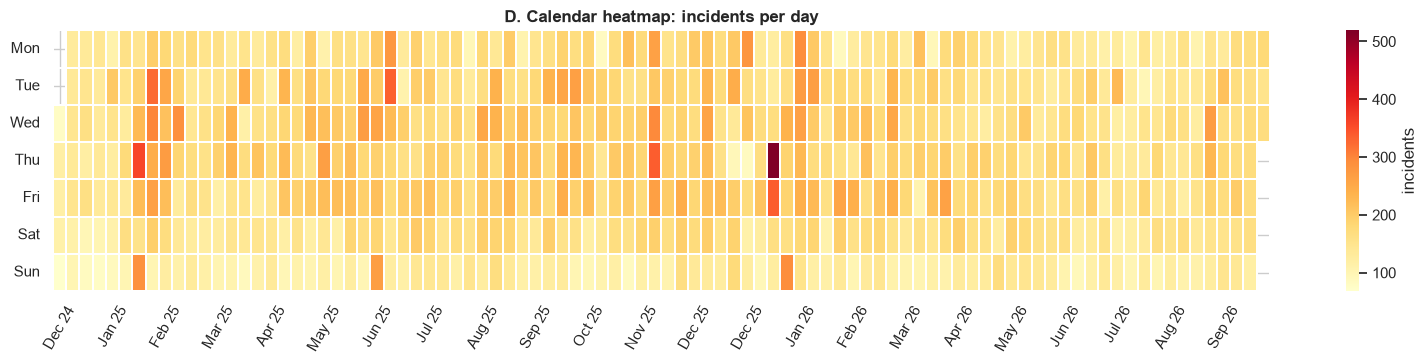

In [6]:
cal = daily.assign(week=daily["date"].dt.to_period("W-SUN").dt.start_time, weekday_no=daily["date"].dt.day_of_week)
grid = cal.pivot(index="weekday_no", columns="week", values="n_incidents")

fig, ax = plt.subplots(figsize=(16, 3.8))
sns.heatmap(grid, cmap="YlOrRd", ax=ax, linewidths=0.3, linecolor="white", cbar_kws={"label": "incidents"})
ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
ax.set_xticks(np.arange(0, grid.shape[1], 4) + 0.5)
ax.set_xticklabels([week.strftime("%b %y") for week in grid.columns[::4]], rotation=60)
ax.set(title="D. Calendar heatmap: incidents per day", xlabel="", ylabel="")
plt.tight_layout()

**How to read it:** one square is one day. Columns are weeks (left to right through time), rows are weekdays, and darker red means more incidents.

**What stands out:**
- The darkest squares are the spike days from chart 1A. Three of the five biggest (2025-02-13, 2025-11-13 and 2026-01-15) were **Thursdays**, so the spikes are isolated bad days, not whole bad weeks.
- The **weekday pattern** shows as pale rows. Sundays are the lightest (about 125 incidents on average), then Saturday (155) and Monday (158). Tuesday to Friday are the busiest at 180 to 187.
  A Friday has about 50% more incidents than a Sunday.

**Why it matters:** Sports games happen on all days of the week, but more often on evenings and weekends. Weekday must be controlled, or "events" would look like quiet days (more weekend games) when it is just the weekday.

### Step 1 takeaways
- A typical day has **about 170 incidents**. Days range from about 70 to 520.
- Three things move the level: **weekday** (Sunday 125 vs Friday 187), **time of year** (February 2025, June 2025 and winter 2025-26 are higher; summer 2026 is lower), and a few **extreme days** (Jan 15, 2026 is the worst).
- The level drifts over time, so event days must be compared with non-event days from **similar weekdays and months**, not with the overall average.
- Extreme days could dominate an average. We will look at what caused them in the weather step.

*(Numbers in the notes above come from the data as run on this version; if the data in notebook 01 changes, re-check them.)*

## Step 2. How long are the delays?

`min_delay` = minutes of delay logged for an incident (0 = incident logged, no delay). `min_gap` = minutes between buses.
Many views of the same question are shown on purpose; we decide later which ones to keep.

### 2.0 Summary numbers

In [7]:
delayed = incidents[incidents["is_delay"]]
stats = pd.DataFrame({
    "all incidents": incidents["min_delay"].describe(percentiles=[.5, .9, .99]),
    "only delay > 0": delayed["min_delay"].describe(percentiles=[.5, .9, .99]),
    "delay_capped (all)": incidents["delay_capped"].describe(percentiles=[.5, .9, .99]),
}).round(1)
print(f"Zero-delay incidents: {(~incidents['is_delay']).sum():,} ({(~incidents['is_delay']).mean():.1%}) | "
      f"over 120 min: {(incidents['min_delay'] > 120).sum():,} | 997-999 min: {(incidents['min_delay'] >= 997).sum()}")
stats

Zero-delay incidents: 13,774 (12.9%) | over 120 min: 2,412 | 997-999 min: 3


,all incidents,only delay > 0,delay_capped (all)
count,107049.0,93275.0,107049.0
mean,21.5,24.7,19.7
std,54.7,57.9,35.9
min,0.0,1.0,0.0
50%,12.0,14.0,12.0
90%,30.0,30.0,30.0
99%,261.5,294.0,261.5
max,999.0,999.0,294.0


**In plain words:** *Delay* is how many minutes the service was held up. About **13% of incidents (13,774) have zero delay**: staff logged a problem, but no delay was recorded.

**What the table says:** among incidents with a delay, the typical (median) delay is **14 minutes**. 9 in 10 are **30 minutes or less**. But the average is higher (24.7) and the maximum is 999, so a small number of very long incidents pull the average up. The 99th percentile is 294 minutes, so in notebook 01 we cap all delays at 294 (`delay_capped`) to stop a handful of cases dominating totals.

**Why it matters:** "average delay" is a poor summary here. The median, and counts of incidents, are safer.

### 2A. Histogram, delays up to 120 min (linear scale)
The bulk of the data. Bars are 1 minute wide.

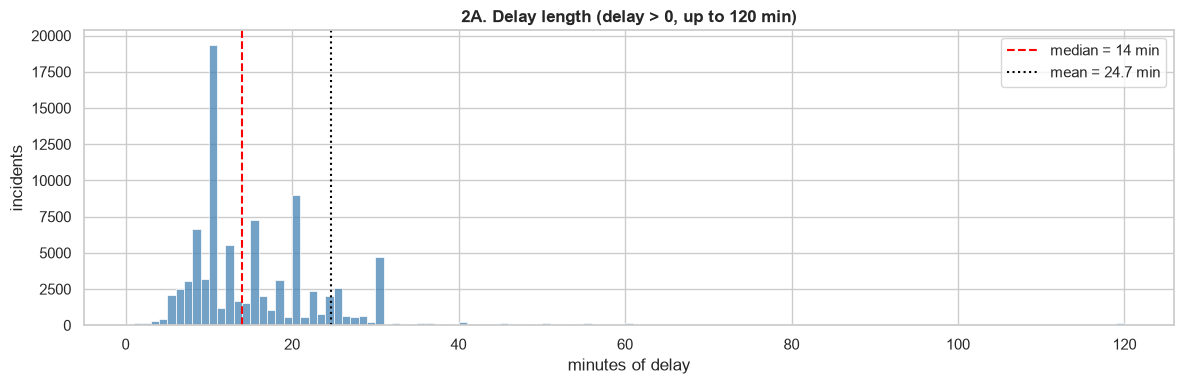

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(delayed.loc[delayed["min_delay"] <= 120, "min_delay"], binwidth=1, color="steelblue", ax=ax)
ax.axvline(delayed["min_delay"].median(), color="red", ls="--", label=f"median = {delayed['min_delay'].median():.0f} min")
ax.axvline(delayed["min_delay"].mean(), color="black", ls=":", label=f"mean = {delayed['min_delay'].mean():.1f} min")
ax.set(title="2A. Delay length (delay > 0, up to 120 min)", xlabel="minutes of delay", ylabel="incidents")
ax.legend()
plt.tight_layout()

**How to read it:** each bar counts the incidents with that many minutes of delay. The red line is the median (14) and the black dotted line is the mean (24.7).

**What stands out:** most delays are short. The pile is highest around 10 minutes, and **41% of delays are 10 minutes or shorter**. The mean sits to the right of the median because a minority of long incidents pull it up.

**Why it matters:** this shape (a big peak plus a long right tail) is typical of delays. It means differences in the *mean* between groups can be driven by a few long incidents, not by the typical case.

### 2B. Histogram on a log scale, all delays
Shows the long tail (up to 999 min) that 2A cuts off.

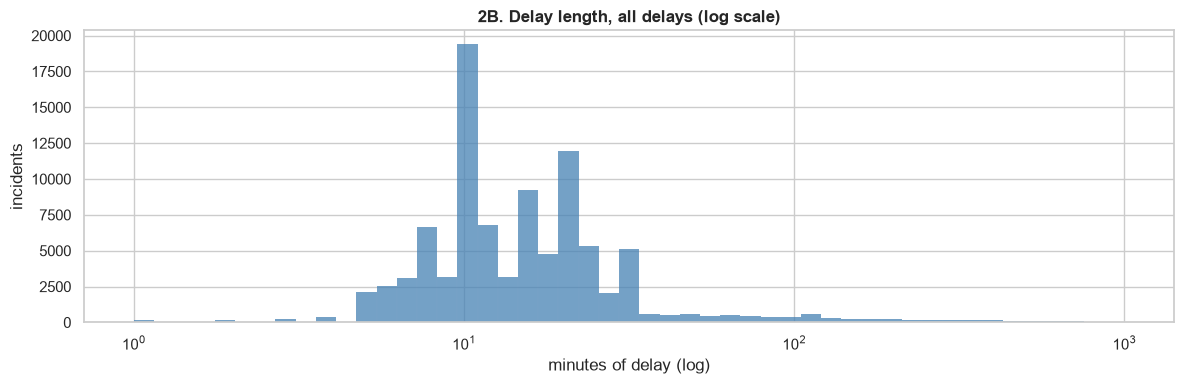

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(delayed["min_delay"], bins=np.logspace(0, 3, 50), color="steelblue", ax=ax)
ax.set(xscale="log", title="2B. Delay length, all delays (log scale)", xlabel="minutes of delay (log)", ylabel="incidents")
plt.tight_layout()

**How to read it:** same data as 2A, but the bottom axis is stretched on a log scale (each step is 10 times bigger), so we can see all delays up to 999 minutes in one picture.

**What stands out:** the bulk is still under 30 minutes, but a thin tail runs out to several hours. Only **2.6% of delayed incidents are longer than 2 hours**, but they are the cases that matter most for total delay.

**Why it matters:** the tail is real, not just noise. We will see in 2P what these long incidents are.

### 2C. Share of incidents by delay-size bucket
A simple bar view that is easy to explain to a non-technical reader.

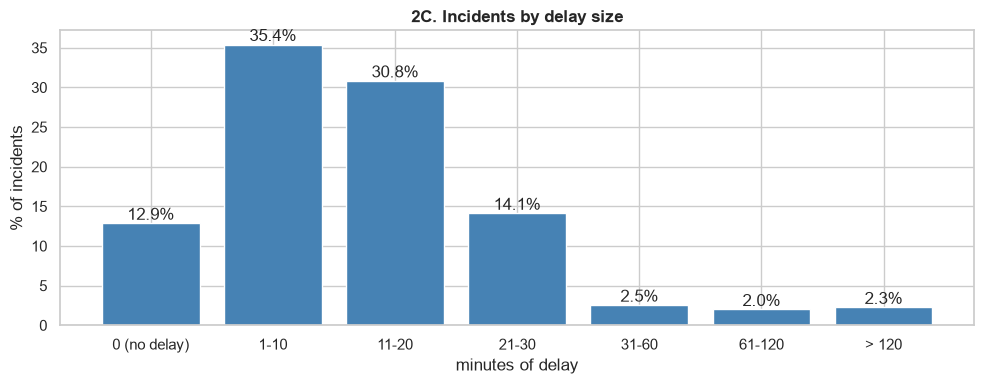

In [10]:
buckets = pd.cut(incidents["min_delay"], [-1, 0, 10, 20, 30, 60, 120, 1000],
                 labels=["0 (no delay)", "1-10", "11-20", "21-30", "31-60", "61-120", "> 120"])
bucket_share = buckets.value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(bucket_share.index.astype(str), bucket_share * 100, color="steelblue")
ax.bar_label(bars, fmt="%.1f%%")
ax.set(title="2C. Incidents by delay size", xlabel="minutes of delay", ylabel="% of incidents")
plt.tight_layout()

**How to read it:** all incidents sorted into buckets by delay length. The bars add up to 100%.

**What stands out:** the three buckets from 1 to 30 minutes hold **80% of incidents** (35% + 31% + 14%). Another 13% have no delay. Only **4.8% are longer than an hour** and 2.3% are longer than 2 hours.

**Why it matters:** this is the easiest chart to explain to a non-technical reader: "most incidents are short; a few are very long".

### 2D. Cumulative distribution (ECDF)
Read as: 'x % of incidents are shorter than y minutes'. Good for picking thresholds.

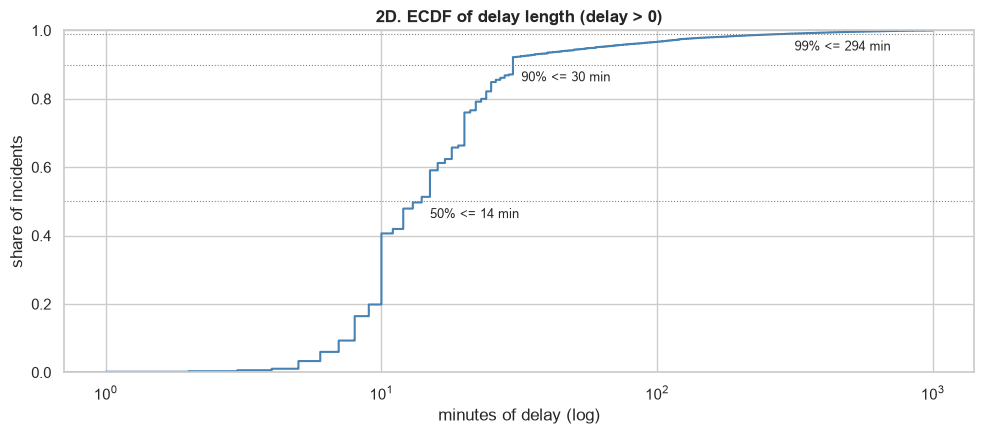

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.ecdfplot(delayed["min_delay"], ax=ax, color="steelblue")
for q in (0.5, 0.9, 0.99):
    value = delayed["min_delay"].quantile(q)
    ax.axhline(q, color="gray", ls=":", lw=0.8)
    ax.annotate(f"{q:.0%} <= {value:.0f} min", (value, q), xytext=(6, -12), textcoords="offset points", fontsize=9)
ax.set(xscale="log", title="2D. ECDF of delay length (delay > 0)", xlabel="minutes of delay (log)", ylabel="share of incidents")
plt.tight_layout()

**How to read it:** pick a point on the bottom axis, say 30 minutes; the height of the line there is the share of delayed incidents that are 30 minutes or shorter. The horizontal dotted lines mark 50%, 90% and 99%.

**What stands out:** half of the incidents are 14 minutes or less, 90% are 30 minutes or less, and 99% are 294 minutes or less. The line is very steep up to 30 minutes, then it crawls: **the last 9% of incidents spread from 30 to almost 300 minutes**.

**Why it matters:** this is how we can choose thresholds, for example "long delay = more than 30 minutes" would cover the worst 10%.

### 2E. Concentration: do a few long incidents hold most delay minutes?
Incidents are sorted from shortest to longest. The curve shows what share of all delay minutes the shortest x % of incidents hold.
The further the curve sits below the diagonal, the more the total is dominated by a few long incidents.

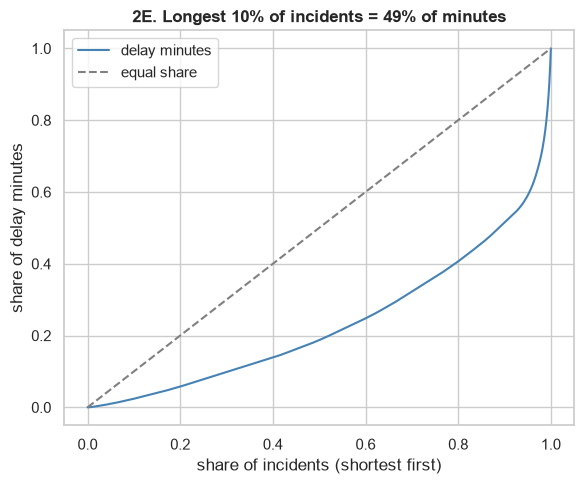

In [12]:
sorted_delay = np.sort(delayed["min_delay"].to_numpy())
share_minutes = np.cumsum(sorted_delay) / sorted_delay.sum()
share_incidents = np.arange(1, len(sorted_delay) + 1) / len(sorted_delay)
top10_share = sorted_delay[int(0.9 * len(sorted_delay)):].sum() / sorted_delay.sum()

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(share_incidents, share_minutes, color="steelblue", label="delay minutes")
ax.plot([0, 1], [0, 1], color="gray", ls="--", label="equal share")
ax.set(title=f"2E. Longest 10% of incidents = {top10_share:.0%} of minutes", xlabel="share of incidents (shortest first)", ylabel="share of delay minutes")
ax.legend()
plt.tight_layout()

**How to read it:** line up all delayed incidents from shortest to longest. The curve shows what share of all delay minutes the shortest x% of incidents hold. If delays were all the same length, the curve would follow the dashed diagonal.

**What stands out:** the curve sags well below the diagonal. The shortest half of incidents hold less than a fifth of all delay minutes, while the **longest 10% hold about 49%**. The curve bends up sharply at the end.

**Why it matters:** total delay minutes are driven by a few long incidents. To compare event days with normal days, we should look at both *how many* incidents and *how long* they are, and not just total minutes.

### 2F. Rounded values: what do staff actually enter?
Delays are typed in by hand, so some values (10, 15, 20, 30) are far more common than their neighbours.

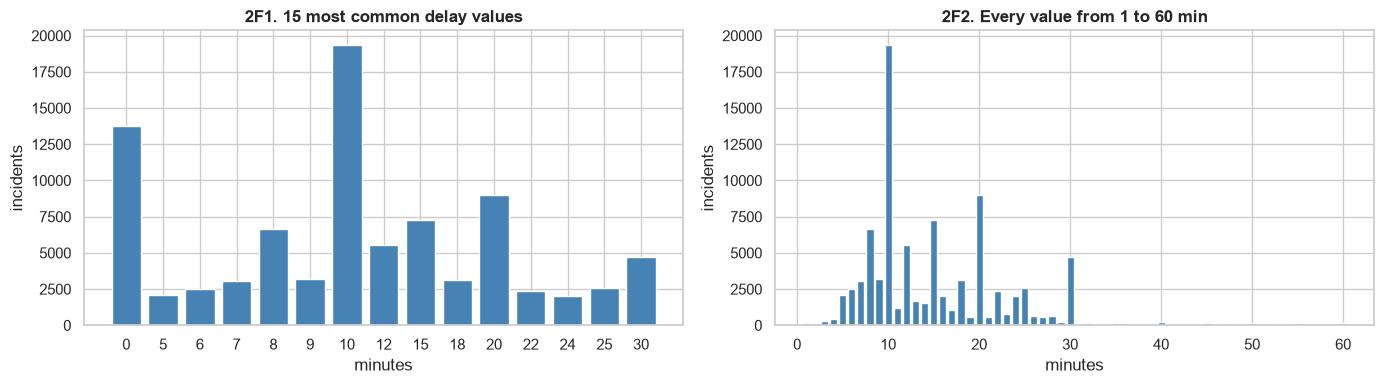

In [13]:
common = incidents["min_delay"].value_counts().head(15).sort_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(common.index.astype(str), common.values, color="steelblue")
axes[0].set(title="2F1. 15 most common delay values", xlabel="minutes", ylabel="incidents")
counts = incidents.loc[incidents["min_delay"].between(1, 60), "min_delay"].value_counts().sort_index()
axes[1].bar(counts.index, counts.values, color="steelblue")
axes[1].set(title="2F2. Every value from 1 to 60 min", xlabel="minutes", ylabel="incidents")
plt.tight_layout()

**How to read it:** the left panel shows the 15 most common delay values. The right panel shows every value from 1 to 60 minutes.

**What stands out:** delays are **rounded by whoever types them in**. Ten minutes is by far the most common value (19,387 incidents, about 1 in 5 delayed incidents), followed by 20, 15 and 8. Tall spikes at 10, 15, 20, 25 and 30 stand out against much lower neighbours (for example 11 is rare). **10, 15, 20 and 30 minutes together make up 43% of all delayed incidents.** The tall bar at 0 is the 13,774 no-delay incidents.

**Why it matters:** delay minutes are estimates, not stopwatch readings. Small differences (say 12 vs 13 minutes) mean nothing; only bigger differences are worth reading.

### 2G. Delay by cause group (boxplot, log scale)
Box = middle 50%, line = median. Delay > 0 only.

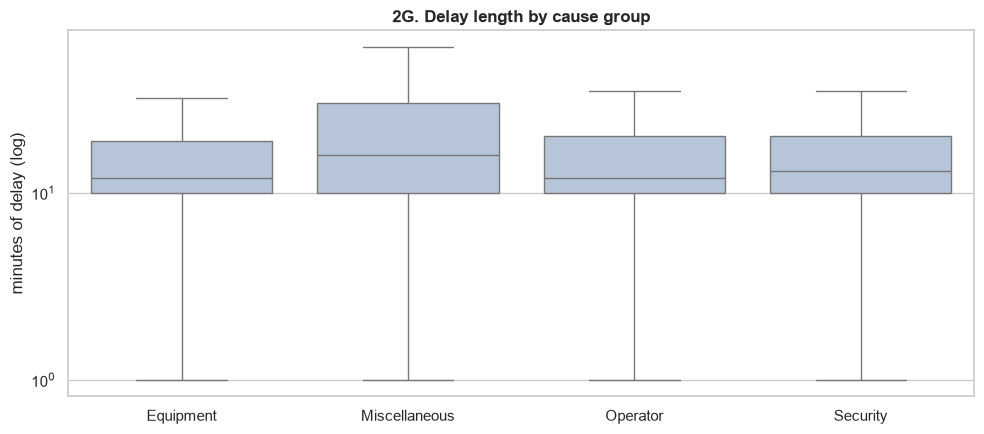

In [14]:
group_order = delayed["cause_group"].value_counts().index
group_order = [g for g in group_order if (delayed["cause_group"] == g).sum() >= 100]  # drop tiny groups

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=delayed[delayed["cause_group"].isin(group_order)], x="cause_group", y="min_delay", order=group_order,
            color="lightsteelblue", showfliers=False, ax=ax)
ax.set(yscale="log", title="2G. Delay length by cause group", xlabel="", ylabel="minutes of delay (log)")
plt.tight_layout()

**How to read it:** each box covers the middle half of the delays in that cause group. The line inside is the median. The whiskers show the usual range. The bottom axis is log scale.

**What stands out:** Equipment, Operator and Security look alike (median 12 to 13 minutes). **Miscellaneous is different**: higher median (16 minutes) and a much taller box, so its delays are more spread out. Its 90th percentile is **100 minutes**, versus 24 to 27 for the other groups.

**Why it matters:** the cause of an incident matters for how long it lasts. Miscellaneous is where diversions and similar road-related causes live, so this is the group to watch for event effects.

### 2H. Delay by cause group (violin)
Same data as 2G, but shows the whole shape of the distribution.

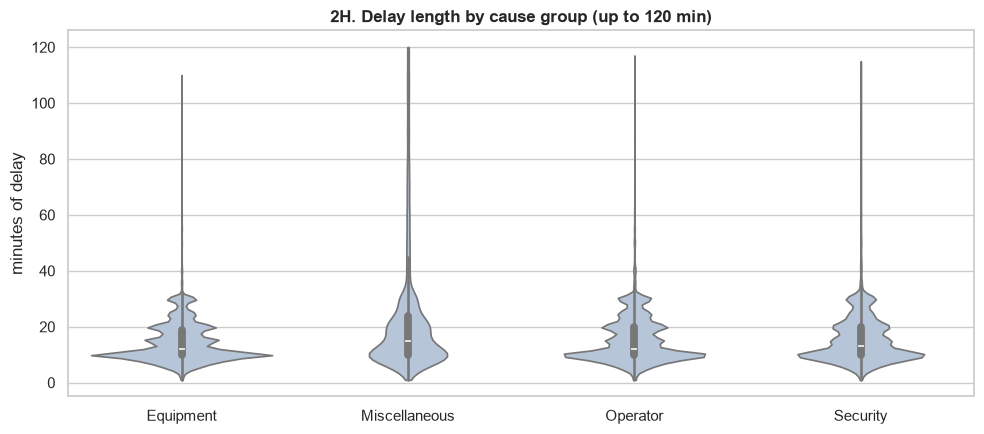

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.violinplot(data=delayed[delayed["cause_group"].isin(group_order) & (delayed["min_delay"] <= 120)],
               x="cause_group", y="min_delay", order=group_order, color="lightsteelblue", cut=0, ax=ax)
ax.set(title="2H. Delay length by cause group (up to 120 min)", xlabel="", ylabel="minutes of delay")
plt.tight_layout()

**How to read it:** same comparison as 2G, but each shape shows the full spread: a wider part means more incidents at that delay length.

**What stands out:** Equipment, Operator and Security are fat at the bottom (most incidents under 30 minutes) and thin above. **Miscellaneous has a long thin neck**: many more incidents between 30 and 120 minutes. Averages: Miscellaneous 44.9 minutes versus 14 to 16 for the others.

**Why it matters:** this is the same message as 2G in a different picture: Miscellaneous is where the long delays are.

### 2I. Share with a delay, and typical delay, by cause group
Two numbers per group: how often an incident causes a delay at all, and how long the delay is when it does.

,share_delayed,median_delay,incidents
cause_group,,,
Equipment,0.98,12.0,34800
Miscellaneous,0.79,16.0,38646
Operator,0.90,12.0,25420
Security,0.69,13.0,8122


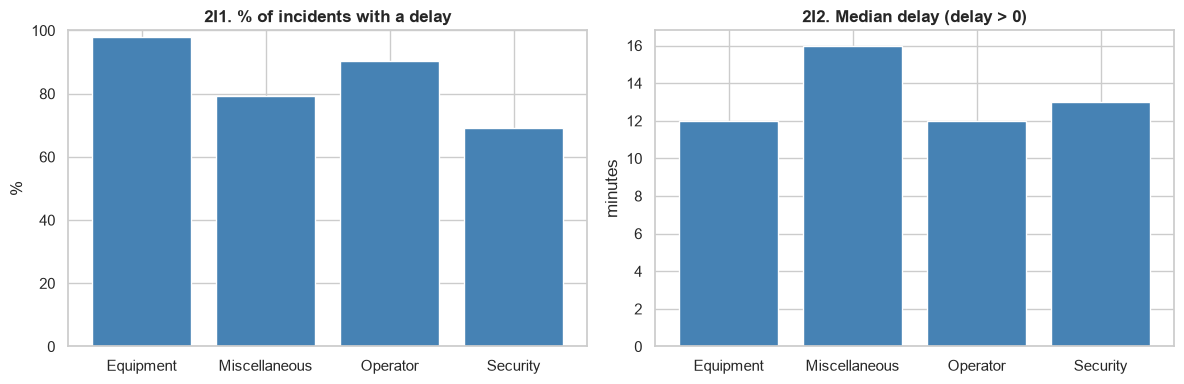

In [16]:
by_group = incidents[incidents["cause_group"].isin(group_order)].groupby("cause_group").agg(
    share_delayed=("is_delay", "mean"), median_delay=("min_delay", lambda s: s[s > 0].median()), incidents=("code", "size")
).loc[group_order]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(by_group.index, by_group["share_delayed"] * 100, color="steelblue")
axes[0].set(title="2I1. % of incidents with a delay", ylabel="%", ylim=(0, 100))
axes[1].bar(by_group.index, by_group["median_delay"], color="steelblue")
axes[1].set(title="2I2. Median delay (delay > 0)", ylabel="minutes")
plt.tight_layout()
by_group.round(2)

**How to read it:** the left panel shows how often an incident in each cause group causes any delay. The right panel shows the median delay when it does.

**What stands out:** the likelihood of a delay varies a lot by cause: **Equipment 98%, Operator 90%, Miscellaneous 79%, Security 69%.** But when there is a delay, the typical length is about the same (12 to 16 minutes).

**Why it matters:** a cause can change *whether* a delay happens and *how long* it is. The two should be looked at separately.

### 2J. Delay length over time (monthly)
Median, mean and 90th percentile of delay per month. Checks whether the size of delays drifts.

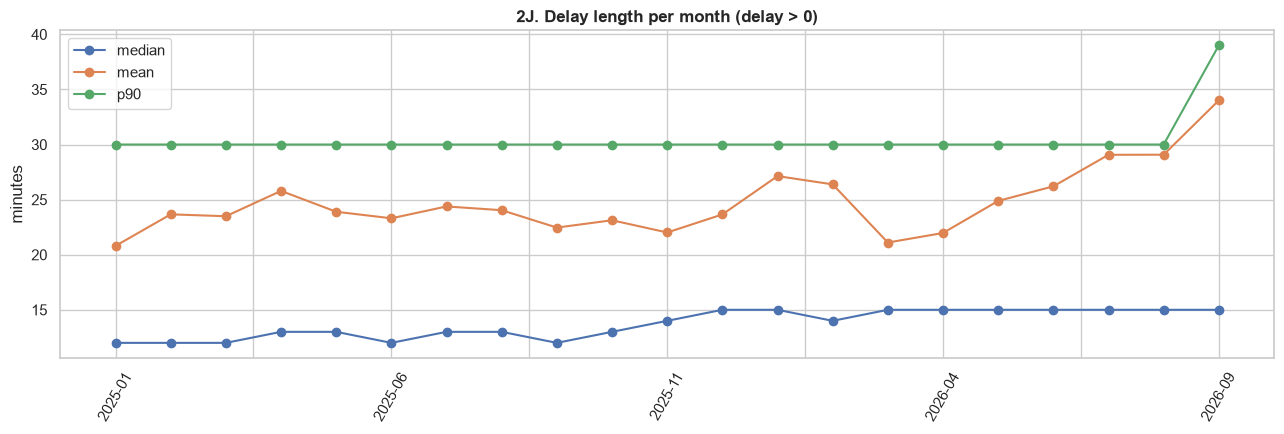

In [17]:
month = incidents["date"].dt.to_period("M").astype(str)
monthly_delay = incidents[incidents["is_delay"]].groupby(month[incidents["is_delay"]])["min_delay"].agg(
    median="median", mean="mean", p90=lambda s: s.quantile(0.9)
)
fig, ax = plt.subplots(figsize=(13, 4.5))
monthly_delay.plot(ax=ax, marker="o")
ax.set(title="2J. Delay length per month (delay > 0)", xlabel="", ylabel="minutes")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()

**How to read it:** for each month: the median delay (typical), the mean (pulled by long cases) and the 90th percentile (the "long" end).

**What stands out:**
- The **median rises from 12 minutes** in early 2025 to **15 minutes** from December 2025 on, and then stays there.
- The **mean climbs in summer 2026**: 29 in July and August, and **34 in September 2026**. The 90th percentile jumps to 39 in September too. September 2026 has more very long delays than any other month (see 2P).
- The 90th percentile is otherwise fixed at 30, because staff round to 30 (see 2F).

**Why it matters:** the length of delays is not constant over time, so a month-to-month comparison of delay minutes needs care. A step change in the median around December 2025 could be real, or it could be a change in how delays are logged. We check this in the cause-codes step.

### 2K. Share of incidents with a delay, per month
If this jumps, the way staff log delays may have changed (see Step 4 on cause codes).

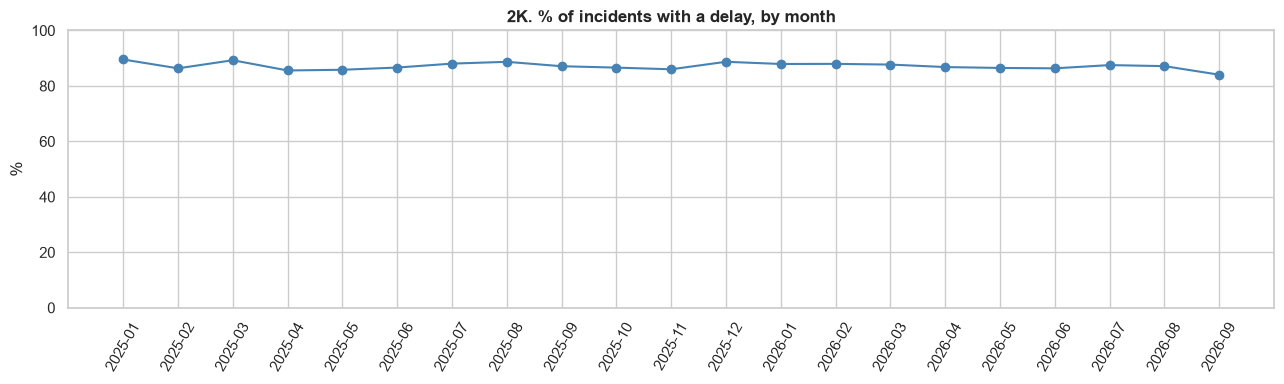

In [18]:
share_delayed_month = incidents.groupby(month)["is_delay"].mean() * 100
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(share_delayed_month.index, share_delayed_month.values, marker="o", color="steelblue")
ax.set(title="2K. % of incidents with a delay, by month", xlabel="", ylabel="%", ylim=(0, 100))
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()

**How to read it:** each point is the share of that month's incidents that carry a delay of more than 0 minutes.

**What stands out:** it is **flat, between 84% and 89% every month**. No jumps.

**Why it matters:** this is reassuring: whether a delay gets recorded at all has not changed over time, so counts of delayed incidents can be compared across months.

### 2L. Total delay minutes per day
The daily total mixes how many incidents there were with how long they were. The 7-day average smooths the weekday rhythm.

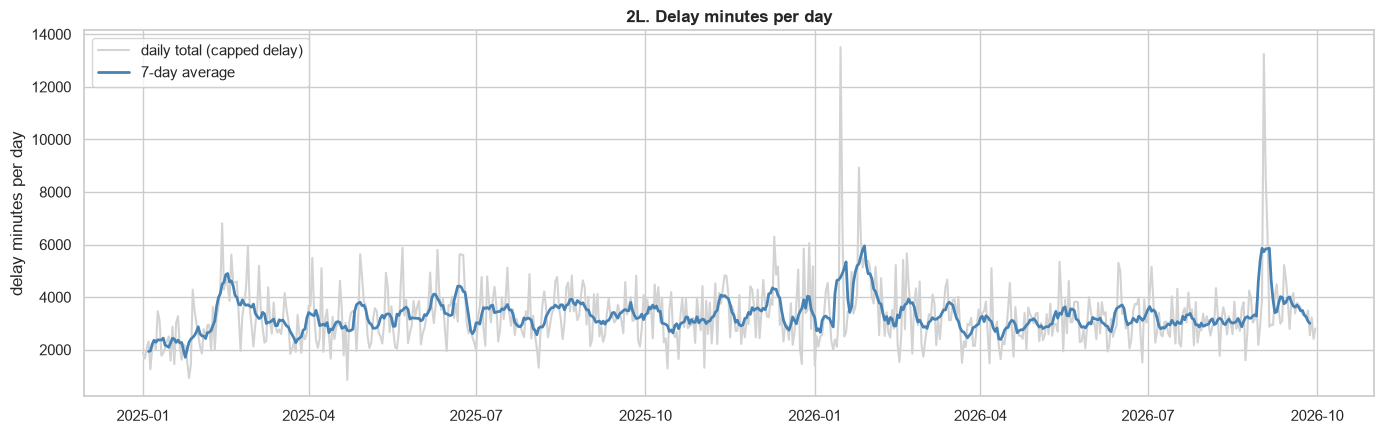

In [19]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(daily["date"], daily["delay_min_total"], color="lightgray", label="daily total (capped delay)")
ax.plot(daily["date"], daily["delay_min_total"].rolling(7, center=True).mean(), color="steelblue", lw=2, label="7-day average")
ax.set(title="2L. Delay minutes per day", xlabel="", ylabel="delay minutes per day")
ax.legend()
plt.tight_layout()

**How to read it:** same style as chart 1B but for total minutes of delay each day (delay capped at 294). The blue line is the 7-day average.

**What stands out:** a normal day has **3,000 to 4,000 delay minutes**. Three days are far above: **2026-01-15 (13,510 minutes)**, **2026-09-02 (13,247)** and 2026-01-25 (8,928). The same bump in February 2025 and January 2026 appears as in the incident counts.

**Why it matters:** 2026-09-02 looks ordinary in chart 1A (269 incidents) but is the second-worst day for delay minutes. It had few incidents but very long ones. Counting incidents and counting minutes can give different answers.

### 2M. Incidents per day vs delay minutes per day
One dot per day. If delay minutes just follow incident counts, the dots form a tight line.

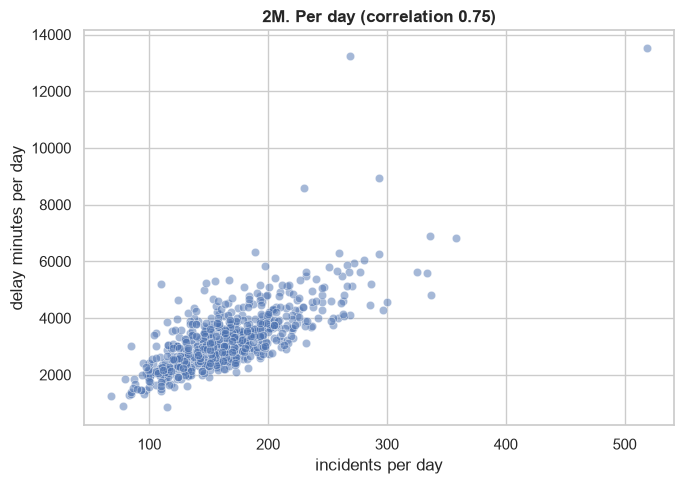

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=daily, x="n_incidents", y="delay_min_total", alpha=0.5, ax=ax)
ax.set(title=f"2M. Per day (correlation {daily['n_incidents'].corr(daily['delay_min_total']):.2f})",
       xlabel="incidents per day", ylabel="delay minutes per day")
plt.tight_layout()

**How to read it:** each dot is one day. Right means more incidents, up means more delay minutes. If minutes only followed counts, the dots would sit on a tight line.

**What stands out:** there is a clear upward trend (correlation 0.75): days with more incidents have more delay minutes. But the cloud is wide. The dot far above the rest is **2026-09-02: only 269 incidents but 13,247 minutes**.

**Why it matters:** about 56% (0.75 squared) of the day-to-day variation in minutes is explained by the number of incidents. The rest is *how long* they are. We should use both measures in notebook 03.

### 2N. Delay vs gap between buses
`min_gap` is the gap the incident created between buses. One hexagon bin = many incidents (log colour).

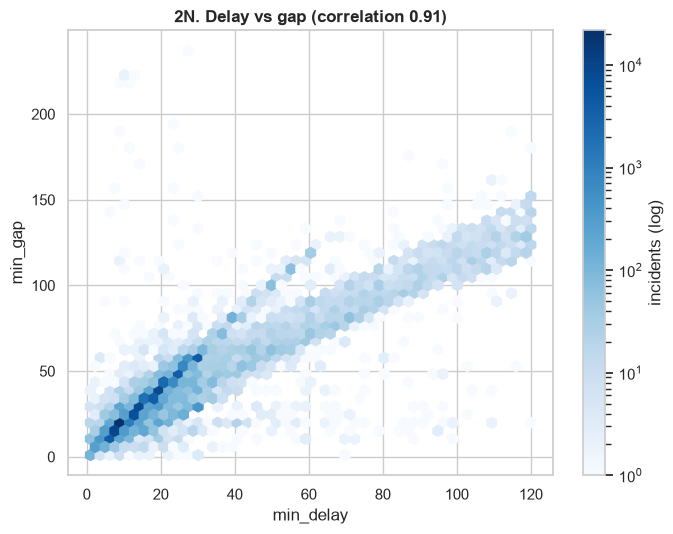

In [21]:
both = incidents[(incidents["min_gap"] > 0) & (incidents["min_delay"] > 0) & (incidents["min_delay"] <= 120) & (incidents["min_gap"] <= 240)]
fig, ax = plt.subplots(figsize=(7, 5.5))
hb = ax.hexbin(both["min_delay"], both["min_gap"], gridsize=45, bins="log", cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=ax, label="incidents (log)")
ax.set(title=f"2N. Delay vs gap (correlation {both['min_delay'].corr(both['min_gap']):.2f})", xlabel="min_delay", ylabel="min_gap")
plt.tight_layout()

**How to read it:** each hexagon is a small area on the chart; darker means more incidents fall there. Right means longer delay, up means a longer gap between buses.

**What stands out:** a tight diagonal band (correlation 0.91): the longer the delay, the longer the gap. In every incident that has both numbers the **gap is at least as long as the delay**, typically about twice as long (median gap 26 minutes vs median delay 14).

**Why it matters:** `min_gap` tells us almost the same story as `min_delay`. We can use `min_delay` alone and ignore `min_gap`.

### 2O. Delay: routes near a venue vs other routes
A first look at the location columns from notebook 01. Routes missing from the GTFS feed are left out.

,size,median,mean
where,,,
other routes,84100,14.0,24.3
route near a venue,7993,10.0,28.3


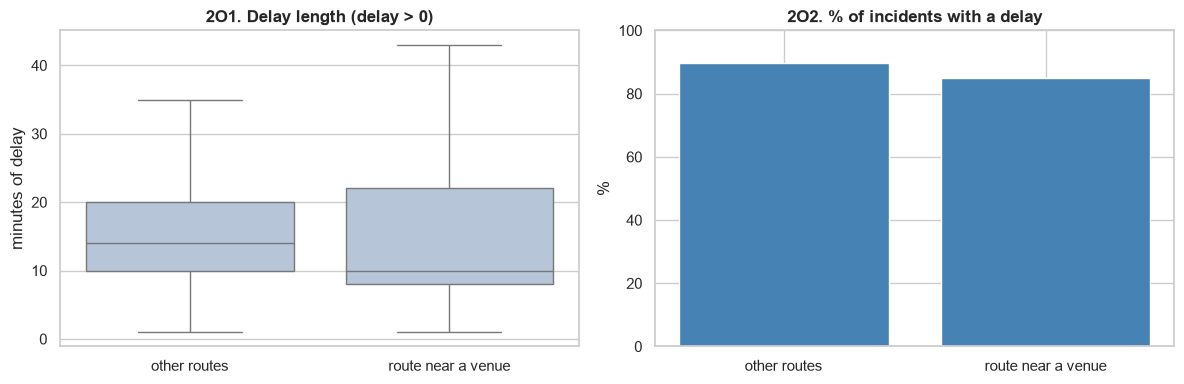

In [22]:
located = delayed.dropna(subset=["near_venue"]).assign(
    where=lambda t: np.where(t["near_venue"], "route near a venue", "other routes")
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=located, x="where", y="min_delay", color="lightsteelblue", showfliers=False, ax=axes[0])
axes[0].set(title="2O1. Delay length (delay > 0)", xlabel="", ylabel="minutes of delay")
share = incidents.dropna(subset=["near_venue"]).groupby("near_venue")["is_delay"].mean() * 100
axes[1].bar(["other routes", "route near a venue"], share.values, color="steelblue")
axes[1].set(title="2O2. % of incidents with a delay", ylabel="%", ylim=(0, 100))
plt.tight_layout()
located.groupby("where")["min_delay"].agg(["size", "median", "mean"]).round(1)

**How to read it:** the left panel compares delay lengths on routes that have a stop within 1 km of a venue (Rogers Centre, Scotiabank Arena, BMO Field) with all other routes. The right panel shows how often an incident causes a delay.

**What stands out:**
- The typical (median) delay is *shorter* near venues: **10 vs 14 minutes**. But the average is *longer* (28.3 vs 24.3), and 3.9% of delays near venues exceed 2 hours, versus 2.4% elsewhere.
- Near-venue routes are a bit less likely to have a delay logged at all: 85% vs 90%.

**Why it matters:** near-venue routes have more short incidents, but also more very long ones. This is *not* an event effect yet: it compares routes on all days, with or without an event. It only tells us that "near a venue" is a meaningful grouping.

### 2P. The extreme values (over 120 min)
What are they? Which causes and which months? (997-999 look like placeholders.)

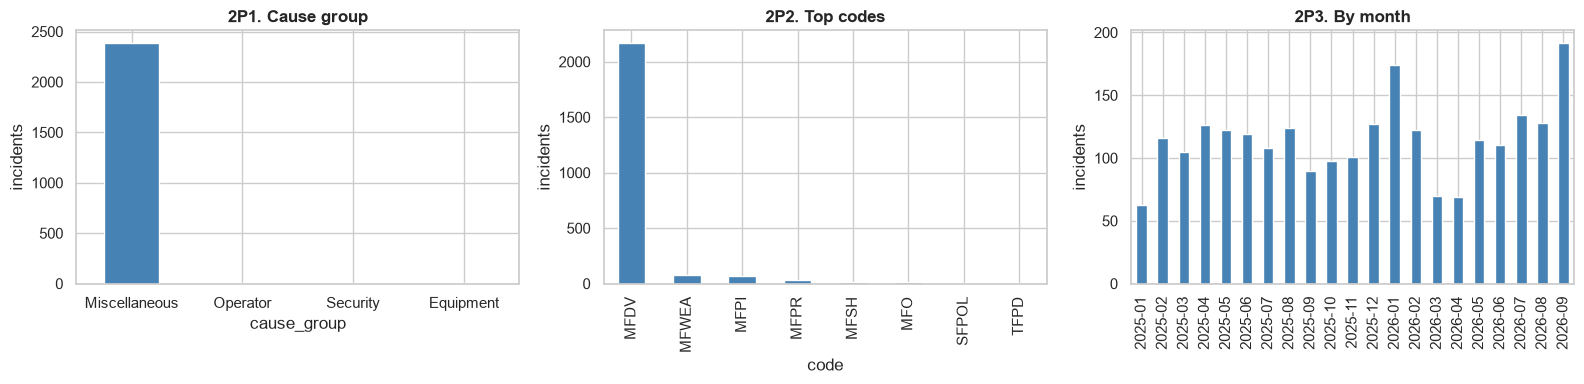

In [23]:
extreme = incidents[incidents["min_delay"] > 120]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
extreme["cause_group"].value_counts().plot.bar(ax=axes[0], color="steelblue", rot=0)
axes[0].set(title="2P1. Cause group", ylabel="incidents")
extreme["code"].value_counts().head(8).plot.bar(ax=axes[1], color="steelblue")
axes[1].set(title="2P2. Top codes", ylabel="incidents")
extreme.groupby(extreme["date"].dt.to_period("M").astype(str)).size().plot.bar(ax=axes[2], color="steelblue")
axes[2].set(title="2P3. By month", xlabel="", ylabel="incidents")
plt.tight_layout()

**How to read it:** the incidents with delays over 2 hours (2,412 of them), broken down by cause and by month.

**What stands out:**
- **Nearly all (2,391, or 99%) are Miscellaneous**, and **2,173 (90%) are one code: MFDV, "on diversion"**. The next codes are far behind (82, 66, 30). Parade holds (MFPR) account for only 30.
- They happen all year, about **100 to 130 a month**. Peaks: **January 2026 (174)** and **September 2026 (192, the most)**. The lowest months are January 2025 (63) and March and April 2026 (about 70).

**Why it matters:** the very long delays are mostly **diversions**. That links directly to the research question: events that close roads cause diversions. It also explains why September 2026 had the high mean delay in 2J. This is the group to follow in notebook 03.

### Step 2 takeaways
- A typical incident is **short**: median 14 minutes, 90% under 30. About 13% have no delay at all.
- Delays are **very uneven**: the longest 10% of incidents hold about half of all delay minutes. So the *mean* and the *total* are driven by a few cases. Use medians and counts, or the capped delay.
- Delay minutes are **rounded estimates** (10, 15, 20, 30), so only larger differences mean something.
- Long delays (over 2 hours) are almost all **diversions** (MFDV). This is the cause most tied to road closures and events.
- Counting incidents and counting minutes can disagree (2026-09-02: few incidents, huge minutes). Notebook 03 should look at both.
- `min_gap` repeats `min_delay`, so we can ignore it.

## Step 3. Hour of day

`hour` is the hour in which the incident was logged (0 = midnight to 1 am, Toronto time).
Event windows are defined by hours, so we need to know what a *normal* hour looks like first.

**One caution for the whole step:** we do not have data on how many buses are running at each hour. More buses on the road means more
chances for something to go wrong, so a busy hour is partly just a busier hour of service.

The `hourly` table has one row for every hour in the period, including hours with zero incidents, so averages per hour are not inflated.

In [24]:
hourly = pd.read_csv(PROCESSED / "hourly.csv", parse_dates=["datetime", "date"])
hourly["weekday"] = pd.Categorical(hourly["weekday"], categories=WEEKDAYS, ordered=True)
hourly["day_type"] = np.where(hourly["is_weekend"], "weekend", "weekday")
HOURS = range(24)

def period_of(hour):
    """Five broad parts of the day, used to colour and group charts."""
    return pd.cut(hour, [-1, 4, 9, 13, 18, 23], labels=["night (0-4)", "morning (5-9)", "midday (10-13)", "afternoon (14-18)", "evening (19-23)"])

PERIOD_COLORS = dict(zip(["night (0-4)", "morning (5-9)", "midday (10-13)", "afternoon (14-18)", "evening (19-23)"],
                         ["#4c4c7a", "#e8a33d", "#6aa84f", "#c0392b", "#7f6bb3"]))
avg_per_hour = hourly.groupby("hour")["n_incidents"].mean()
print(f"{len(hourly):,} hourly rows | an average hour has {hourly['n_incidents'].mean():.1f} incidents")

15,312 hourly rows | an average hour has 7.0 incidents


### 3A. Average incidents in each hour of the day
Bars are coloured by part of the day.

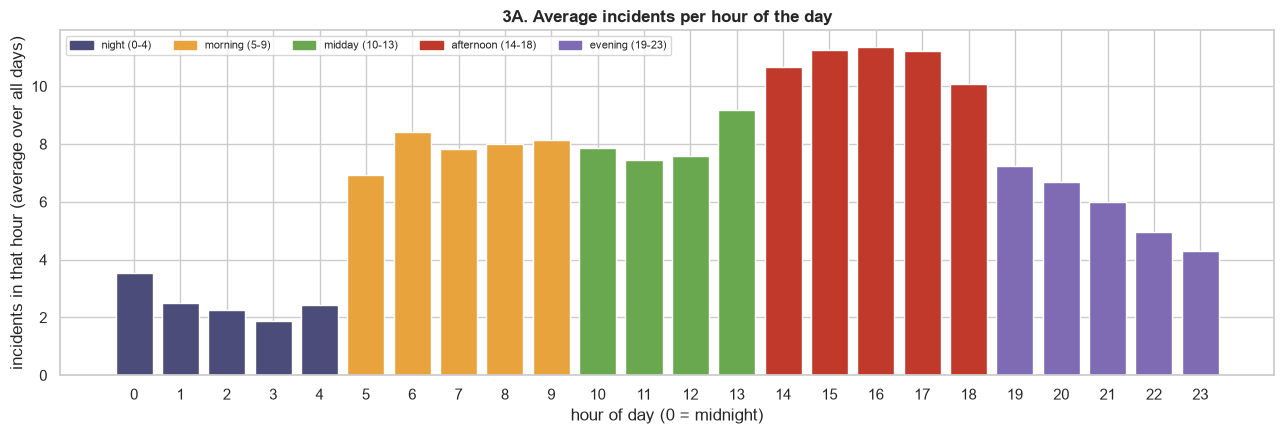

In [25]:
fig, ax = plt.subplots(figsize=(13, 4.5))
parts = period_of(pd.Series(list(HOURS)))
ax.bar(HOURS, avg_per_hour.values, color=[PERIOD_COLORS[p] for p in parts])
ax.set_xticks(list(HOURS))
ax.set(title="3A. Average incidents per hour of the day", xlabel="hour of day (0 = midnight)", ylabel="incidents in that hour (average over all days)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in PERIOD_COLORS.values()]
ax.legend(handles, PERIOD_COLORS.keys(), ncol=5, loc="upper left", fontsize=8)
plt.tight_layout()

**How to read it:** each bar is an average hour: for example, the bar at 16 means that between 4 pm and 5 pm there are about 11.4 incidents on an average day.

**What stands out:**
- **Night is quiet** (about 2 to 3.5 an hour, quietest 3 to 4 am) and then **jumps at 5 am**, from 2.4 to 6.9 incidents an hour. That is when buses start to run.
- The morning and midday plateau is steady at about 7 to 8 an hour (the 6 am hour is a bit higher, 8.4).
- A second, bigger step comes at **1 pm and 2 pm**, and the day peaks between **3 and 6 pm** (10 to 11.4 an hour, highest at 4 pm).
- After 6 pm it falls gradually through the evening.

**The surprise:** the busiest time is the **afternoon (2 to 6 pm), not the morning rush**. The afternoon has about 40% more incidents per hour than the morning.

**Why it matters:** many events (evening games) end around 9 to 11 pm, when the baseline is falling. Games that start at 7 pm have their pre-game window (5 to 7 pm) at the *end of the afternoon peak*. So event hours have a different baseline depending on the time, and must be compared with the same hour on other days.

### 3B. Weekday vs weekend
Same as 3A, but split by type of day.

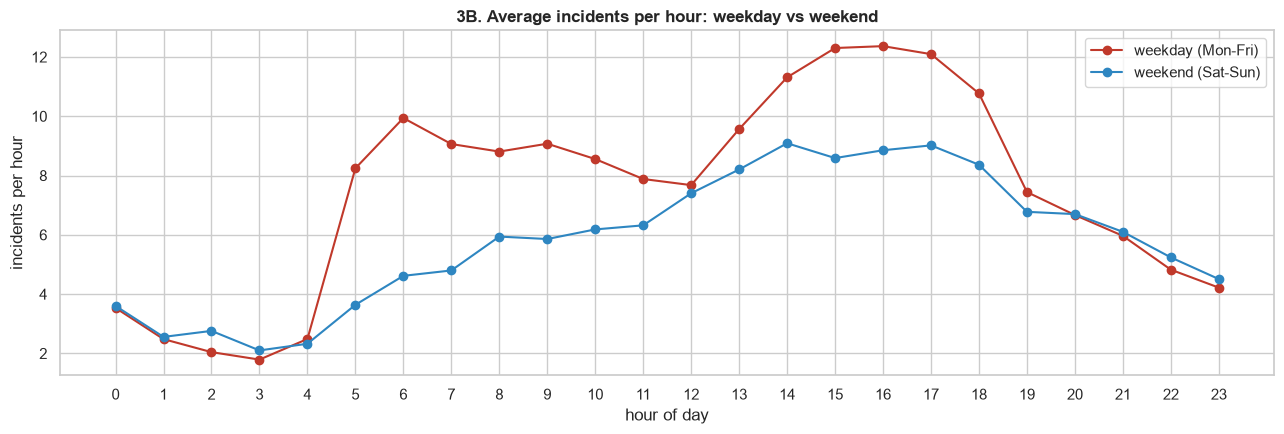

In [26]:
by_type = hourly.groupby(["day_type", "hour"])["n_incidents"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(by_type.index, by_type["weekday"], marker="o", color="#c0392b", label="weekday (Mon-Fri)")
ax.plot(by_type.index, by_type["weekend"], marker="o", color="#2e86c1", label="weekend (Sat-Sun)")
ax.set_xticks(list(HOURS))
ax.set(title="3B. Average incidents per hour: weekday vs weekend", xlabel="hour of day", ylabel="incidents per hour")
ax.legend()
plt.tight_layout()

**How to read it:** the red line is an average weekday hour and the blue line an average weekend hour.

**What stands out:**
- **Weekdays have a sharp start and a sharp afternoon peak**: 8 incidents at 5 am (vs 3.6 on weekends), almost 10 at 6 am, and a peak of 12.4 at 4 pm.
- **Weekends start slowly** (4 to 5 incidents until 7 am) and **build up gradually** through the day. The weekend is flatter, with a peak of 9.1 at 2 pm.
- From **7 pm** on, the two lines are almost the same (about 7, falling to 4 at 11 pm). The evening looks the same on any day of the week.
- At night (midnight to 4 am), weekdays and weekends are also the same.

**Why it matters:** this is where events matter. Most events are on evenings and weekends. At those times the weekday and weekend baselines are close, but in the afternoon they are far apart. The comparison hour needs to be matched on both **day type and hour**.

### 3C. One line per weekday
The weekday/weekend split hides differences between single days. Here each day of the week gets its own line.

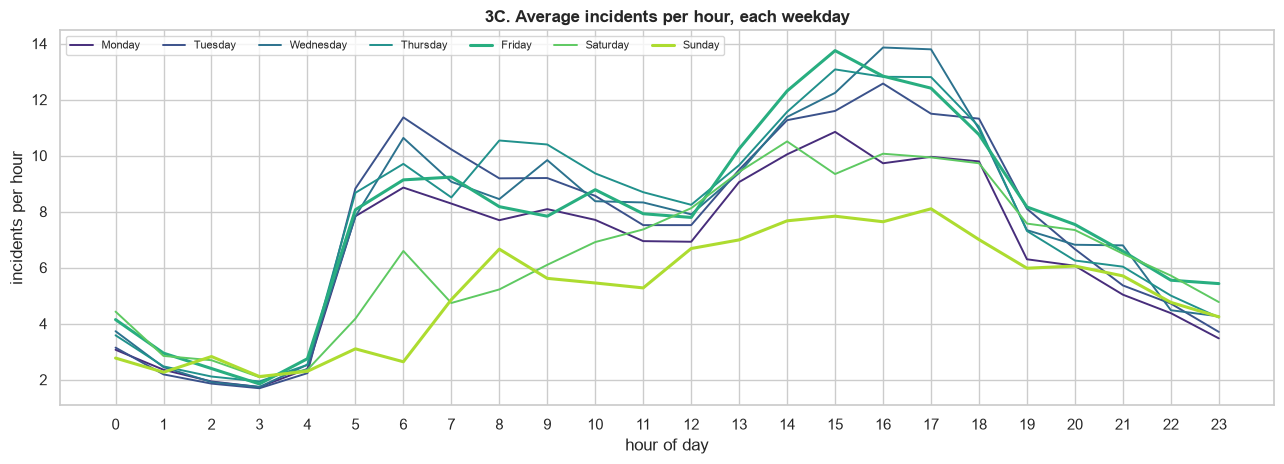

In [27]:
by_weekday = hourly.groupby(["weekday", "hour"], observed=True)["n_incidents"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(13, 4.8))
palette = sns.color_palette("viridis", 7)
for day, color in zip(WEEKDAYS, palette):
    ax.plot(by_weekday.index, by_weekday[day], label=day, color=color, lw=2.2 if day in ("Sunday", "Friday") else 1.4)
ax.set_xticks(list(HOURS))
ax.set(title="3C. Average incidents per hour, each weekday", xlabel="hour of day", ylabel="incidents per hour")
ax.legend(ncol=7, fontsize=8, loc="upper left")
plt.tight_layout()

**How to read it:** one line for each day of the week. Friday and Sunday are drawn thicker.

**What stands out:**
- Tuesday to Friday follow almost the same curve. **Friday is highest in the afternoon** (12.8 at 4 pm; Wednesday has the busiest hour overall, 13.9 at 4 pm).
- **Monday is lower** all day (9.7 at 4 pm).
- **Sunday is the lowest** for most of the day, and it is the only day with a very quiet early morning (2.6 at 6 am vs 8.9 on Monday).
- **Saturday sits between** the weekday and Sunday curves.

**Why it matters:** the weekend is not one group: Sunday behaves quite differently from Saturday. If many events fall on Saturdays and Sundays, comparing them with a mixed baseline would blur things. We may need weekday as a control and not only "weekday vs weekend".

### 3D. Heatmap: weekday × hour
The same numbers as 3C, shown as one picture of all 168 weekday-hour slots.

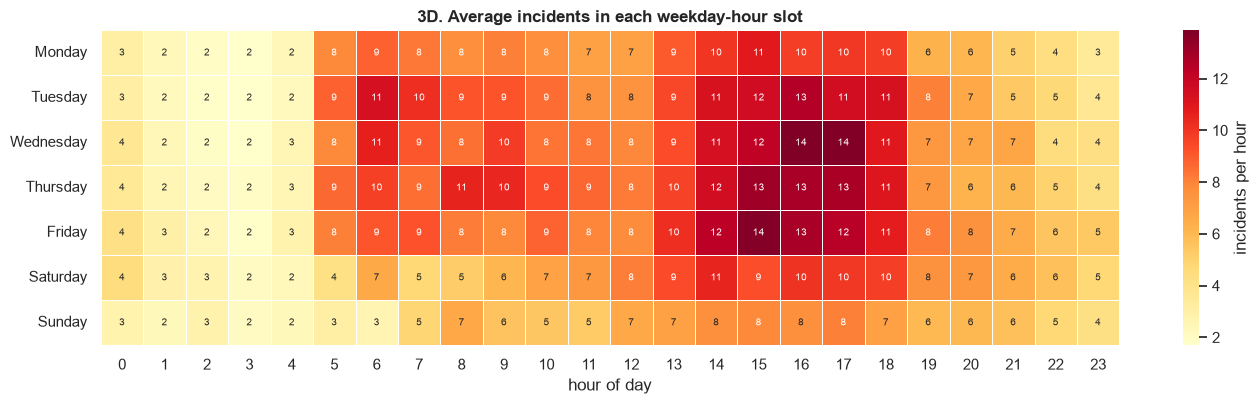

In [28]:
heat = hourly.pivot_table(index="weekday", columns="hour", values="n_incidents", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(14, 4.2))
sns.heatmap(heat, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 7}, linewidths=0.4, cbar_kws={"label": "incidents per hour"}, ax=ax)
ax.set(title="3D. Average incidents in each weekday-hour slot", xlabel="hour of day", ylabel="")
plt.tight_layout()

**How to read it:** each square is a weekday-hour slot, for example "Wednesday 4 pm". Darker red = more incidents on average. The number in the square is the average.

**What stands out:**
- The darkest block is **Tuesday to Friday, 2 to 6 pm** (about 11 to 14 incidents an hour). The busiest slot is **Wednesday 4 pm (13.9)** and the quietest is Tuesday 3 am (1.7).
- Weekday mornings (5 to 9 am) are a medium-dark band, and Sunday morning is nearly white.
- Evenings (7 pm on) look similar in every row.

**Why it matters:** this table of 168 numbers is the **expected pattern**. Any event effect has to be measured against the number in the *matching square*, not against the overall average. For example, a Saturday 7 pm baseline is about 7, and a Wednesday 4 pm baseline is about 14.

### 3E. How much does an hour vary from day to day?
Boxplot of the hourly counts for each hour of the day (one dot of data = one specific hour on one specific day).

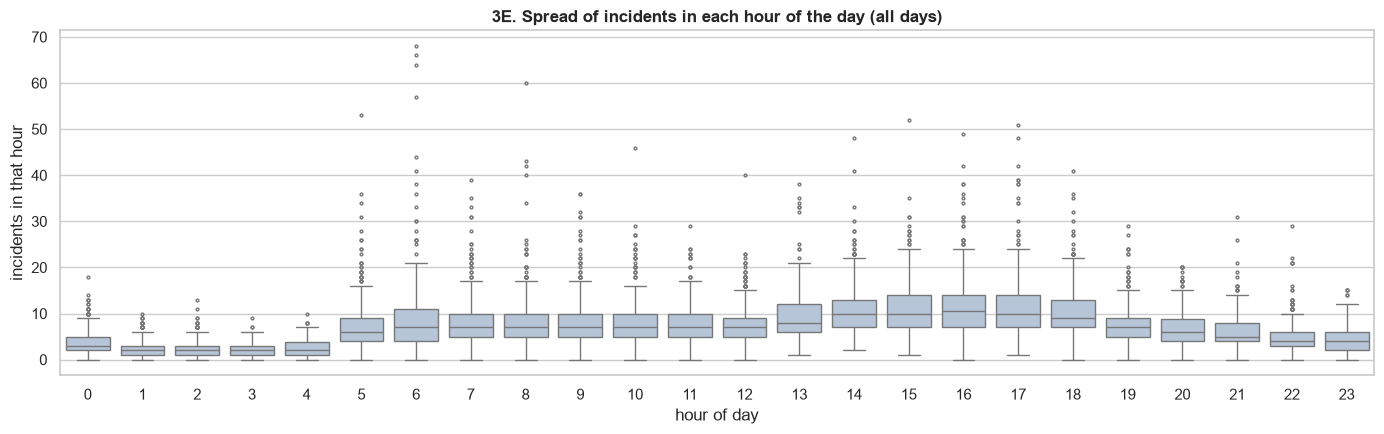

In [29]:
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.boxplot(data=hourly, x="hour", y="n_incidents", color="lightsteelblue", fliersize=2, ax=ax)
ax.set(title="3E. Spread of incidents in each hour of the day (all days)", xlabel="hour of day", ylabel="incidents in that hour")
plt.tight_layout()

**How to read it:** each box shows the middle half of the days for that hour. Dots above are unusually busy hours.

**What stands out:**
- The boxes are **wide**. At 4 pm the middle half of days range from about 7 to 14 incidents. The average hides a lot of day-to-day variation.
- Some individual hours are far above normal. The worst was **68 incidents in one hour** (6 am on 2025-09-23), and 49 at 4 pm on 2025-02-25.
- Relative to its average, the **night hours and 6 am are the most unstable**: a few incidents make a big percentage change.

**Why it matters:** an event hour with 15 incidents instead of 11 is *not* automatically unusual, because ordinary variation is that wide. That is why we need many event hours to see an effect, and not just single cases.

### 3F. Typical delay length by hour
Median and 90th percentile of delay minutes for the incidents in each hour (delay > 0).

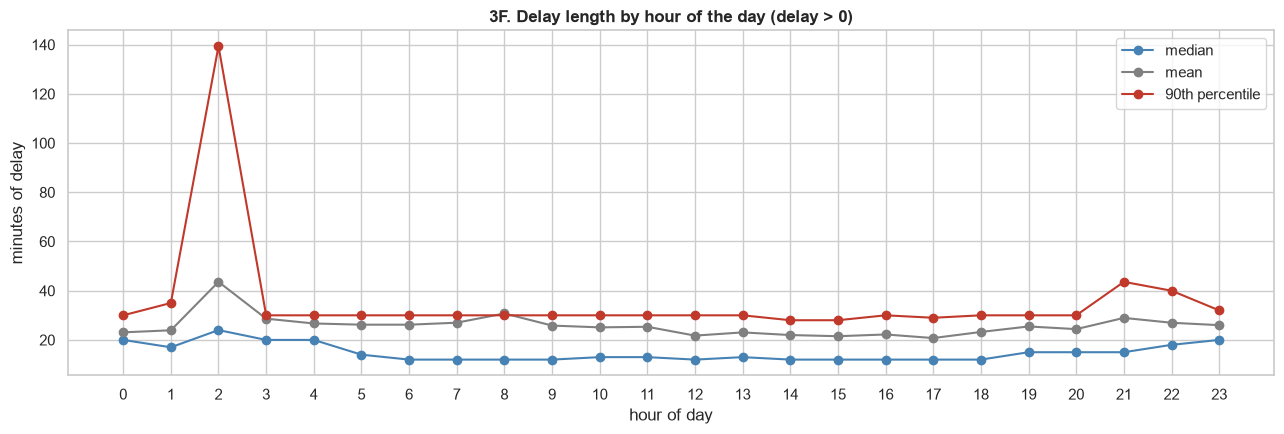

In [30]:
by_hour = incidents.groupby("hour").agg(
    n_incidents=("code", "size"), share_delayed=("is_delay", "mean"), delay_total=("delay_capped", "sum"),
)
delayed_by_hour = incidents[incidents["is_delay"]].groupby("hour")["min_delay"].agg(median="median", mean="mean", p90=lambda s: s.quantile(0.9))
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(delayed_by_hour.index, delayed_by_hour["median"], marker="o", label="median", color="steelblue")
ax.plot(delayed_by_hour.index, delayed_by_hour["mean"], marker="o", label="mean", color="gray")
ax.plot(delayed_by_hour.index, delayed_by_hour["p90"], marker="o", label="90th percentile", color="#c0392b")
ax.set_xticks(list(HOURS))
ax.set(title="3F. Delay length by hour of the day (delay > 0)", xlabel="hour of day", ylabel="minutes of delay")
ax.legend()
plt.tight_layout()

**How to read it:** blue = the typical delay, grey = the average, red = the long end (1 in 10 incidents is longer than this).

**What stands out:**
- The **typical delay is shortest during the day**: 10 minutes between 7 and 9 am, and between 2 and 4 pm. It is longer late at night: **15 to 16 minutes at 10 pm to midnight and at 2 to 3 am** (1 am is 13).
- The **mean is very bumpy** (17 to 29 minutes), because a few long incidents have a large effect when the hour has few incidents. The highest is 2 am (29.4).
- The red line sits at **30 for most hours**, which is staff rounding again (see 2F).

**Why it matters:** the length of a delay varies only slightly with the hour (10 to 16 minutes median). The hour of day matters much more for *how many* incidents there are than for *how long* they are.

### 3G. Share of incidents that carry a delay, by hour

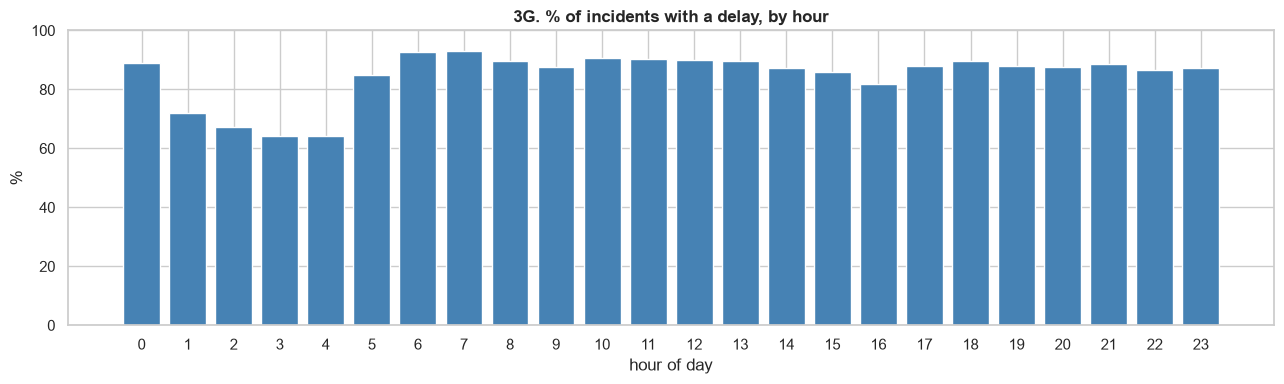

In [31]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(by_hour.index, by_hour["share_delayed"] * 100, color="steelblue")
ax.set_xticks(list(HOURS))
ax.set(title="3G. % of incidents with a delay, by hour", xlabel="hour of day", ylabel="%", ylim=(0, 100))
plt.tight_layout()

**How to read it:** of all the incidents logged in an hour, the share that caused a delay of more than 0 minutes.

**What stands out:** it is high (**82 to 93%**) from 5 am to midnight, but **lower at night: 64 to 72% between 1 and 4 am**. Mornings (6 to 8 am) are the highest, at 90 to 93%.

**Why it matters:** at night many incidents are logged without a delay. It is more likely that those are things like a bus parked or a shift problem on an empty road. Daytime incidents nearly always hold up service.

### 3H. Total delay minutes by hour

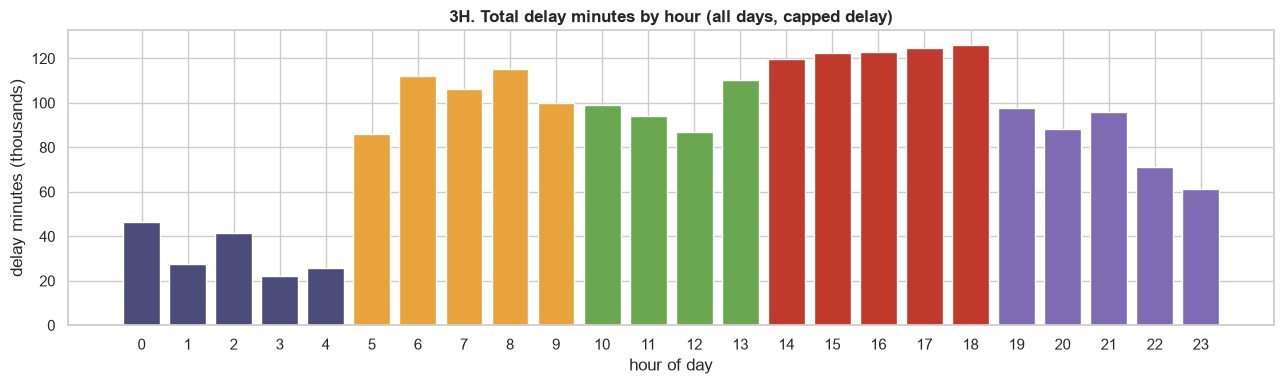

In [32]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(by_hour.index, by_hour["delay_total"] / 1000, color=[PERIOD_COLORS[p] for p in parts])
ax.set_xticks(list(HOURS))
ax.set(title="3H. Total delay minutes by hour (all days, capped delay)", xlabel="hour of day", ylabel="delay minutes (thousands)")
plt.tight_layout()

**How to read it:** all delay minutes in the whole period, added up for each hour of the day.

**What stands out:** the shape follows 3A, but is **flatter**. Between 6 am and 6 pm the totals are all in the range of 87,000 to 126,000 minutes: the morning (6 to 8 am: 106,000 to 115,000) is almost as heavy as the afternoon (119,000 to 126,000), even though the morning has fewer incidents. This is because morning delays are slightly longer on average (mean 24 to 28 min vs 18 to 19 in the afternoon).

**Why it matters:** counting incidents and counting delay minutes give a different picture of which hours are worst. The afternoon wins on counts, but the morning is close on minutes. We should look at both in notebook 03.

### 3I. Cause mix by hour
Of the incidents in each hour, what share comes from each cause group? (Each bar adds up to 100%.)

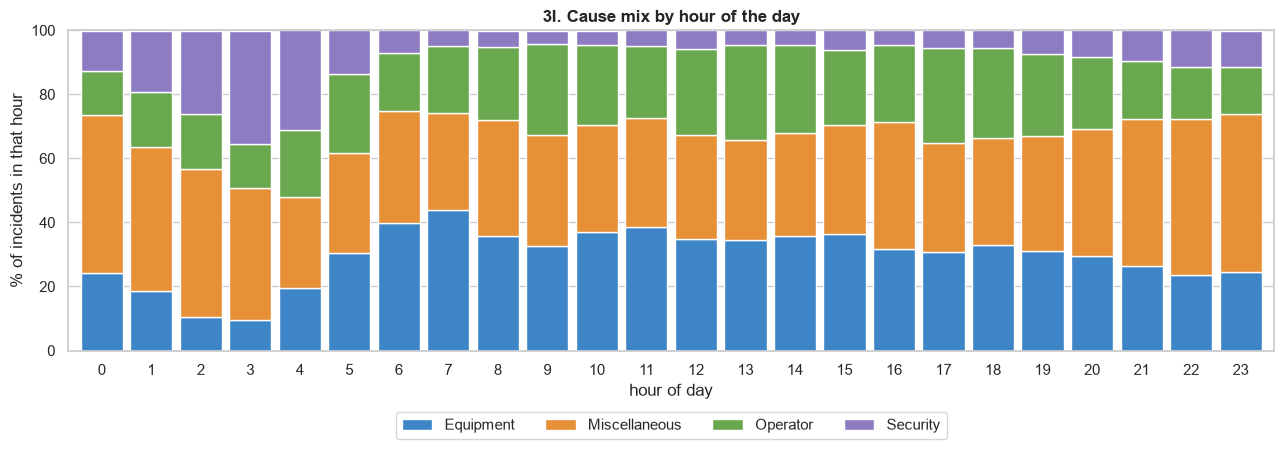

In [33]:
mix = pd.crosstab(incidents["hour"], incidents["cause_group"], normalize="index")[["Equipment", "Miscellaneous", "Operator", "Security"]] * 100
fig, ax = plt.subplots(figsize=(13, 4.8))
mix.plot.bar(stacked=True, ax=ax, color=["#3d85c6", "#e69138", "#6aa84f", "#8e7cc3"], width=0.85)
ax.set(title="3I. Cause mix by hour of the day", xlabel="hour of day", ylabel="% of incidents in that hour", ylim=(0, 100))
ax.tick_params(axis="x", rotation=0)
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.3))
plt.tight_layout()

**How to read it:** every bar is one hour and adds up to 100%. The colours show where the incidents in that hour come from.

**What stands out:**
- **Security** (violet) is a **night problem**: 26 to 35% of incidents at 2 to 4 am, but only 4 to 6% during the day.
- **Miscellaneous** (orange) is biggest at night and late evening (about 45 to 50% from 10 pm to 2 am) and falls to a third during the day. It is the group that contains diversions.
- **Equipment** (blue) is largest in the morning (40 to 44% at 6 to 7 am), probably because buses are starting up.
- **Operator** (green) is steady, about 20 to 30% in the day.

**Why it matters:** the *type* of problem changes during the day. At night incidents are a different kind of problem to the ones in the afternoon, so night and day should not be mixed when we look at one cause.

### 3J. When do diversions (MFDV) happen?
Diversions are the cause most linked to events and road closures. Compare their hour pattern with all incidents.

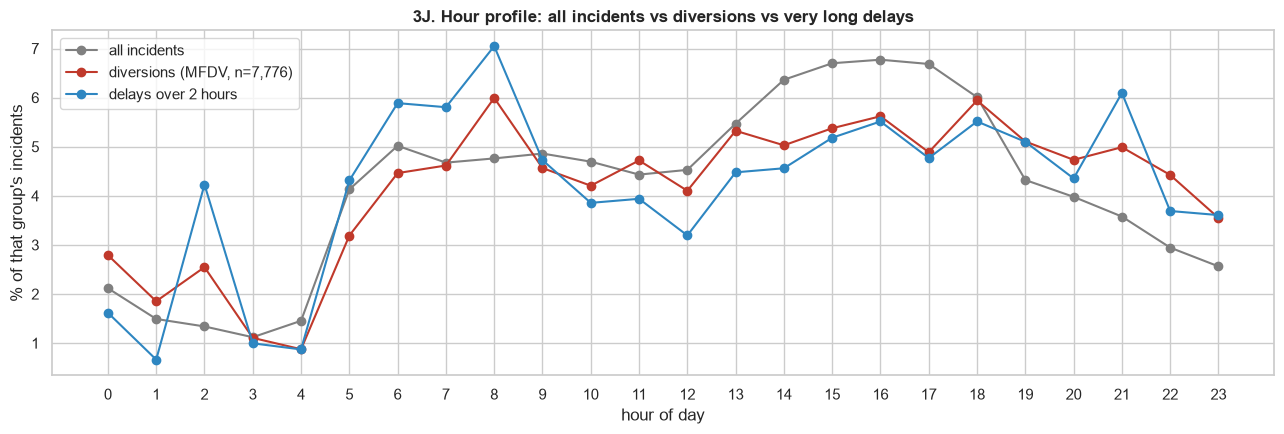

In [34]:
share_all = incidents["hour"].value_counts(normalize=True).sort_index() * 100
share_div = incidents.loc[incidents["code"] == "MFDV", "hour"].value_counts(normalize=True).sort_index() * 100
share_long = incidents.loc[incidents["min_delay"] > 120, "hour"].value_counts(normalize=True).sort_index() * 100
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(share_all.index, share_all.values, marker="o", color="gray", label="all incidents")
ax.plot(share_div.index, share_div.values, marker="o", color="#c0392b", label=f"diversions (MFDV, n={int((incidents['code'] == 'MFDV').sum()):,})")
ax.plot(share_long.index, share_long.values, marker="o", color="#2e86c1", label="delays over 2 hours")
ax.set_xticks(list(HOURS))
ax.set(title="3J. Hour profile: all incidents vs diversions vs very long delays", xlabel="hour of day", ylabel="% of that group's incidents")
ax.legend()
plt.tight_layout()

**How to read it:** each line shows how that group of incidents is spread over the 24 hours (each line adds up to 100%). If a line is above the grey line at some hour, that group is over-represented then.

**What stands out:**
- **Diversions have a flatter profile**: below the grey line in the 3 pm to 6 pm peak (about 5 to 5.6% at 3 to 5 pm vs 6.7%) and above it in the evening from 7 to 11 pm (3.5 to 5.1% vs 2.6 to 4.3%) and at 8 am.
- Delays **over 2 hours** are spread even more evenly: about 3 to 7% in every hour from 5 am to midnight, with 8 am the highest (7%). The share at 2 am (4.2%) is a lot larger than the share of all incidents (1.3%).

**Why it matters:** diversions and very long delays do *not* depend on the afternoon rush the way all incidents do, so they happen throughout the day and evening. That is consistent with their causes being outside the rush hour (road closures, events, weather) and is a good sign that the evening hours of event windows may show a signal.

### 3K. Does the daily pattern change through the year?
Heatmap of average incidents per hour by month and hour of day.

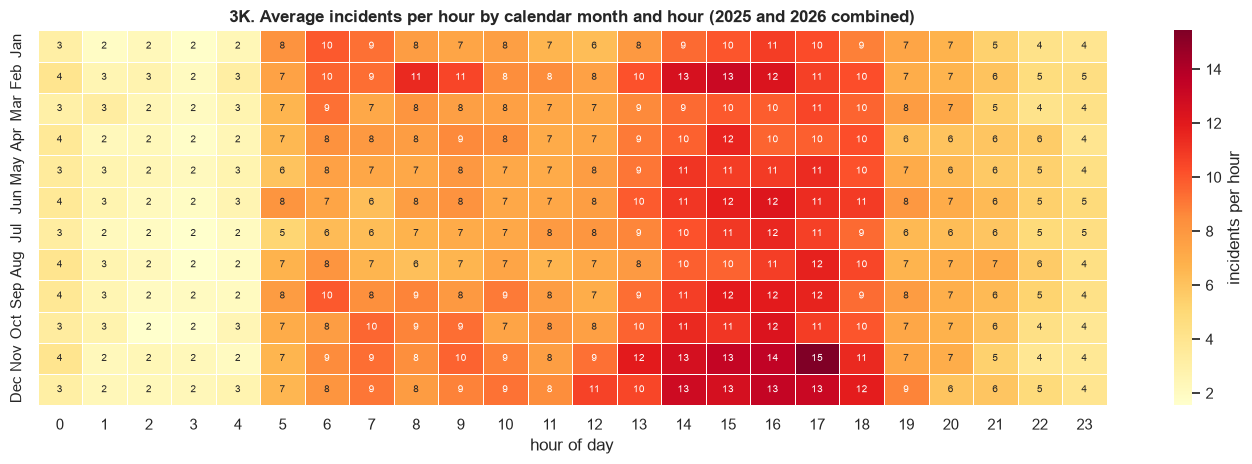

In [35]:
month_hour = hourly.pivot_table(index="month", columns="hour", values="n_incidents", aggfunc="mean")
month_hour.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(14, 4.8))
sns.heatmap(month_hour, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 7}, linewidths=0.4, cbar_kws={"label": "incidents per hour"}, ax=ax)
ax.set(title="3K. Average incidents per hour by calendar month and hour (2025 and 2026 combined)", xlabel="hour of day", ylabel="")
plt.tight_layout()

**How to read it:** rows are months (both years combined) and columns are hours. Darker = busier.

**What stands out:**
- **The afternoon peak exists in all months** (3 to 5 pm is dark in every row), but it is strongest in **December (13 per hour)** and **February (12.4)** and weakest in **January (about 10 to 11)**.
- **Summer mornings are lighter**: 6 am has 6.3 incidents an hour in July and 7.4 in June, vs 9.6 to 9.9 in January and February.
- Late evening hours are about the same all year.

**Why it matters:** the baseline for a given hour depends on the season, so a July baseball game at 7 pm should be compared with other July evenings, not with a winter average. (The 2025 and 2026 patterns by hour are very similar, see next chart.)

### 3L. Is the hourly pattern stable between 2025 and 2026?

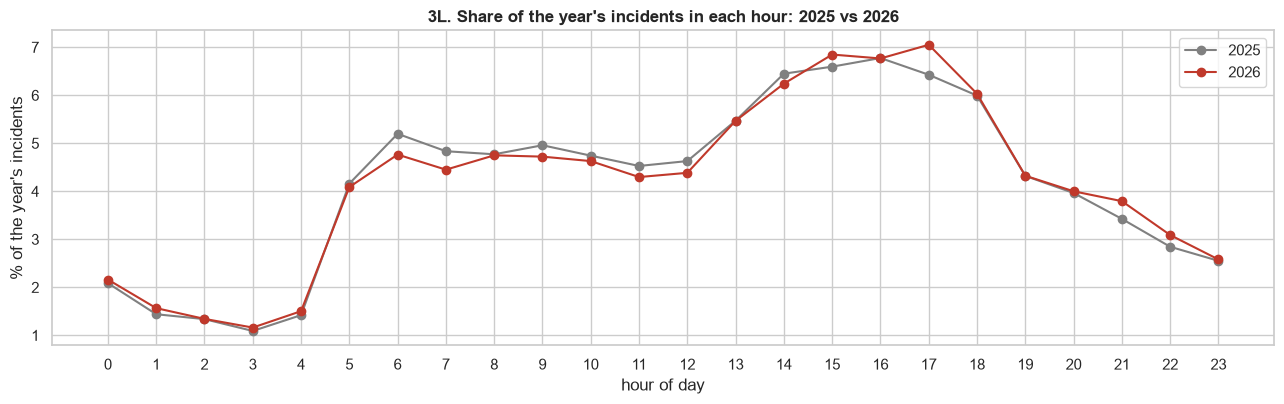

In [36]:
year_hour = incidents.groupby([incidents["date"].dt.year, "hour"]).size().unstack(0)
year_hour = year_hour / year_hour.sum() * 100
fig, ax = plt.subplots(figsize=(13, 4.2))
for year, color in zip(year_hour.columns, ["gray", "#c0392b"]):
    ax.plot(year_hour.index, year_hour[year], marker="o", label=str(year), color=color)
ax.set_xticks(list(HOURS))
ax.set(title="3L. Share of the year's incidents in each hour: 2025 vs 2026", xlabel="hour of day", ylabel="% of the year's incidents")
ax.legend()
plt.tight_layout()

**How to read it:** each line shows how the year's incidents are spread across hours (each adds to 100%). The years have different numbers of days, so shares are used.

**What stands out:** the two lines lie almost on top of each other (differences of at most 0.7 percentage points). Both show the 5 am jump and the 3 to 6 pm peak. The biggest difference is 5 pm (7.1% in 2026 vs 6.4% in 2025).

**Why it matters:** the daily rhythm is **stable**, so one hour baseline can be used for both years.

### 3M. Routes near a venue vs other routes: when do their incidents happen?

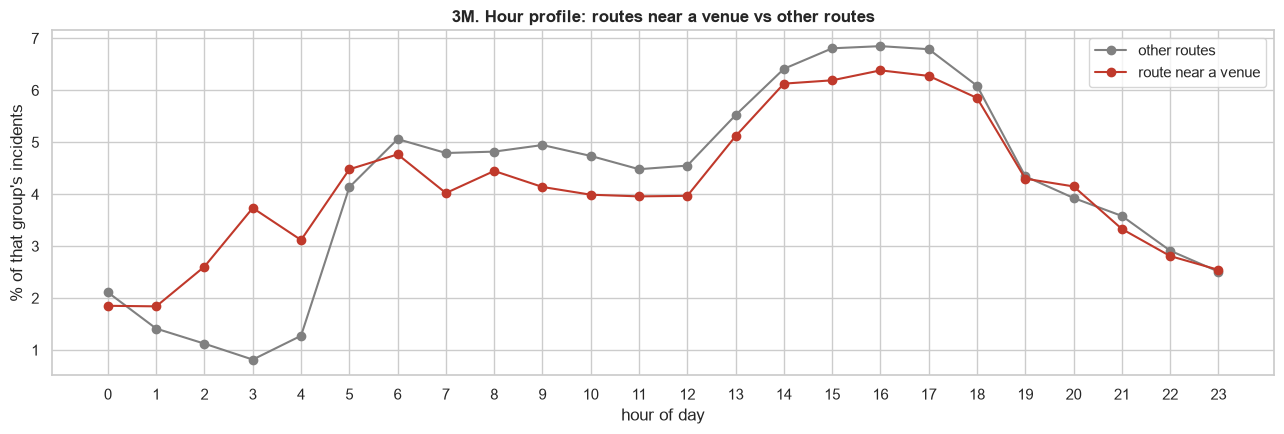

In [37]:
located_hours = incidents.dropna(subset=["near_venue"])
where_hour = located_hours.groupby(["near_venue", "hour"]).size().unstack(0)
where_hour = where_hour / where_hour.sum() * 100
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(where_hour.index, where_hour[False], marker="o", color="gray", label="other routes")
ax.plot(where_hour.index, where_hour[True], marker="o", color="#c0392b", label="route near a venue")
ax.set_xticks(list(HOURS))
ax.set(title="3M. Hour profile: routes near a venue vs other routes", xlabel="hour of day", ylabel="% of that group's incidents")
ax.legend()
plt.tight_layout()

**How to read it:** each line shows how incidents are spread over the hours for one group of routes (each adds up to 100%).

**What stands out:** the profiles are close, with one difference: **near-venue routes have more of their incidents at night**. At 2 to 4 am they have 2.6 to 3.7% each hour, vs 0.8 to 1.3% for other routes. In the afternoon rush their share is a little lower (6.2 to 6.4% vs 6.8%).

**Why it matters:** night incidents on downtown routes are probably a different issue to event-related ones (for example a Security problem on a downtown route at night; see 3I). When we look at near-venue routes, hours around events should be separated from night hours.

### 3N. Incidents per hour in each part of the day, weekday vs weekend

day_type,weekday,weekend
period,,
night (0-4),2.5,2.7
morning (5-9),9.0,5.0
midday (10-13),8.4,7.0
afternoon (14-18),11.8,8.8
evening (19-23),5.8,5.9


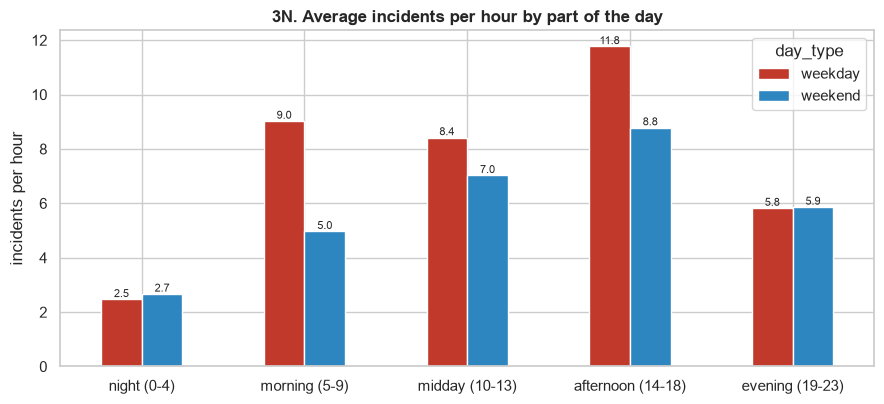

In [38]:
hourly["period"] = period_of(hourly["hour"])
period_means = hourly.groupby(["period", "day_type"], observed=True)["n_incidents"].mean().unstack()
fig, ax = plt.subplots(figsize=(9, 4.2))
period_means[["weekday", "weekend"]].plot.bar(ax=ax, color=["#c0392b", "#2e86c1"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f", fontsize=8)
ax.bar_label(ax.containers[1], fmt="%.1f", fontsize=8)
ax.set(title="3N. Average incidents per hour by part of the day", xlabel="", ylabel="incidents per hour")
plt.tight_layout()
period_means.round(1)

**How to read it:** the same numbers as 3B, but grouped into the five parts of the day used for the colours above. This is the simplest summary of the hourly pattern.

**What stands out:** the **afternoon is the busiest on every type of day** (weekdays 11.8, weekends 8.8 incidents an hour), and **night is the quietest** (about 2.5 on both). The weekday–weekend gap is large in the morning (weekdays about 9 vs 5) and small in the evening.

**Why it matters:** if we need a simple grouping of hours for the main analysis (instead of 24 separate hours), these five parts of the day are a good choice.

### Step 3 takeaways
- The day has a clear shape: **quiet night (2 to 3 an hour), a jump at 5 am, a steady day (7 to 8), a peak from 2 to 6 pm (10 to 11 an hour), and a slow fall in the evening**.
- The **afternoon, not the morning, is the busiest**. Weekdays are far busier than weekends in the morning and afternoon but nearly the same in the evening and at night.
- **Sunday is the quietest day**, and Saturday sits between Sunday and weekdays. The weekend should not be treated as one group.
- A single hour varies a lot from day to day, so event hours must be compared with the **same day of week and same hour** (and ideally the same season) on non-event days. The 168-slot table in 3D is the baseline.
- **Night is a different world**: more Security and Miscellaneous incidents, fewer delays, longer typical delays. Night hours should be handled separately.
- Diversions and very long delays are spread through the day and evening, not tied to the afternoon rush.
- The hourly rhythm is stable between 2025 and 2026.

*(Numbers in the notes come from the data as run on this version.)*

## Step 4. Why do incidents happen? (cause codes)

Every incident has a **cause code** chosen by staff (75 different codes in this data). The first letter gives the group:
**E**quipment, **M**iscellaneous, **O**perator (codes starting with T), **S**ecurity. In notebook 01 the group `cause_group` is built from the first letter.
The three codes most related to events are `MFDV` (on diversion), `MFPR` (held by parades/marches) and `MFUS` (unable to maintain schedule).

This step also checks whether the **way codes are used stayed the same over time**. If it changed, comparing months would be unfair.

In [39]:
codes = incidents.groupby(["code", "code_description"]).agg(
    incidents=("code", "size"),
    share_of_incidents=("code", lambda s: len(s) / len(incidents) * 100),
    share_delayed=("is_delay", "mean"),
    median_delay=("min_delay", lambda s: s[s > 0].median()),
    delay_minutes=("delay_capped", "sum"),
).reset_index().sort_values("incidents", ascending=False)
codes["share_of_delay_minutes"] = codes["delay_minutes"] / codes["delay_minutes"].sum() * 100
codes["label"] = codes["code"] + " · " + codes["code_description"].str.title().str.slice(0, 34)
incidents["month"] = incidents["date"].dt.to_period("M")
print(f"{codes.shape[0]} distinct codes")
codes.head(20).round(1).drop(columns=["delay_minutes", "label"])

75 distinct codes


,code,code_description,incidents,share_of_incidents,share_delayed,median_delay,share_of_delay_minutes
13,EFO,OTHER,18376,17.2,1.0,12.0,12.1
64,TFCNO,NO OPERATOR AVAILABLE,8974,8.4,1.0,12.0,6.3
44,MFSH,USED AS SHUTTLE BUS,8137,7.6,0.9,10.0,4.8
30,MFDV,ON DIVERSION,7776,7.3,0.9,71.0,36.4
71,TFPD,TTC COLLISION - PROPERTY DAMAGE,7083,6.6,0.9,11.0,4.2
68,TFO,OTHER - SWITCH VIOLATION,5737,5.4,0.9,16.0,4.4
48,MFUS,UNABLE TO MAINTAIN SCHEDULE,4365,4.1,0.4,21.0,1.6
6,EFD,DOORS,4231,4.0,1.0,12.0,2.9
56,SFDP,DISORDERLY PATRON,3896,3.6,0.7,13.0,2.1
1,EFB,BODY,2939,2.7,1.0,12.0,2.0


**How to read the table:** one row per code, most frequent first. `share_delayed` is the share of its incidents with a delay, and `median_delay` is the typical delay when there is one.

**What stands out:**
- The most frequent code is **`EFO` "Other" (17% of all incidents)**. It says very little about *why* the problem happened.
- **`MFDV` "On diversion"** is only 7.3% of incidents, but its typical delay is **71 minutes** (vs 10 to 16 for most codes).
- **`MFUS` "Unable to maintain schedule"** is the odd one: only 35% of its incidents carry a delay.

### 4A. The 15 most frequent codes

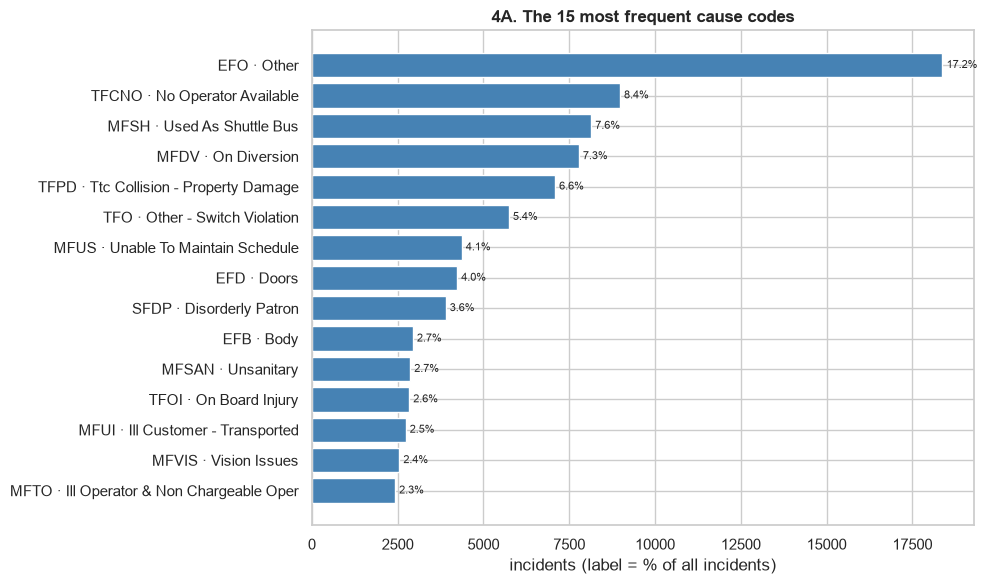

In [40]:
top15 = codes.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top15["label"], top15["incidents"], color="steelblue")
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in top15["share_of_incidents"]], fontsize=8, padding=3)
ax.set(title="4A. The 15 most frequent cause codes", xlabel="incidents (label = % of all incidents)")
plt.tight_layout()

**How to read it:** longer bar = more incidents. The label is the share of all incidents.

**What stands out:** a few codes dominate. The top 5 (`EFO` Other, `TFCNO` no operator available, `MFSH` used as shuttle bus, `MFDV` on diversion, `TFPD` collision with property damage) are about **47% of all incidents**. After that the list falls off slowly.

**Why it matters:** many of the most common codes are about the **buses themselves or the staff** (equipment, operator, collisions), which have nothing to do with events. Only a few codes could plausibly react to events, so we should not use the total count of incidents as the only outcome.

### 4B. Frequent vs long: share of incidents and share of delay minutes
For each of the 12 most frequent codes, compared with how much of all delay time it causes.

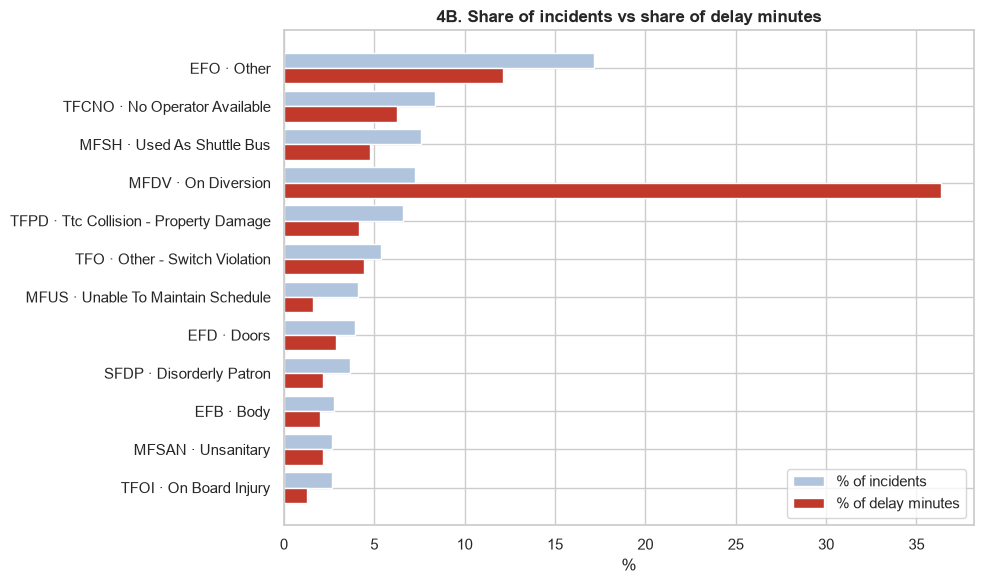

In [41]:
top12 = codes.head(12).iloc[::-1]
pos = np.arange(len(top12))
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(pos + 0.2, top12["share_of_incidents"], height=0.4, label="% of incidents", color="lightsteelblue")
ax.barh(pos - 0.2, top12["share_of_delay_minutes"], height=0.4, label="% of delay minutes", color="#c0392b")
ax.set_yticks(pos)
ax.set_yticklabels(top12["label"])
ax.set(title="4B. Share of incidents vs share of delay minutes", xlabel="%")
ax.legend(loc="lower right")
plt.tight_layout()

**How to read it:** for each code, the light bar is its share of incidents and the red bar is its share of all delay minutes. If red is longer than blue, the code causes *more delay than its number suggests*.

**What stands out:** **`MFDV` is the clear outlier.** It is 7.3% of incidents but **36% of all delay minutes**, five times its share. Every other code is about the same in both bars or lower (`EFO` 17% vs 12%).

**Why it matters:** diversions are the codes that matter most for service delays. They are also the ones most likely to be linked to road closures and events. This is the most important code for notebook 03.

### 4C. Delay length and share with a delay, for the top 15 codes

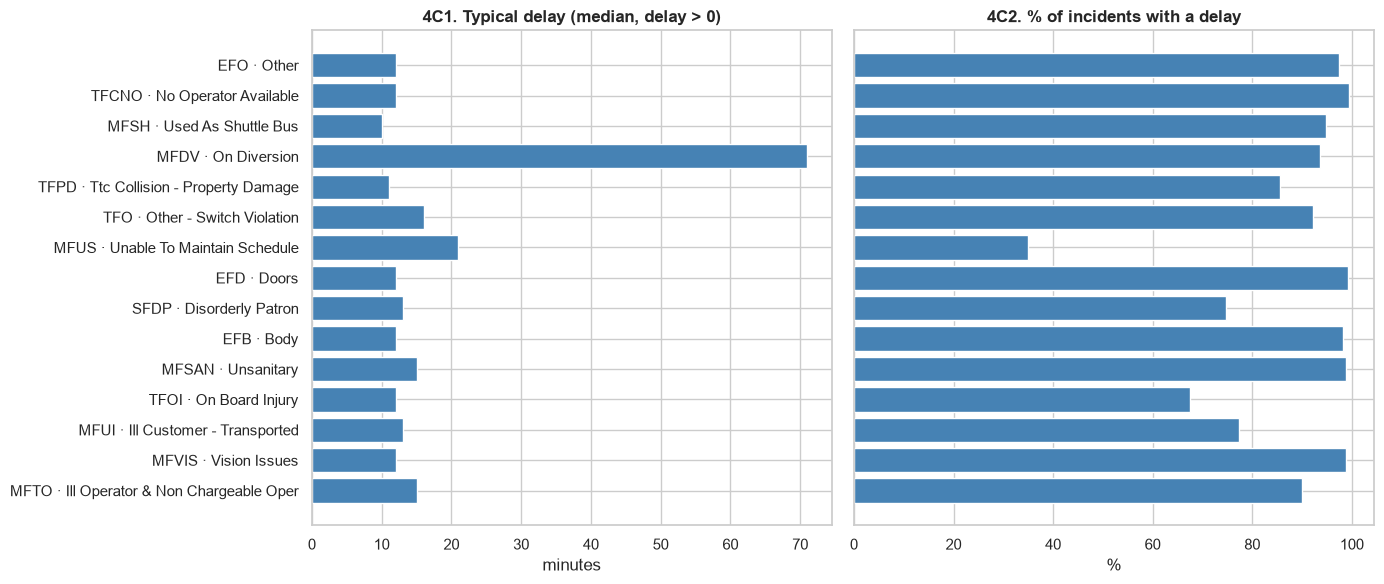

In [42]:
top15_codes = codes.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
axes[0].barh(top15_codes["label"], top15_codes["median_delay"], color="steelblue")
axes[0].set(title="4C1. Typical delay (median, delay > 0)", xlabel="minutes")
axes[1].barh(top15_codes["label"], top15_codes["share_delayed"] * 100, color="steelblue")
axes[1].set(title="4C2. % of incidents with a delay", xlabel="%")
plt.tight_layout()

**How to read it:** the left panel shows how long the typical delay is when there is one. The right panel shows how often the incident causes any delay.

**What stands out:**
- Left: **`MFDV` (71 min) and `MFUS` (21 min)** stand out. Almost all the others are between 10 and 16 minutes.
- Right: almost all equipment and operator codes cause a delay **86 to 99%** of the time. **`MFUS` (35%)**, `TFOI` on-board injury (67%), `SFDP` disorderly patron (75%) and `MFUI` ill customer (77%) often cause no delay.

**Why it matters:** the same *number* of incidents can mean very different amounts of lost service depending on the code. Counting each code equally would hide this.

### 4D. Cause group: share of incidents and share of delay minutes

,incidents,minutes
cause_group,,
Equipment,32.5,23.1
Miscellaneous,36.1,55.9
Operator,23.8,16.8
Security,7.6,4.2


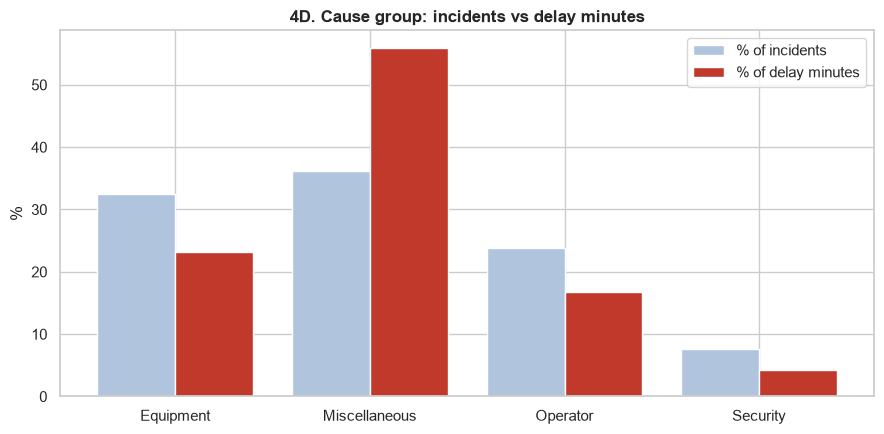

In [43]:
groups = incidents[incidents["cause_group"].isin(["Equipment", "Miscellaneous", "Operator", "Security"])].groupby("cause_group").agg(
    incidents=("code", "size"), minutes=("delay_capped", "sum"))
share = groups / groups.sum() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(share))
ax.bar(x - 0.2, share["incidents"], width=0.4, label="% of incidents", color="lightsteelblue")
ax.bar(x + 0.2, share["minutes"], width=0.4, label="% of delay minutes", color="#c0392b")
ax.set_xticks(x)
ax.set_xticklabels(share.index)
ax.set(title="4D. Cause group: incidents vs delay minutes", ylabel="%")
ax.legend()
plt.tight_layout()
share.round(1)

**How to read it:** same idea as 4B, but for the four cause groups.

**What stands out:** **Miscellaneous has 36% of incidents but 56% of delay minutes.** Equipment drops from 32% of incidents to 23% of minutes, Operator from 24% to 17% and Security from 8% to 4%.

**Why it matters:** Miscellaneous contains diversions and weather-related codes, so it is the group where road problems appear. It makes up over half of all lost service time.

### 4E. The top codes month by month

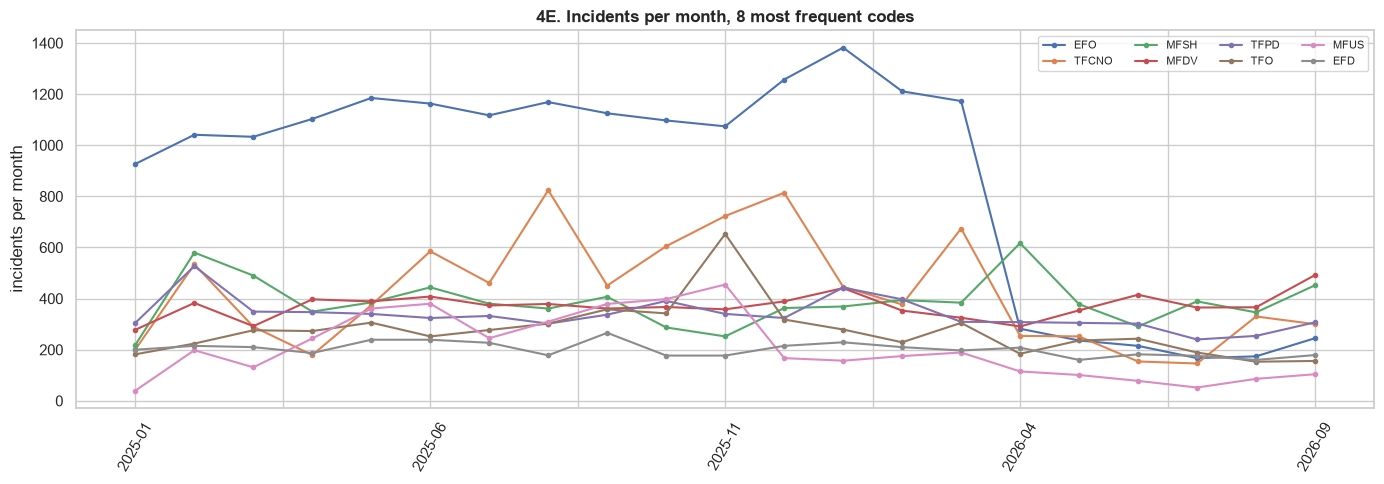

In [44]:
top8 = codes["code"].head(8).tolist()
monthly_codes = pd.crosstab(incidents["month"], incidents["code"])[top8]
monthly_codes.index = monthly_codes.index.astype(str)
fig, ax = plt.subplots(figsize=(14, 5))
monthly_codes.plot(ax=ax, marker="o", ms=3)
ax.set(title="4E. Incidents per month, 8 most frequent codes", xlabel="", ylabel="incidents per month")
ax.legend(ncol=4, fontsize=8)
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()

**How to read it:** one line per code, counting incidents each month.

**What stands out:**
- `MFDV` (diversions) is **very steady**, between 280 and 490 a month, and has no trend.
- **Something changes after March 2026**: `EFO` ("Equipment other"), by far the biggest line, falls from about **900 to 1,400 a month to under 300** in April 2026 and stays low. `MFSH` jumps at the same time (384 to 617 in April).
- `MFUS` falls in two steps (see 4H).
- The other codes move up and down with no clear break.

**Why it matters:** the sudden drop of `EFO` in April 2026 is not something that happened on the roads. It is a **change in how staff record causes**. We look at it in 4I and 4J.

### 4F. Cause groups month by month (share of each month)

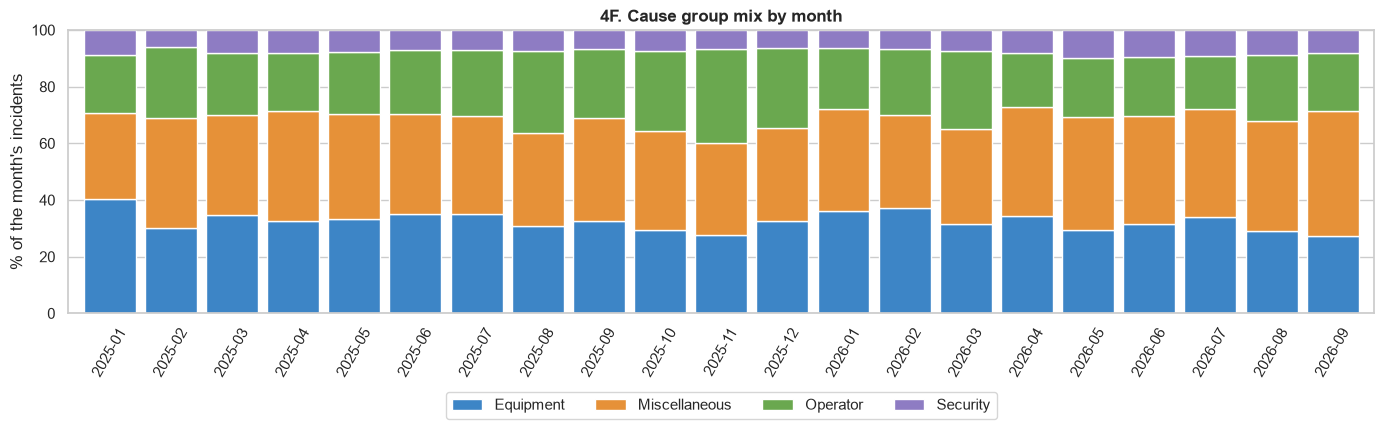

In [45]:
group_month = pd.crosstab(incidents["month"], incidents["cause_group"], normalize="index")[["Equipment", "Miscellaneous", "Operator", "Security"]] * 100
group_month.index = group_month.index.astype(str)
fig, ax = plt.subplots(figsize=(14, 4.8))
group_month.plot.bar(stacked=True, ax=ax, color=["#3d85c6", "#e69138", "#6aa84f", "#8e7cc3"], width=0.85)
ax.set(title="4F. Cause group mix by month", xlabel="", ylabel="% of the month's incidents", ylim=(0, 100))
ax.tick_params(axis="x", rotation=60)
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.4))
plt.tight_layout()

**How to read it:** each bar is a month and adds up to 100%.

**What stands out:** the mix is **fairly stable** through 2025 and early 2026 (Equipment about 33%, Miscellaneous 33 to 38%, Operator 27%). From April 2026 **Miscellaneous grows (38% to 44% by September) and Operator shrinks (27% to 19 to 20%)**.

**Why it matters:** part of that rise in Miscellaneous is not "more road trouble". It is the effect of other categories getting smaller (the `EFO` drop). Diversions themselves are steady in count (4E). The group shares should be read with that in mind.

### 4G. The three event-related codes over time
Each panel has its own scale, because the codes differ a lot in size.

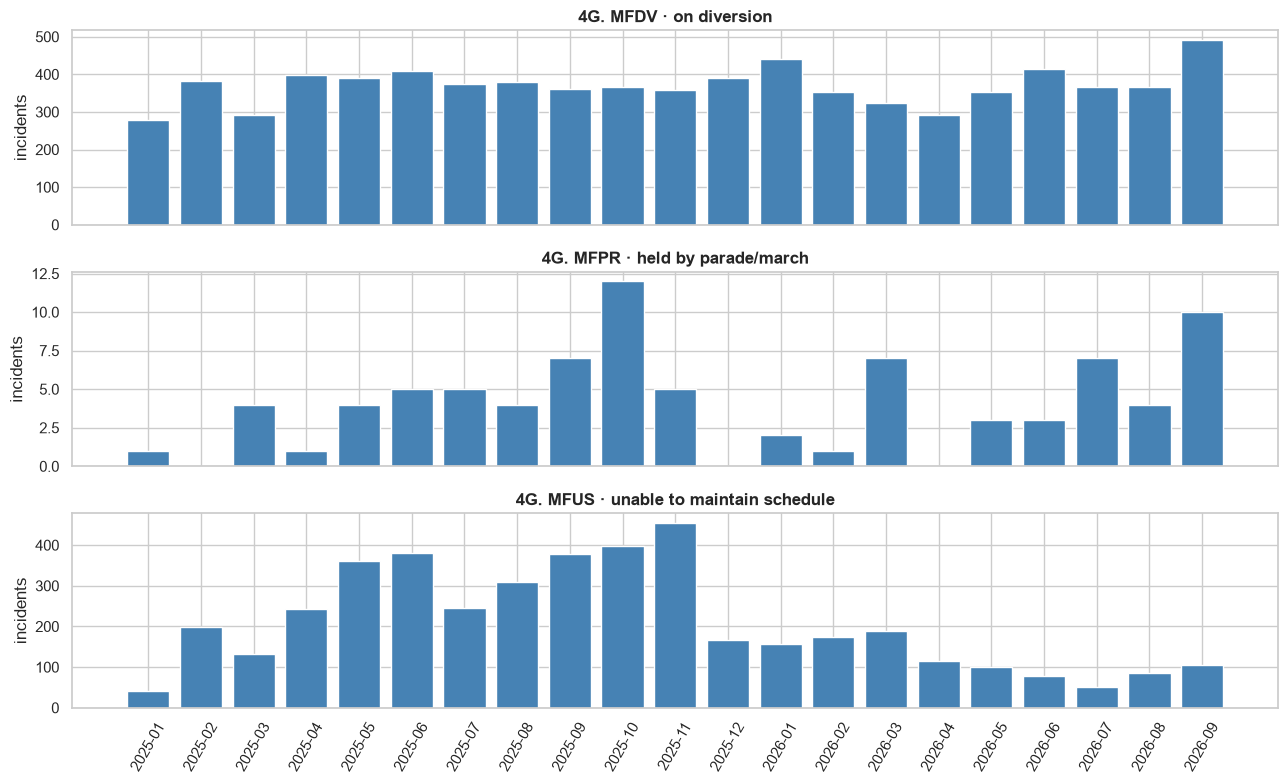

In [46]:
key = pd.crosstab(incidents["month"], incidents["code"])[["MFDV", "MFPR", "MFUS"]]
key.index = key.index.astype(str)
titles = {"MFDV": "MFDV · on diversion", "MFPR": "MFPR · held by parade/march", "MFUS": "MFUS · unable to maintain schedule"}
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
for ax, code_name in zip(axes, key.columns):
    ax.bar(key.index, key[code_name], color="steelblue")
    ax.set(title=f"4G. {titles[code_name]}", ylabel="incidents")
axes[-1].tick_params(axis="x", rotation=60)
plt.tight_layout()

**How to read it:** monthly incident counts for each of the three codes the README links to events.

**What stands out:**
- **`MFDV`**: 280 to 490 a month, steady. The highest month is September 2026 (492).
- **`MFPR`** (held by parades/marches) is **very rare**: 0 to 12 incidents a month, about 85 in total in 21 months. The biggest month is October 2025 (12).
- **`MFUS`** rises through 2025 (40 in January to 455 in November) and then **falls sharply from December 2025** (167) and keeps falling to 52 in July 2026.

**Why it matters:** `MFPR` is too rare to analyse by itself. `MFDV` is the realistic outcome for the event question, and `MFUS` cannot be compared across months without care.

### 4H. `MFUS`: did its meaning change?
Count per month, share of its incidents with a delay, and its typical delay.

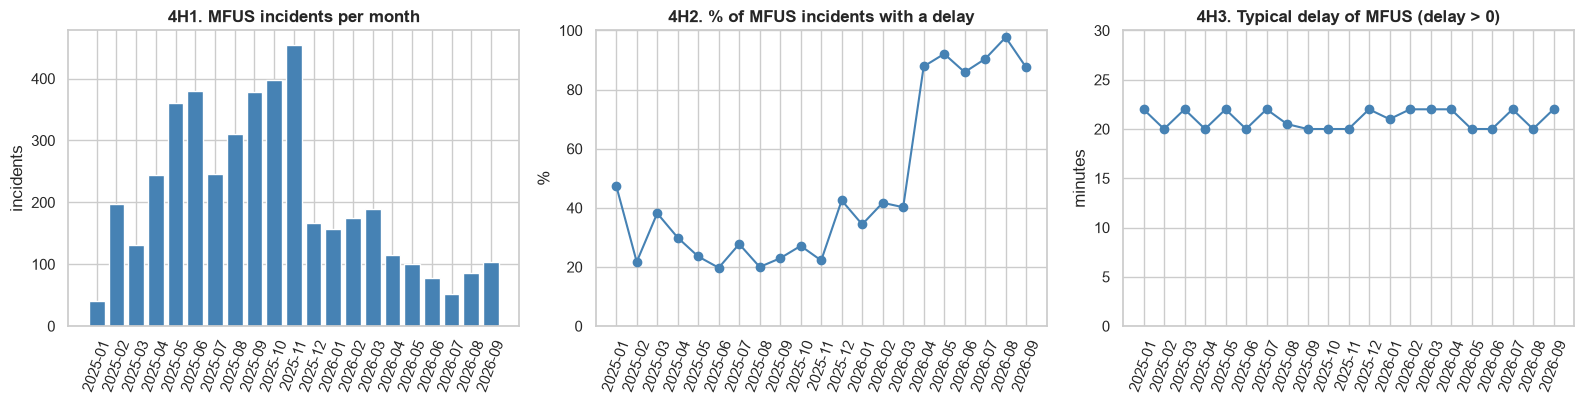

In [47]:
mfus = incidents[incidents["code"] == "MFUS"]
mfus_month = mfus.groupby("month").agg(n=("code", "size"), share_delayed=("is_delay", "mean"),
                                       median_delay=("min_delay", lambda s: s[s > 0].median()))
mfus_month.index = mfus_month.index.astype(str)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].bar(mfus_month.index, mfus_month["n"], color="steelblue")
axes[0].set(title="4H1. MFUS incidents per month", ylabel="incidents")
axes[1].plot(mfus_month.index, mfus_month["share_delayed"] * 100, marker="o", color="steelblue")
axes[1].set(title="4H2. % of MFUS incidents with a delay", ylabel="%", ylim=(0, 100))
axes[2].plot(mfus_month.index, mfus_month["median_delay"], marker="o", color="steelblue")
axes[2].set(title="4H3. Typical delay of MFUS (delay > 0)", ylabel="minutes", ylim=(0, 30))
for ax in axes:
    ax.tick_params(axis="x", rotation=70)
plt.tight_layout()

**How to read it:** three views of the same code: how many, how often they have a delay, how long the delay is.

**What stands out:**
- **4H1:** count rises through 2025 (peak 455 in November) and drops to 167 in December 2025 and about 50 to 100 in 2026.
- **4H2:** **the share with a delay jumps in April 2026**, from about 20 to 48% in all months until March 2026 to **86 to 98% from April**.
- **4H3:** the typical delay stays at 20 to 22 minutes the whole time.

**What it means:** the *length* of an `MFUS` delay is the same, but **who gets coded `MFUS`, and whether a delay gets logged, changed twice**: in December 2025 and in April 2026 (the same date as the new code scheme in 4I). `MFUS` after April 2026 is not the same kind of incident as before.

**Why it matters:** we should not read changes in `MFUS` counts over time as real changes on the road.

### 4I. New codes: when did they appear?
Codes that were never used before 2026.

36 codes first used in 2026, 7,004 incidents.
First-use dates: {datetime.date(2026, 4, 1): 19, datetime.date(2026, 4, 2): 6, datetime.date(2026, 6, 25): 2}


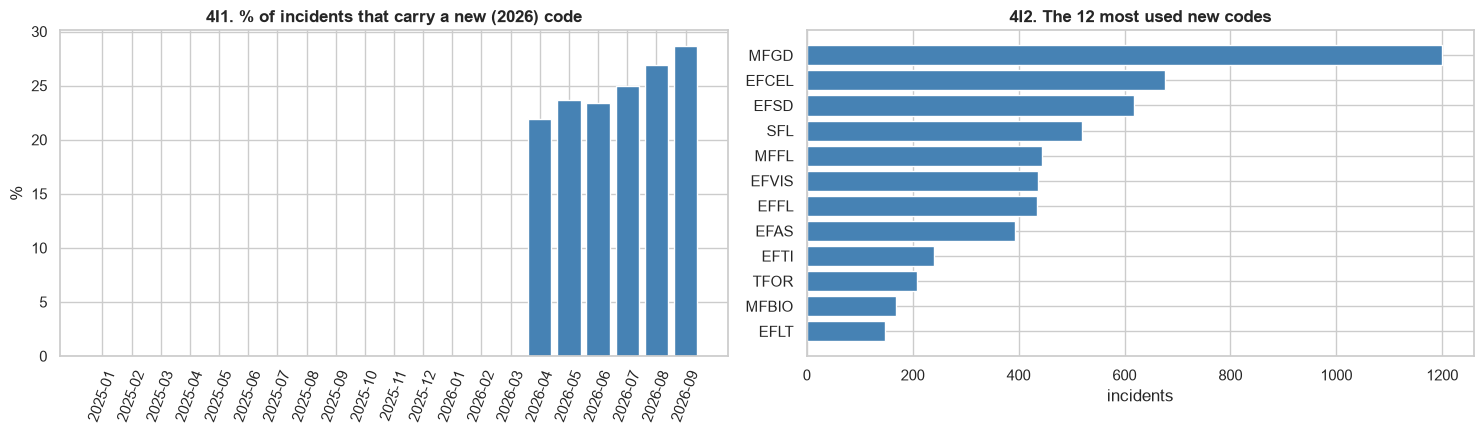

In [48]:
first_seen = incidents.groupby("code")["date"].agg(first_seen="min", n="size")
new_codes = first_seen[first_seen["first_seen"] >= "2026-01-01"].sort_values("n", ascending=False)
incidents["new_code"] = incidents["code"].isin(new_codes.index)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
share_new = incidents.groupby("month")["new_code"].mean() * 100
axes[0].bar(share_new.index.astype(str), share_new.values, color="steelblue")
axes[0].set(title="4I1. % of incidents that carry a new (2026) code", ylabel="%")
axes[0].tick_params(axis="x", rotation=70)
top_new = new_codes.head(12).iloc[::-1]
axes[1].barh(top_new.index, top_new["n"], color="steelblue")
axes[1].set(title="4I2. The 12 most used new codes", xlabel="incidents")
plt.tight_layout()
print(f"{len(new_codes)} codes first used in 2026, {int(new_codes['n'].sum()):,} incidents.")
print("First-use dates:", new_codes["first_seen"].dt.date.value_counts().head(3).to_dict())

**How to read it:** the left chart shows the share of each month's incidents that use a code never seen before 2026. The right chart shows which new codes are most used.

**What stands out:**
- **36 new codes appeared, and 25 of them on the very first days of the new scheme (1 to 2 April 2026)**. Before April the share is 0. From April it is **21% and grows to 29% by September**.
- The biggest new codes are `MFGD`, `EFCEL`, `EFSD`, `SFL`, `MFFL` and others, which split up the old "other" boxes.
- Most of these new codes are not in the code description file, so in notebook 01 they are labelled "Not in reference table" (they have no description, but their letter still gives the group).

**Why it matters:** **on 2026-04-01 the TTC changed its coding scheme.** From then on, about a quarter of incidents are coded differently. Before and after April 2026 are not recorded the same way.

### 4J. Where did `EFO` go?
`EFO` ('Equipment: other') before April 2026 versus the new equipment codes after.

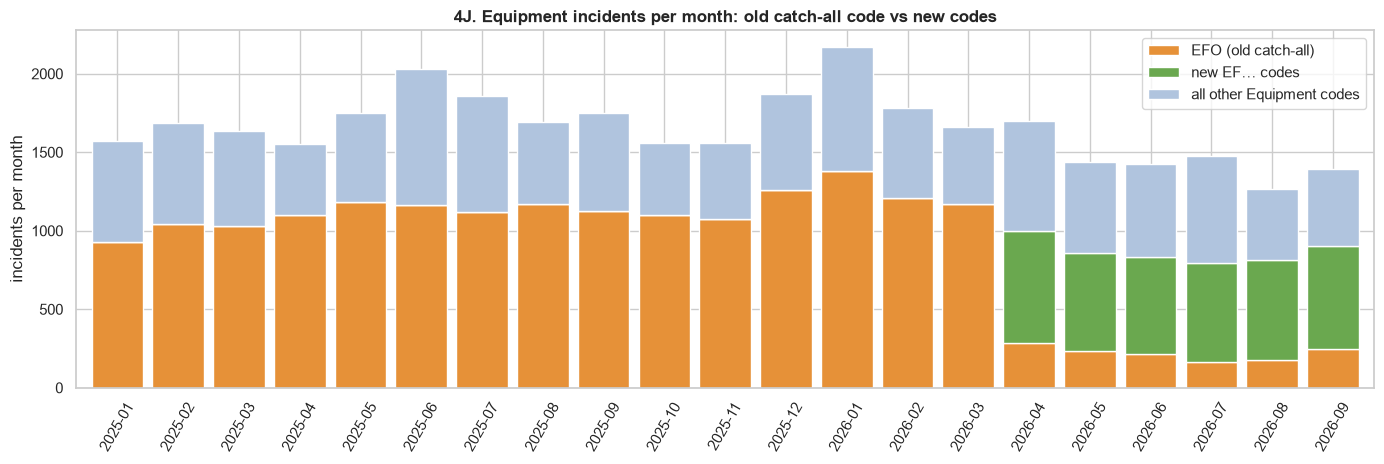

In [49]:
equipment_month = pd.DataFrame({
    "EFO (old catch-all)": incidents[incidents["code"] == "EFO"].groupby("month").size(),
    "new EF… codes": incidents[incidents["new_code"] & incidents["code"].str.startswith("EF")].groupby("month").size(),
    "all other Equipment codes": incidents[(incidents["cause_group"] == "Equipment") & (incidents["code"] != "EFO") & ~incidents["new_code"]].groupby("month").size(),
}).fillna(0)
equipment_month.index = equipment_month.index.astype(str)
fig, ax = plt.subplots(figsize=(14, 4.8))
equipment_month.plot.bar(stacked=True, ax=ax, color=["#e69138", "#6aa84f", "lightsteelblue"], width=0.85)
ax.set(title="4J. Equipment incidents per month: old catch-all code vs new codes", xlabel="", ylabel="incidents per month")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()

**How to read it:** each bar is the number of Equipment incidents in a month, split by which code they got.

**What stands out:** until March 2026 the orange `EFO` block is about **900 to 1,400 a month**. In April it shrinks to about 280 and then 170 to 245, while **green new `EF…` codes appear with about 620 to 720 a month**. The old catch-all was split into specific codes. The whole Equipment group is also smaller afterwards (about 1,750 a month before April 2026, about 1,400 from May).

**Why it matters:** this confirms that the drop of `EFO` is a recording change, not a fix of the buses. When we compare a period before April 2026 with one after, we should compare at the level of *groups* (or just `MFDV`) and not at the level of single codes.

### 4K. Is `MFDV`'s share of incidents stable?

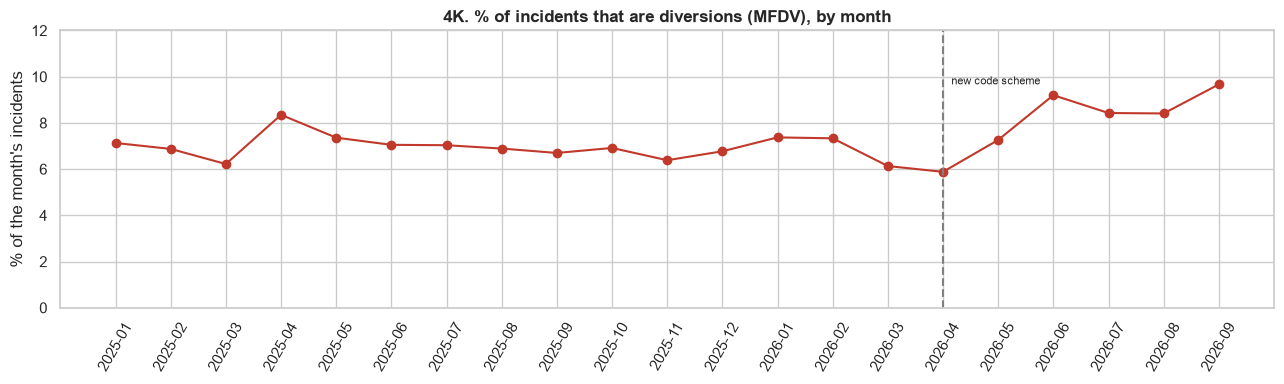

In [50]:
mfdv_share = (incidents["code"] == "MFDV").groupby(incidents["month"]).mean() * 100
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(mfdv_share.index.astype(str), mfdv_share.values, marker="o", color="#c0392b")
ax.axvline("2026-04", color="gray", ls="--")
ax.annotate("new code scheme", ("2026-04", mfdv_share.max()), xytext=(6, 0), textcoords="offset points", fontsize=8)
ax.set(title="4K. % of incidents that are diversions (MFDV), by month", xlabel="", ylabel="% of the month's incidents", ylim=(0, 12))
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()

**How to read it:** each point is the share of that month's incidents that are diversions. The dashed line marks the new coding scheme (April 2026).

**What stands out:** the share is **flat at about 6 to 8% through 2025**, and then **rises from June 2026 to 8 to 10%**. The *count* of diversions did not rise as much (4E). The share rises mostly because **total incidents fell** (about 140 a day in July and August 2026, vs 170 to 190 in summer 2025; see 1C).

**Why it matters:** if we use "share of incidents that are diversions", 2026 looks higher than 2025 even though the number of diversions is similar. The count per day is the safer measure.

### 4L. When do diversions happen? By weekday, and the biggest days

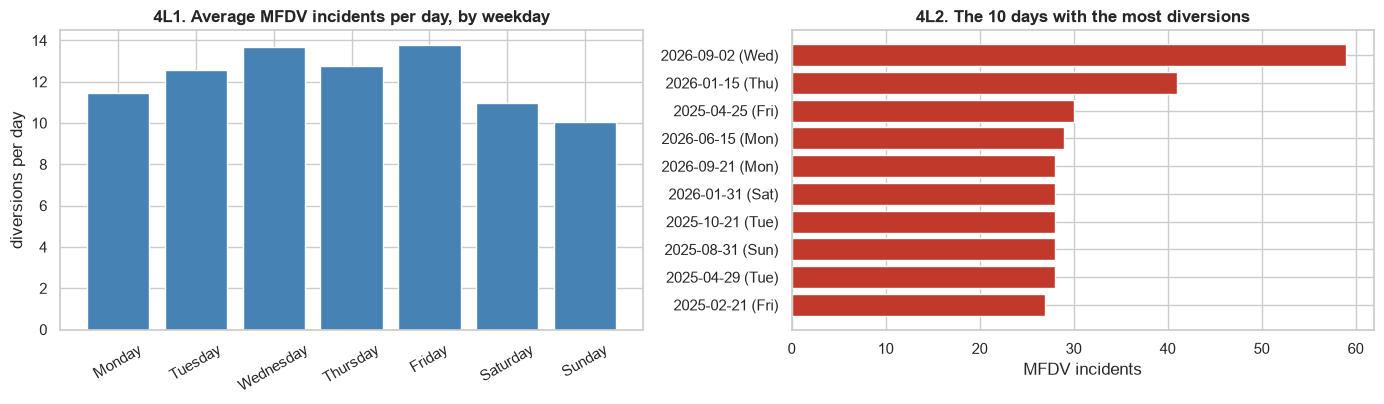

In [51]:
mfdv = incidents[incidents["code"] == "MFDV"]
by_day = (mfdv.groupby("weekday").size() / daily.groupby("weekday").size()).reindex(WEEKDAYS)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(by_day.index, by_day.values, color="steelblue")
axes[0].set(title="4L1. Average MFDV incidents per day, by weekday", ylabel="diversions per day")
axes[0].tick_params(axis="x", rotation=30)
top_days = mfdv.groupby("date").size().nlargest(10).sort_values()
axes[1].barh(top_days.index.strftime("%Y-%m-%d (%a)"), top_days.values, color="#c0392b")
axes[1].set(title="4L2. The 10 days with the most diversions", xlabel="MFDV incidents")
plt.tight_layout()

**How to read it:** the left chart shows the average number of diversions per day for each weekday. The right chart lists the ten days with the most diversions.

**What stands out:**
- **By weekday the numbers are fairly even**: about 10 to 14 diversions per day (a typical day has 11 to 12). Friday and Wednesday are highest (13.8 and 13.7) and Sunday is lowest (10.1). That is a much smaller weekday gap than for all incidents (Sunday 125 vs Friday 187), and Sunday's *share* of incidents is the highest, 8.1%.
- The top days are **2026-09-02 (59)** and **2026-01-15 (41)**, both days with extreme weather in the README (43 mm of rain, and 20 cm of snow). The next days have 28 to 30, which is still more than twice a typical day. The top two are weather days, not event days.

**Why it matters:** weather days produce the largest diversion spikes. If weather is not controlled, a few extreme days could look like (or hide) an event effect.

### 4M. Which hours do the biggest codes happen in?
Each column is one code; each cell is the share of that code's incidents in that hour of the day.

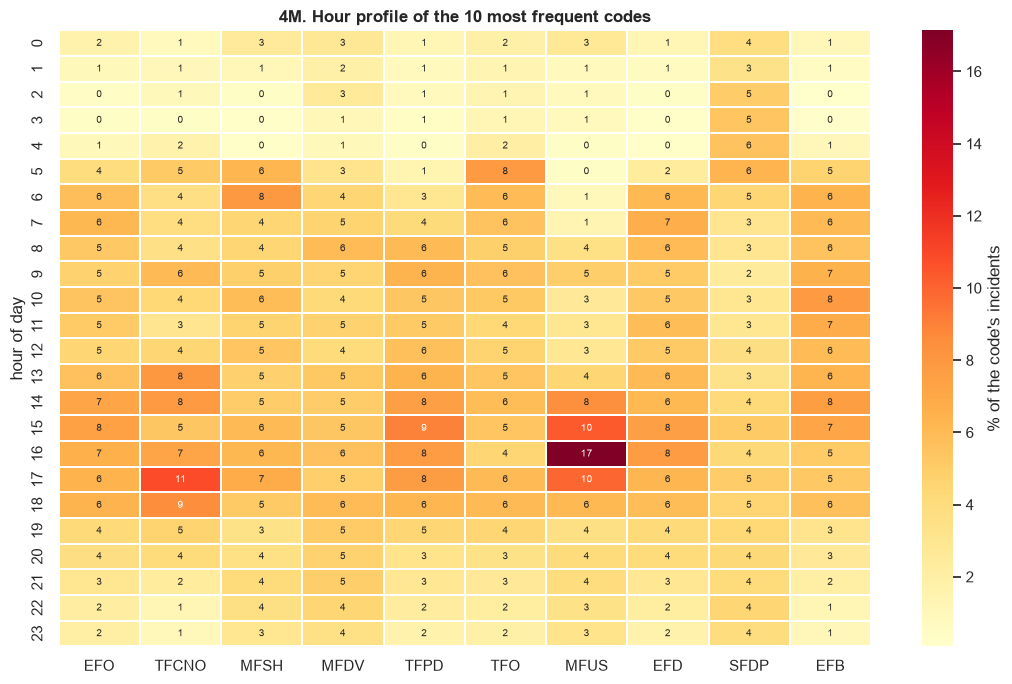

In [52]:
top10_codes = codes["code"].head(10).tolist()
code_hour = pd.crosstab(incidents["hour"], incidents["code"])[top10_codes]
code_hour = code_hour / code_hour.sum() * 100
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(code_hour, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 7}, linewidths=0.3, cbar_kws={"label": "% of the code's incidents"}, ax=ax)
ax.set(title="4M. Hour profile of the 10 most frequent codes", xlabel="", ylabel="hour of day")
plt.tight_layout()

**How to read it:** each column adds up to 100%. A dark cell means the code often happens at that hour.

**What stands out:**
- **`MFUS` is the afternoon code**: 17% of its incidents are at 4 pm, and **52% between 2 and 6 pm** (all incidents: 33%). This fits "unable to maintain schedule" in congestion.
- **`SFDP` (disorderly patron)** is a **night** code: 23% of its incidents are between midnight and 5 am.
- `TFCNO` (no operator available) and `TFPD` (collision) peak in the late afternoon (40% and 38% between 2 and 6 pm). `MFSH` (shuttle bus) peaks at 6 am (8%).
- `MFDV` is spread **flat** over the day (no hour above 6%).

**Why it matters:** codes have their own daily rhythm. A comparison of event windows with normal hours has to be at the **same hour**. Otherwise a code that is naturally an afternoon code would look like an event effect.

### 4N. Routes near a venue: a different mix of causes?

,MFDV (diversion),MFPR (parade hold)
near_venue,,
other routes,7.16,0.04
route near a venue,9.81,0.47


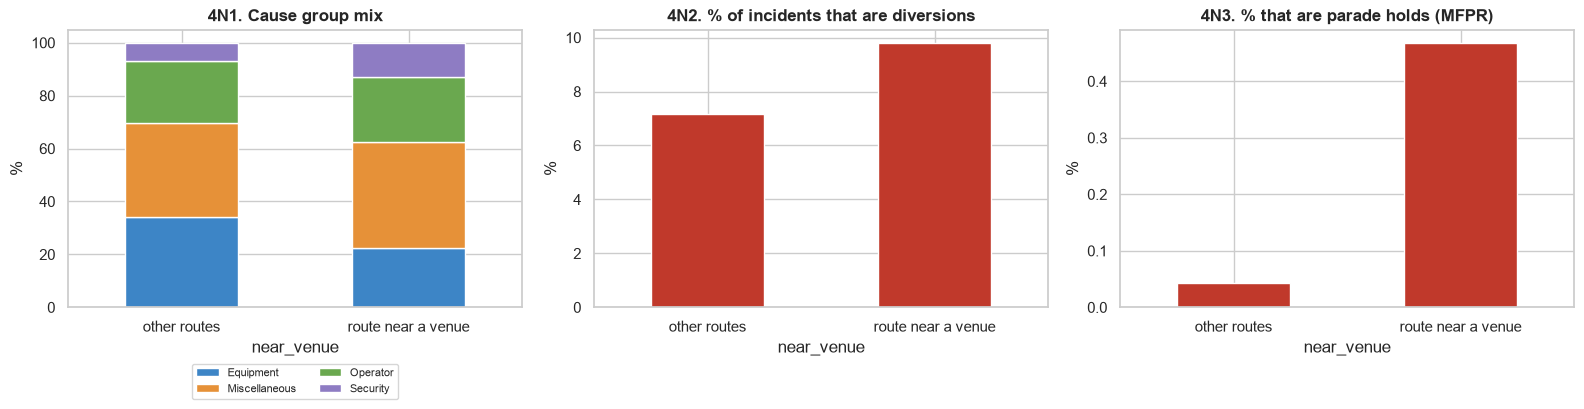

In [53]:
located_mix = incidents.dropna(subset=["near_venue"])
near_mix = pd.crosstab(located_mix["near_venue"].map({False: "other routes", True: "route near a venue"}), located_mix["cause_group"], normalize="index")
near_mix = near_mix[["Equipment", "Miscellaneous", "Operator", "Security"]] * 100
code_rates = pd.DataFrame({
    "MFDV (diversion)": located_mix.assign(v=located_mix["code"] == "MFDV").groupby("near_venue")["v"].mean() * 100,
    "MFPR (parade hold)": located_mix.assign(v=located_mix["code"] == "MFPR").groupby("near_venue")["v"].mean() * 100,
})
code_rates.index = code_rates.index.map({False: "other routes", True: "route near a venue"})

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
near_mix.plot.bar(stacked=True, ax=axes[0], color=["#3d85c6", "#e69138", "#6aa84f", "#8e7cc3"], rot=0, legend=False)
axes[0].set(title="4N1. Cause group mix", ylabel="%")
code_rates["MFDV (diversion)"].plot.bar(ax=axes[1], color="#c0392b", rot=0)
axes[1].set(title="4N2. % of incidents that are diversions", ylabel="%")
code_rates["MFPR (parade hold)"].plot.bar(ax=axes[2], color="#c0392b", rot=0)
axes[2].set(title="4N3. % that are parade holds (MFPR)", ylabel="%")
axes[0].legend(ncol=2, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.35))
plt.tight_layout()
code_rates.round(2)

**How to read it:** the same incidents split into routes with a stop within 1 km of Rogers Centre, Scotiabank Arena or BMO Field, and all others. Routes missing from the GTFS feed are left out.

**What stands out:**
- **Security** is almost twice as common near venues (**12.9% vs 6.9%** of incidents). Equipment is lower (22% vs 34%).
- **Diversions** are a little more common near venues (**9.8% vs 7.2%**).
- **Parade holds (`MFPR`) are about 12 times more common** near venues (0.47% vs 0.04%), as expected, because parades and marches run downtown. But the numbers are tiny: a few dozen incidents.

**Why it matters:** this is a first sign that "near a venue" captures a real difference (more security issues, more diversions, more parade holds). It is a difference between *routes*, on all days, not yet an event effect.

### 4O. Does the rise in typical delay (2J) come from `MFUS`?
In Step 2 the median delay rose from 12 to 15 minutes around December 2025, when `MFUS` also changed. Check if `MFUS` is the reason.

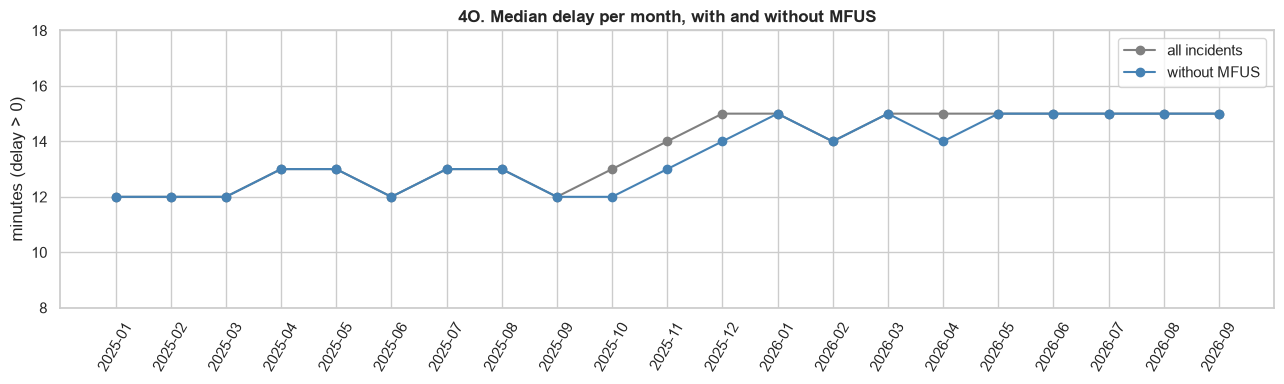

In [54]:
median_all = incidents[incidents["is_delay"]].groupby("month")["min_delay"].median()
median_no_mfus = incidents[incidents["is_delay"] & (incidents["code"] != "MFUS")].groupby("month")["min_delay"].median()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(median_all.index.astype(str), median_all.values, marker="o", label="all incidents", color="gray")
ax.plot(median_no_mfus.index.astype(str), median_no_mfus.values, marker="o", label="without MFUS", color="steelblue")
ax.set(title="4O. Median delay per month, with and without MFUS", xlabel="", ylabel="minutes (delay > 0)", ylim=(8, 18))
ax.tick_params(axis="x", rotation=60)
ax.legend()
plt.tight_layout()

**How to read it:** the grey line is the monthly typical delay from Step 2. The blue line is the same without the `MFUS` incidents.

**What stands out:** the **two lines are almost identical**. Both rise from 12 to 15 minutes between 2025 and early 2026. So `MFUS` is **not** the reason.

**Why it matters:** the rise is gradual and general, and not caused by the coding changes we found. We keep this as a known drift in delay length (it is another reason to compare event days only with nearby non-event days, in the same period).

### Step 4 takeaways
- The most frequent code, `EFO` ("other", 17%), says little. The codes that matter for service are fewer: **`MFDV` (diversions) is 7% of incidents but 36% of all delay minutes**, with a typical delay of 71 minutes. 89% of incidents of an hour or longer are diversions.
- **Miscellaneous** (36% of incidents) is 56% of delay minutes. Security issues happen mostly at night, Equipment problems in the morning, and the codes `MFUS`, `TFPD` and `TFCNO` in the afternoon.
- **`MFDV` is steady** (about 370 a month, same share on every weekday). Its biggest days are **weather days** (2026-09-02 and 2026-01-15), not event days.
- **`MFPR` (parade holds) is too rare** (about 85 incidents in 21 months) to be analysed alone.
- **The logging changed.** `MFUS` changed in December 2025 and in April 2026. On **2026-04-01** 36 new codes were introduced, `EFO` fell by about 80%, and about a quarter of later incidents use a new code. We should compare groups, or `MFDV`, and not single codes across that date.
- Routes **near a venue** have more Security incidents (12.9% vs 6.9%), more diversions (9.8% vs 7.2%) and many more parade holds, but this is not yet an event effect.
- The slow rise in typical delay (12 to 15 minutes) is **not** caused by the coding changes.

*(Numbers in the notes come from the data as run on this version.)*

## Step 5. Where do incidents happen? Routes and places

Two kinds of location information:
- **`route`**: the route number taken from `line` (e.g. 29 from "29 DUFFERIN"). Shuttles, training buses and blanks have none (1.7% of incidents).
- **`location`**: free text typed by staff (a station, a garage, an intersection). It is cut at 22 characters.

From notebook 01 we also have, for each route, the distance from the **nearest stop of the route to each venue** (`dist_venue_km`), and `near_venue` (within 1 km).

**Cautions for this step:**
1. We have **no data on how much service each route runs**. Busy routes are also long routes with many buses, so raw counts mostly show size.
2. A route is a long line. "Near a venue" means *some stop* of the route is near; an incident on that route may be far from the venue.
3. The GTFS feed is from Nov-Dec 2026, so a few routes (about 4% of incidents) have no location.

In [55]:
RAW_GTFS = PROCESSED / "gtfs_stops.csv"
gtfs_stops = pd.read_csv(RAW_GTFS, dtype={"stop_id": str})
gtfs_route_stops = pd.read_csv(PROCESSED / "gtfs_route_stops.csv", dtype=str)
route_venue_dist = pd.read_csv(PROCESSED / "route_venue_dist.csv")

def route_family(route):
    """TTC route numbering: 300s = night (Blue Night), 500s = streetcar, 900s = express, others regular."""
    if pd.isna(route):
        return np.nan
    route = int(route)
    if 300 <= route < 400:
        return "night (3xx)"
    if 500 <= route < 600:
        return "streetcar (5xx)"
    if 900 <= route < 1000:
        return "express (9xx)"
    return "regular (<300)" if route < 300 else "other"

incidents["route_family"] = incidents["route"].map(route_family)
FAMILIES = ["regular (<300)", "express (9xx)", "night (3xx)", "streetcar (5xx)", "other"]
FAMILY_COLORS = dict(zip(FAMILIES, ["steelblue", "#e69138", "#4c4c7a", "#6aa84f", "gray"]))

stops_per_route = gtfs_route_stops.groupby("route_short_name")["stop_id"].nunique()
stops_per_route.index = pd.to_numeric(stops_per_route.index, errors="coerce")
route_table = incidents.groupby("route").agg(
    incidents=("code", "size"),
    median_delay=("min_delay", lambda s: s[s > 0].median()),
    share_diversion=("code", lambda s: (s == "MFDV").mean() * 100),
    delay_minutes=("delay_capped", "sum"),
).join(stops_per_route.rename("stops")).join(route_venue_dist.set_index("route")).sort_values("incidents", ascending=False)
route_table["family"] = [route_family(r) for r in route_table.index]
print(f"{len(route_table)} routes with incidents | {incidents['route'].notna().mean():.1%} of incidents have a route number")
route_table.head(10).round(1)

251 routes with incidents | 98.3% of incidents have a route number


,incidents,median_delay,share_diversion,delay_minutes,stops,dist_rogers_km,dist_scotiabank_km,dist_bmo_km,dist_venue_km,near_venue,family
route,,,,,,,,,,,
52.0,2499,20.0,4.4,50748,217.0,8.9,8.7,9.4,8.7,False,regular (<300)
32.0,2143,12.0,3.9,29518,38.0,9.2,9.8,8.0,8.0,False,regular (<300)
102.0,2049,12.0,5.3,39621,172.0,11.9,11.2,14.3,11.2,False,regular (<300)
29.0,2008,10.0,8.2,40195,98.0,1.8,2.6,0.1,0.1,True,regular (<300)
7.0,1931,10.0,4.9,24792,111.0,3.2,3.6,3.7,3.2,False,regular (<300)
939.0,1807,15.0,5.1,29873,76.0,15.3,15.3,15.6,15.3,False,express (9xx)
63.0,1764,10.0,9.5,28896,69.0,1.8,2.6,0.6,0.6,True,regular (<300)
54.0,1689,14.0,4.7,30223,126.0,9.8,9.3,11.8,9.3,False,regular (<300)
116.0,1633,8.0,4.0,18443,104.0,14.3,13.5,16.6,13.5,False,regular (<300)


### 5A. The 15 routes with the most incidents

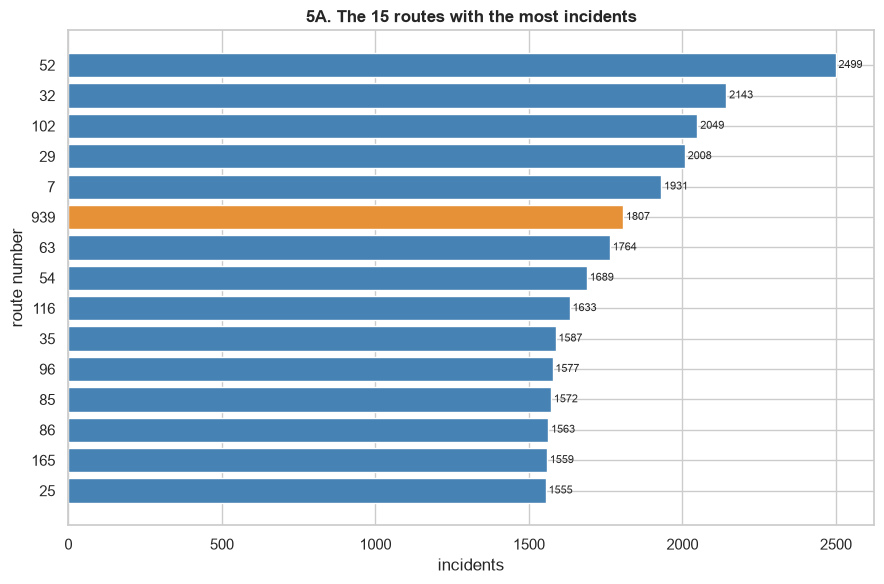

In [56]:
top_routes = route_table.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top_routes.index.astype(int).astype(str), top_routes["incidents"],
               color=[FAMILY_COLORS[f] for f in top_routes["family"]])
ax.bar_label(bars, fontsize=8, padding=2)
ax.set(title="5A. The 15 routes with the most incidents", xlabel="incidents", ylabel="route number")
plt.tight_layout()

**How to read it:** each bar is a route (number on the left); longer = more incidents. Blue = regular route, orange = express (9xx).

**What stands out:** the busiest routes are **52 Lawrence West (2,499), 32 Eglinton West (2,143), 102 Markham Road (2,049), 29 Dufferin (2,008)** and 7 Bathurst (1,931). The only express route in the top 15 is **939 Finch Express (1,807)**.

**Why it matters:** these are all big, busy routes. The ranking says which routes have the most trouble, but it does not tell us whether trouble per bus is higher (see 5C and 5D).

### 5B. How concentrated are incidents on a few routes?

Routes needed for half of all incidents: 37 of 251


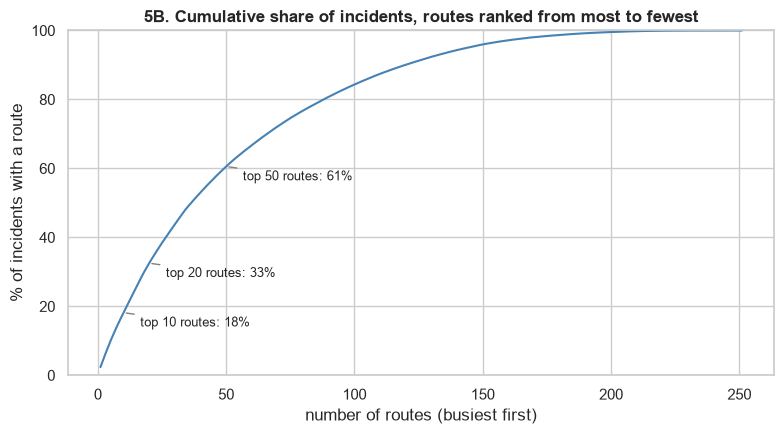

In [57]:
by_route = route_table["incidents"].to_numpy()
cum_share = np.cumsum(by_route) / by_route.sum()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.arange(1, len(cum_share) + 1), cum_share * 100, color="steelblue")
for k in (10, 20, 50):
    ax.annotate(f"top {k} routes: {cum_share[k - 1]:.0%}", (k, cum_share[k - 1] * 100), xytext=(12, -10), textcoords="offset points", fontsize=9,
                arrowprops=dict(arrowstyle="-", color="gray"))
ax.set(title="5B. Cumulative share of incidents, routes ranked from most to fewest", xlabel="number of routes (busiest first)", ylabel="% of incidents with a route", ylim=(0, 100))
plt.tight_layout()
print(f"Routes needed for half of all incidents: {int((cum_share < 0.5).sum() + 1)} of {len(cum_share)}")

**How to read it:** routes are lined up from the one with the most incidents to the one with the fewest. The curve shows what share of all incidents the busiest *n* routes hold.

**What stands out:** it is spread out rather than concentrated. The top 10 routes hold only **18%** of incidents, the top 20 hold 33%, and it takes **37 of 251 routes to reach half**.

**Why it matters:** incidents happen all over the network, not on just a handful of routes. A few "problem routes" do not explain the totals, so the network-wide hourly pattern from Step 3 is a fair baseline.

### 5C. Is it just route size? Incidents vs number of stops

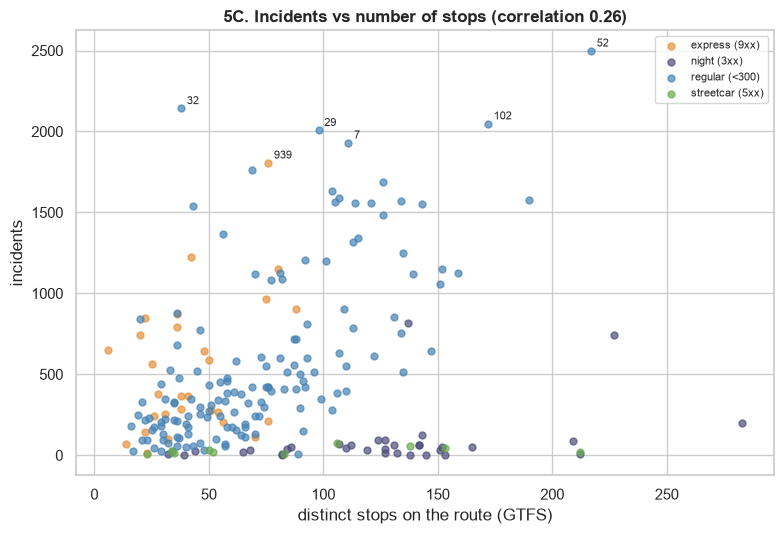

In [58]:
sized = route_table.dropna(subset=["stops"])
fig, ax = plt.subplots(figsize=(8, 5.5))
for family, group in sized.groupby("family"):
    ax.scatter(group["stops"], group["incidents"], label=family, color=FAMILY_COLORS[family], alpha=0.7, s=25)
for route, row in sized.nlargest(6, "incidents").iterrows():
    ax.annotate(str(int(route)), (row["stops"], row["incidents"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set(title=f"5C. Incidents vs number of stops (correlation {sized['incidents'].corr(sized['stops']):.2f})", xlabel="distinct stops on the route (GTFS)", ylabel="incidents")
ax.legend(fontsize=8)
plt.tight_layout()

**How to read it:** each dot is a route. Right means more stops (a longer route), up means more incidents.

**What stands out:** the relationship is **weak (correlation 0.26)**. Some small routes have very many incidents (route 32 has only 38 stops but 2,143 incidents), and the biggest route by incidents (52) has 217 stops. **Night routes (dark purple)** have many stops but few incidents, probably because they run only at night.

**Why it matters:** the number of stops is not a good stand-in for how much service a route runs. Without data on buses and trips, **route-to-route comparisons are unreliable**. It is safer to compare a route with its own normal level, which is what notebook 03 should do.

### 5D. Incidents per stop: which routes are busy for their size?
Routes with at least 200 incidents. Number of stops is only a rough size measure.

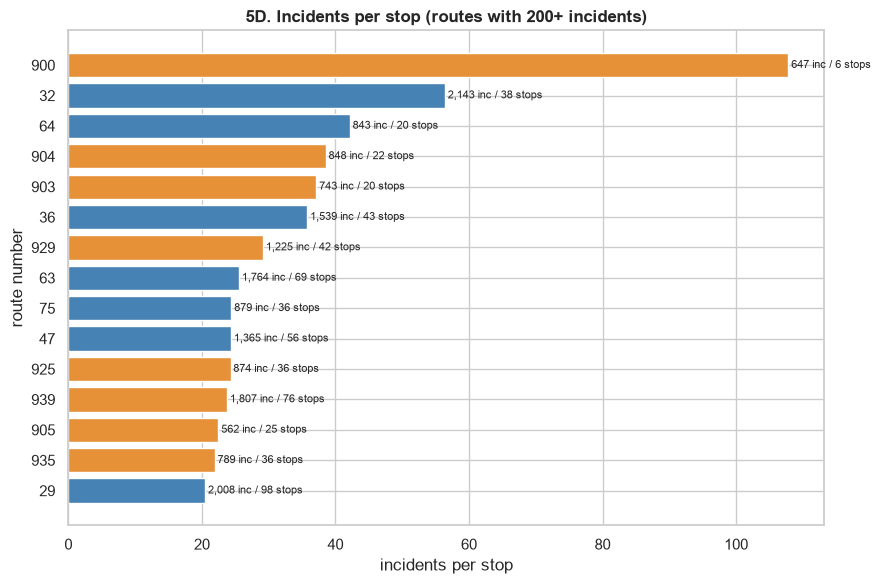

In [59]:
rate = sized[sized["incidents"] >= 200].assign(per_stop=lambda t: t["incidents"] / t["stops"]).nlargest(15, "per_stop").iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(rate.index.astype(int).astype(str), rate["per_stop"], color=[FAMILY_COLORS[f] for f in rate["family"]])
ax.bar_label(bars, labels=[f"{n:,.0f} inc / {s:.0f} stops" for n, s in zip(rate["incidents"], rate["stops"])], fontsize=8, padding=2)
ax.set(title="5D. Incidents per stop (routes with 200+ incidents)", xlabel="incidents per stop", ylabel="route number")
plt.tight_layout()

**How to read it:** incidents divided by the number of stops on the route, for routes with at least 200 incidents. High = many incidents for a short route.

**What stands out:** very short, busy routes come out on top, led by **route 900 (108 incidents per stop, only 6 stops)** and **route 32 (56 per stop)**. The long routes with the most incidents (52, 102) are not here.

**Why it matters:** short routes with a lot of trouble per stop are probably running **a lot of buses** (many trips on a short line), not "worse" service. This chart shows why a per-stop rate is hard to interpret: it only partly corrects for size.

### 5E. Delay length and diversion share on the busiest routes

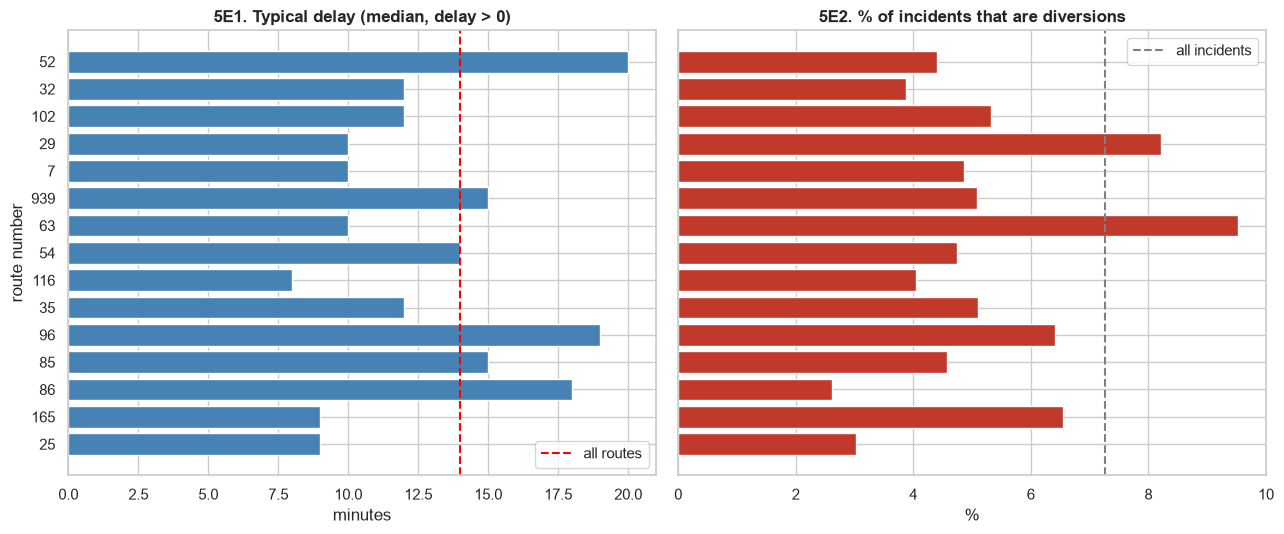

In [60]:
busy = route_table.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
labels = busy.index.astype(int).astype(str)
axes[0].barh(labels, busy["median_delay"], color="steelblue")
axes[0].axvline(incidents.loc[incidents["is_delay"], "min_delay"].median(), color="red", ls="--", label="all routes")
axes[0].set(title="5E1. Typical delay (median, delay > 0)", xlabel="minutes", ylabel="route number")
axes[0].legend()
axes[1].barh(labels, busy["share_diversion"], color="#c0392b")
axes[1].axvline((incidents["code"] == "MFDV").mean() * 100, color="gray", ls="--", label="all incidents")
axes[1].set(title="5E2. % of incidents that are diversions", xlabel="%")
axes[1].legend()
plt.tight_layout()

**How to read it:** each row is one of the 15 busiest routes. Left: typical delay; the red line is the all-routes median. Right: the share of that route's incidents that are diversions; the grey line is the all-incident share (7.3%).

**What stands out:**
- **Route 52 has a much longer typical delay (20 minutes)** than the rest, while routes 116, 63, 29 and 7 are at 8 to 10.
- **Diversion shares differ a lot**: route 63 Ossington (9.5%) and route 29 Dufferin (8.2%) are well above average, route 86 (2.6%) is far below.

**Why it matters:** routes 29 and 63 are the two busiest routes that are also **near a venue**, and they have more diversions than most. That is a reason to look at route 29 and 63 specifically in notebook 03.

### 5F. Route families
TTC route numbers: 300s = night buses, 500s = streetcars, 900s = express buses, the rest regular routes.

,incidents,routes,median_delay,share_diversion,incidents_per_route
route_family,,,,,
regular (<300),85602,154,15.0,7.7,555.9
express (9xx),15620,31,10.0,4.8,503.9
night (3xx),3039,37,20.0,10.8,82.1
streetcar (5xx),351,16,10.0,6.3,21.9
other,611,13,7.0,0.5,47.0


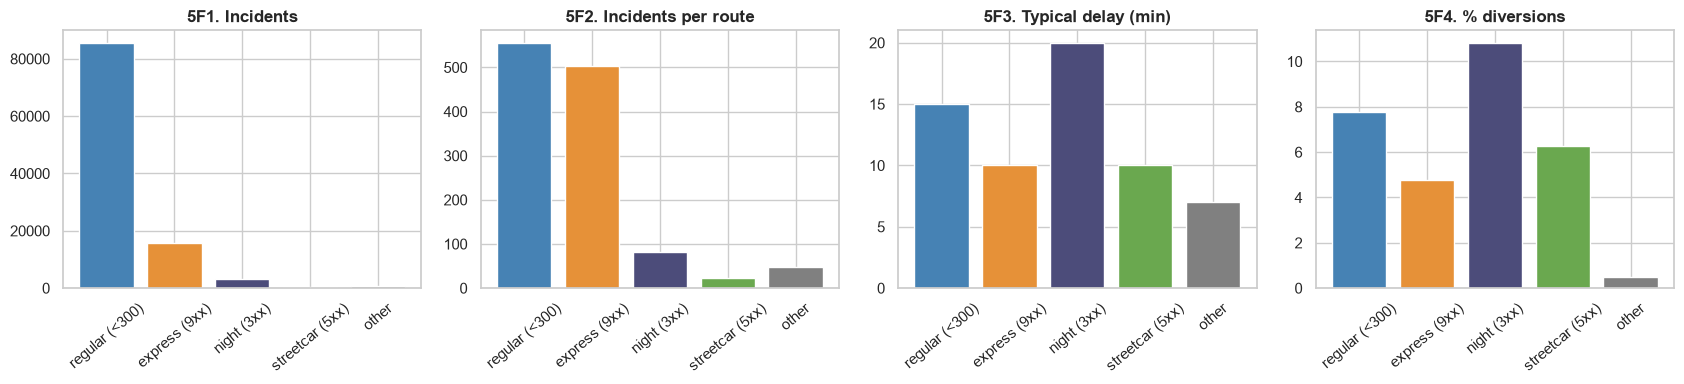

In [61]:
family_stats = incidents.dropna(subset=["route_family"]).groupby("route_family").agg(
    incidents=("code", "size"), routes=("route", "nunique"), median_delay=("min_delay", lambda s: s[s > 0].median()),
    share_diversion=("code", lambda s: (s == "MFDV").mean() * 100)).reindex(FAMILIES).dropna()
family_stats["incidents_per_route"] = family_stats["incidents"] / family_stats["routes"]

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (col, title) in zip(axes, [("incidents", "5F1. Incidents"), ("incidents_per_route", "5F2. Incidents per route"),
                                   ("median_delay", "5F3. Typical delay (min)"), ("share_diversion", "5F4. % diversions")]):
    ax.bar(family_stats.index, family_stats[col], color=[FAMILY_COLORS[f] for f in family_stats.index])
    ax.set(title=title)
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
family_stats.round(1)

**How to read it:** four views of the route families (night = 300s, streetcar = 500s, express = 900s, rest = regular). `other` is route numbers like 999 and 600, which look like special codes and not real routes.

**What stands out:**
- **Regular routes** hold 80% of incidents (85,602) and **express routes** 15% (15,620). The per-route average is similar for both (about 500 to 560).
- **Night routes (3xx)** have few incidents per route (82) but **the longest typical delay (20 minutes) and the highest diversion share (10.8%)**.
- Streetcar routes (5xx) appear in only 351 incidents.

**Why it matters:** night routes behave differently from daytime routes. Because they matter near the venues (see 5L), they can distort a "near venue" comparison unless night hours are handled separately.

### 5G. Are the busiest routes stable over time?
Top 12 routes, incidents per month. A route that suddenly changes may have been renumbered or re-coded.

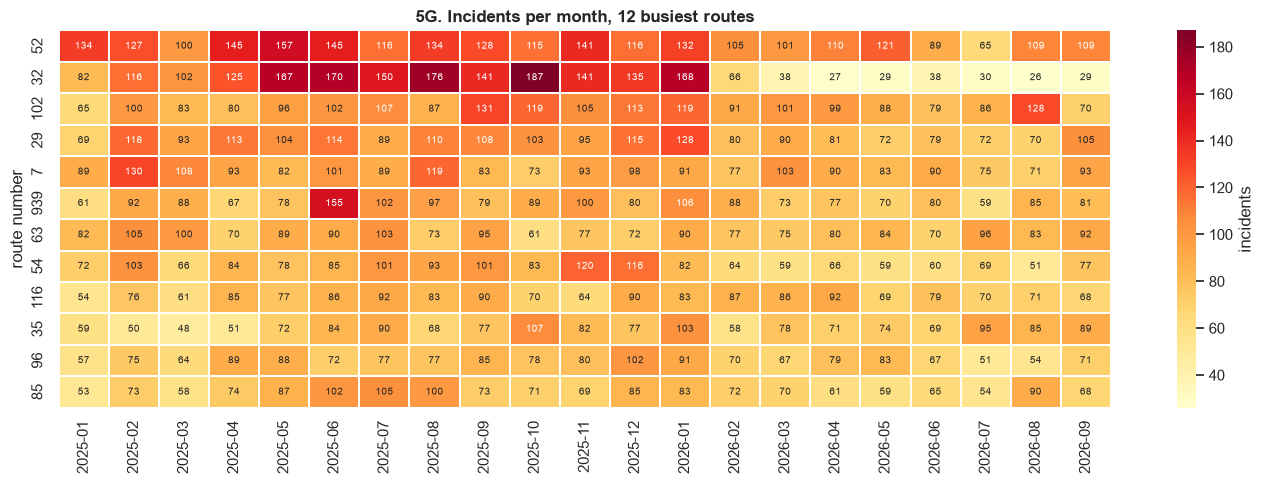

In [62]:
top12_routes = route_table.head(12).index
route_month = pd.crosstab(incidents["route"], incidents["month"]).loc[top12_routes]
route_month.index = route_month.index.astype(int).astype(str)
route_month.columns = route_month.columns.astype(str)
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(route_month, cmap="YlOrRd", annot=True, fmt="d", annot_kws={"size": 7}, linewidths=0.3, cbar_kws={"label": "incidents"}, ax=ax)
ax.set(title="5G. Incidents per month, 12 busiest routes", xlabel="", ylabel="route number")
plt.tight_layout()

**How to read it:** each row is a route, each column a month. Darker = more incidents. Rows should look the same all the way across if the route is stable.

**What stands out:** most routes move between about 50 and 130 incidents a month. **Route 32 is a big exception**: it runs at 100 to 187 incidents a month through 2025 and January 2026, then **drops to 66 in February 2026 and about 30 a month from March**. Compared with April to September 2025, route 32 has 81% fewer incidents in April to September 2026, and route 36 has 66% fewer. The median route changed by about -21%.

**What it means:** routes 32 (Eglinton West) and 36 (Finch West) run along the same corridors as the Eglinton Line (route 5) and Finch West Line (route 6), which now appear in the 2026 route list. **Service on these routes probably changed**, which would explain the drop, though we cannot confirm that from this data alone.

**Why it matters:** the same route in 2025 and in 2026 is not the same service. A route's own baseline needs to be built within a similar period.

### 5H. How far are routes from the venues?
Distance from each route's nearest stop to the closest of the three venues (Rogers Centre, Scotiabank Arena, BMO Field).

227 routes | within 1 km: 21 | within 3 km: 33 | within 5 km: 64


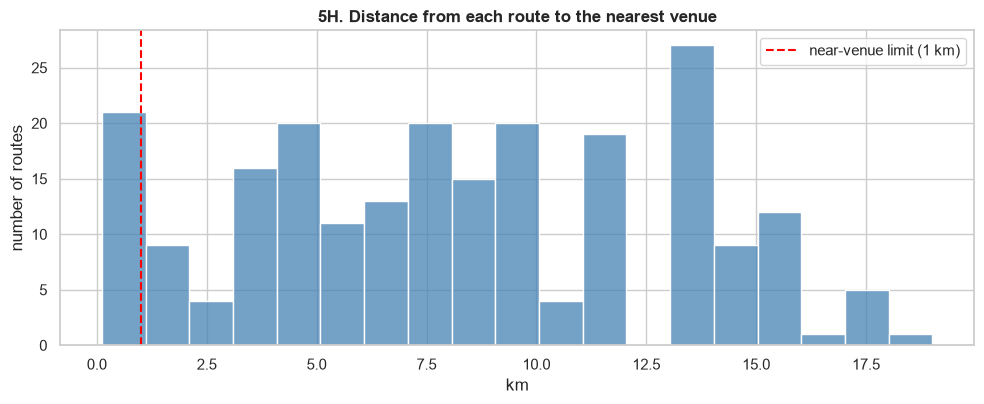

In [63]:
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.histplot(route_venue_dist["dist_venue_km"], binwidth=1, color="steelblue", ax=ax)
ax.axvline(1, color="red", ls="--", label="near-venue limit (1 km)")
ax.set(title="5H. Distance from each route to the nearest venue", xlabel="km", ylabel="number of routes")
ax.legend()
plt.tight_layout()
print(f"{len(route_venue_dist)} routes | within 1 km: {route_venue_dist['near_venue'].sum()} | within 3 km: {(route_venue_dist['dist_venue_km'] <= 3).sum()} | within 5 km: {(route_venue_dist['dist_venue_km'] <= 5).sum()}")

**How to read it:** each bar counts routes in a 1-km band of distance from their nearest stop to the closest venue.

**What stands out:** **21 routes** have a stop within 1 km of a venue. **33 are within 3 km, 64 within 5 km**, and most of the network (163 routes) is more than 5 km away.

**Why it matters:** only a small group of routes is realistically exposed to venue traffic. The 1 km limit is a choice: at 3 km we would include 12 more routes.

### 5I. Routes and incidents by distance band

,routes,incidents,incidents_per_route,share_diversion
0-1 km,21,9399,447.6,9.8
1-3 km,12,4551,379.2,10.0
3-5 km,31,14233,459.1,7.9
5-10 km,84,33101,394.1,6.9
10+ km,79,41780,528.9,6.8


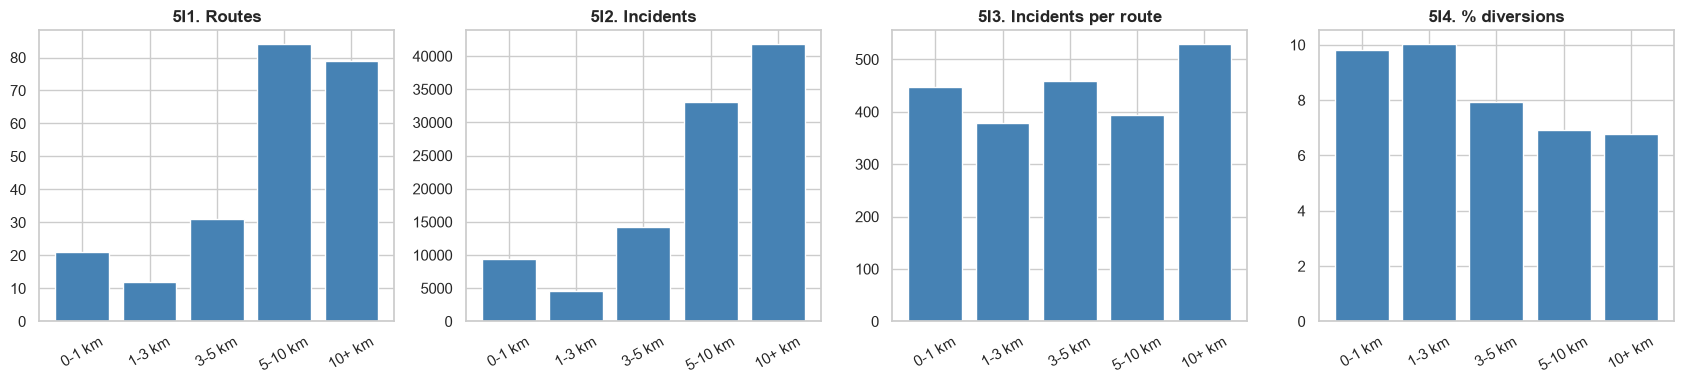

In [64]:
band_edges = [0, 1, 3, 5, 10, 100]
band_labels = ["0-1 km", "1-3 km", "3-5 km", "5-10 km", "10+ km"]
located = incidents.dropna(subset=["dist_venue_km"]).assign(band=lambda t: pd.cut(t["dist_venue_km"], band_edges, labels=band_labels))
bands = pd.DataFrame({
    "routes": pd.cut(route_venue_dist["dist_venue_km"], band_edges, labels=band_labels).value_counts(),
    "incidents": located["band"].value_counts(),
}).reindex(band_labels)
bands["incidents_per_route"] = bands["incidents"] / bands["routes"]
bands["share_diversion"] = located.groupby("band", observed=True)["code"].apply(lambda s: (s == "MFDV").mean() * 100)

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (col, title) in zip(axes, [("routes", "5I1. Routes"), ("incidents", "5I2. Incidents"),
                                   ("incidents_per_route", "5I3. Incidents per route"), ("share_diversion", "5I4. % diversions")]):
    ax.bar(bands.index, bands[col], color="steelblue")
    ax.set(title=title)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
bands.round(1)

**How to read it:** routes and incidents grouped by distance to the nearest venue. The third panel is incidents divided by the number of routes in the band; the fourth is the share of incidents that are diversions.

**What stands out:**
- Routes within 1 km have **9,399 incidents (9% of those with a location)**, and an average of 448 per route, close to every other band (379 to 529). **Being near a venue does not mean more incidents overall.**
- The **diversion share is higher near the venues**: about 10% within 3 km vs 6.8 to 7.9% beyond.

**Why it matters:** near-venue routes are not generally troubled routes. Diversions are the signal that differs, and that is the kind of incident we expect events to cause.

### 5J. The routes near a venue

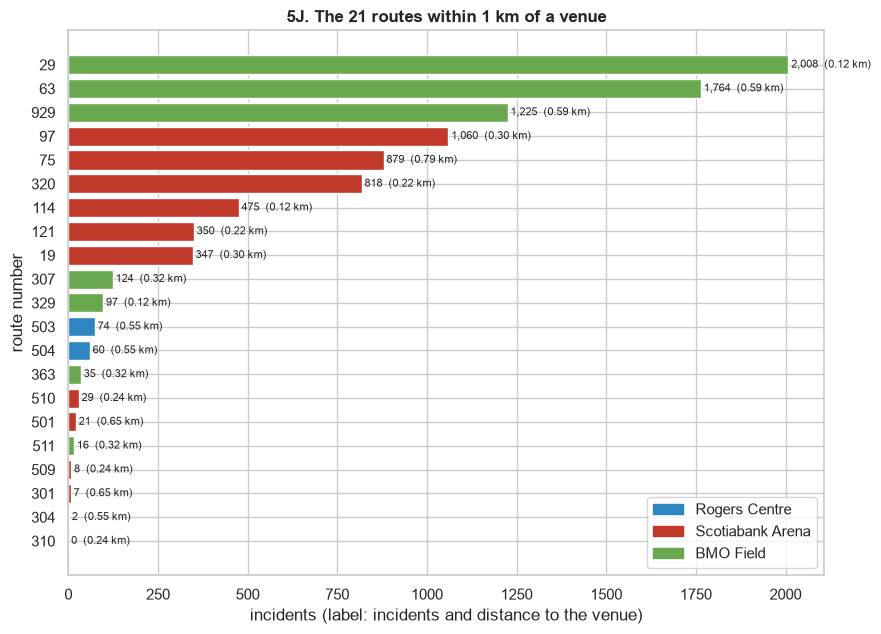

In [65]:
near = route_table[route_table["near_venue"] == True].copy()
venue_cols = {"dist_rogers_km": "Rogers Centre", "dist_scotiabank_km": "Scotiabank Arena", "dist_bmo_km": "BMO Field"}
near["closest_venue"] = near[list(venue_cols)].idxmin(axis=1).map(venue_cols)
venue_colors = {"Rogers Centre": "#2e86c1", "Scotiabank Arena": "#c0392b", "BMO Field": "#6aa84f"}
# routes near a venue but with no incident rows still appear (0)
near_all = route_venue_dist[route_venue_dist["near_venue"]].set_index("route").join(near[["incidents"]]).fillna({"incidents": 0})
near_all["closest_venue"] = near_all[list(venue_cols)].idxmin(axis=1).map(venue_cols)
near_all = near_all.sort_values("incidents")

fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(near_all.index.astype(str), near_all["incidents"], color=[venue_colors[v] for v in near_all["closest_venue"]])
ax.bar_label(bars, labels=[f"{n:,.0f}  ({d:.2f} km)" for n, d in zip(near_all["incidents"], near_all["dist_venue_km"])], fontsize=8, padding=2)
ax.set(title="5J. The 21 routes within 1 km of a venue", xlabel="incidents (label: incidents and distance to the venue)", ylabel="route number")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in venue_colors.values()], venue_colors.keys(), loc="lower right")
plt.tight_layout()

**How to read it:** each bar is a route within 1 km of a venue; the colour is the closest venue and the label shows incidents and the distance.

**What stands out:**
- **Route 29 Dufferin (2,008) and 63 Ossington (1,764)** carry by far the most incidents, then **929 Dufferin Express (1,225)**, 97 Yonge (1,060), 75 Sherbourne (879) and **320 Yonge night bus (818)**.
- 13 of the 21 routes are very close, about 0.1 to 0.3 km from their closest venue. Route 29 and its night/express versions (329, 929) are the ones near BMO Field, and routes 114 (Queens Quay East), 121 (Esplanade-River) and 320 (Yonge night) are near Scotiabank Arena.
- Many have very few incidents: the streetcar routes (501, 503, 504, 509, 510, 511) and some night routes (301, 304, 310) all have fewer than 125.

**Why it matters:** the group of near-venue routes is dominated by about six routes. Results for "near-venue routes" will mostly reflect routes 29, 63, 929, 97, 75 and 320.

### 5K. Map: stops, venues and the near-venue routes

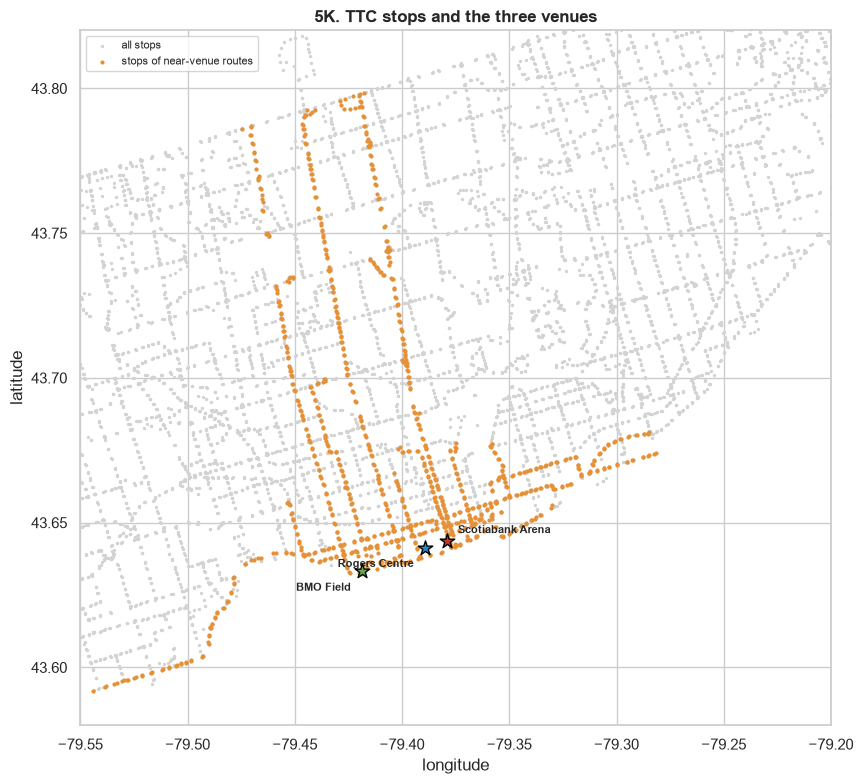

In [66]:
VENUES_XY = {"Rogers Centre": (43.6414, -79.3894), "Scotiabank Arena": (43.6435, -79.3791), "BMO Field": (43.6332, -79.4186)}
near_route_names = set(near_all.index.astype(str))
near_stop_ids = set(gtfs_route_stops.loc[gtfs_route_stops["route_short_name"].isin(near_route_names), "stop_id"])

fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(gtfs_stops["stop_lon"], gtfs_stops["stop_lat"], s=2, color="lightgray", label="all stops")
highlighted = gtfs_stops[gtfs_stops["stop_id"].isin(near_stop_ids)]
ax.scatter(highlighted["stop_lon"], highlighted["stop_lat"], s=4, color="#e69138", label="stops of near-venue routes")
for name, (lat, lon) in VENUES_XY.items():
    ax.scatter(lon, lat, s=120, marker="*", color=venue_colors[name], edgecolor="black", zorder=5)
    offset = {"Rogers Centre": (-8, -14), "Scotiabank Arena": (8, 6), "BMO Field": (-8, -14)}[name]
    ax.annotate(name, (lon, lat), xytext=offset, textcoords="offset points", fontsize=8, fontweight="bold",
                ha="right" if offset[0] < 0 else "left")
ax.set(title="5K. TTC stops and the three venues", xlabel="longitude", ylabel="latitude", aspect=1.35)
ax.set_xlim(-79.55, -79.2)
ax.set_ylim(43.58, 43.82)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()

**How to read it:** each grey dot is a TTC stop. Orange dots are stops on the 21 near-venue routes. Stars are the venues. Rogers Centre and Scotiabank Arena are only about 1 km apart, and BMO Field is to the west.

**What stands out:** the near-venue routes are the **north-south lines (Dufferin, Ossington, Yonge, Sherbourne) that end at the waterfront**, plus the east-west lines along the lake. They stretch far north: an incident on route 29 can be more than 10 km from BMO Field.

**Why it matters:** "near a venue" means the *route* is near, not the incident. A bus incident in North York on route 29 is counted as near-venue. This is a strong reason to focus on the hours around events, and to treat route-level distance as a rough guide only.

### 5L. Which kinds of routes are near venues?
Route family of incidents on near-venue routes vs other routes (shares add up to 100% within each group).

route_family,regular (<300),express (9xx),night (3xx),streetcar (5xx)
near_venue,,,,
other routes,83.2,14.7,2.0,0.1
routes near a venue,73.2,13.0,11.5,2.2


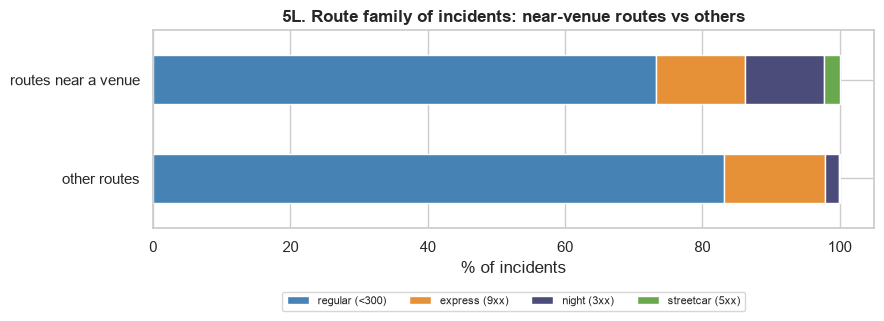

In [67]:
fam_near = pd.crosstab(incidents["near_venue"].map({False: "other routes", True: "routes near a venue"}), incidents["route_family"], normalize="index")
fam_near = fam_near.reindex(columns=[f for f in FAMILIES if f in fam_near.columns]) * 100
fig, ax = plt.subplots(figsize=(9, 3.8))
fam_near.plot.barh(stacked=True, ax=ax, color=[FAMILY_COLORS[f] for f in fam_near.columns])
ax.set(title="5L. Route family of incidents: near-venue routes vs others", xlabel="% of incidents", ylabel="")
ax.legend(ncol=4, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.45))
plt.tight_layout()
fam_near.round(1)

**How to read it:** each bar shows the mix of route families for incidents on near-venue routes vs the rest (each bar adds up to 100%).

**What stands out:** **night routes are 11.5% of incidents on near-venue routes vs only 2.0% elsewhere**, and streetcars are 2.2% vs 0.1%. Near-venue routes have fewer regular routes (73% vs 83%).

**Why it matters:** this explains the night-time bump near venues from Step 3 (chart 3M). Downtown night routes (like 320 Yonge and 307 Bathurst) are over-represented. Night incidents (midnight to 5 am) should be handled separately in the event analysis.

### 5M. The `location` text
What kind of place is it, and which places appear most?

17,018 distinct location strings; longest text 22 characters (the field is cut at 22)


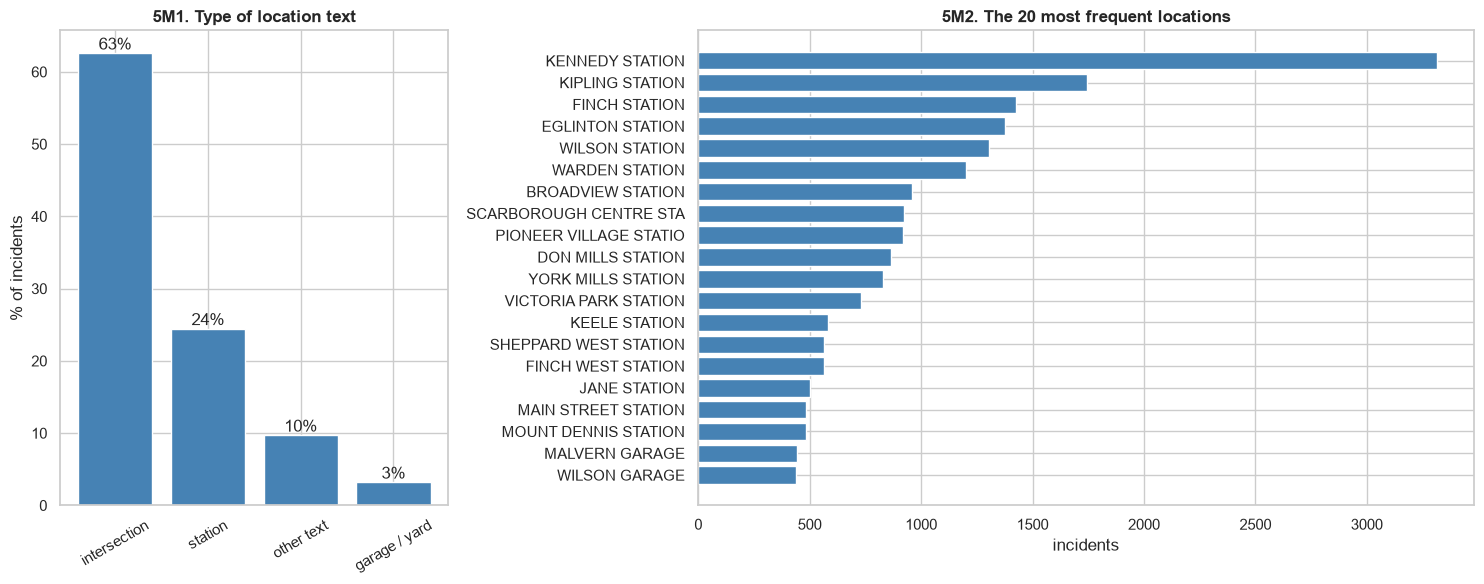

In [68]:
place = incidents["location"].str.upper().str.strip()
kind = np.select(
    [place.str.contains("GARAGE|DIVISION|CARHOUSE|YARD|SHOP", na=False),
     place.str.contains("STATION|STA$| TERMINAL", na=False),
     place.str.contains(r" AND | & |/", na=False)],
    ["garage / yard", "station", "intersection"], default="other text")
kind_share = pd.Series(kind).value_counts(normalize=True) * 100
top_places = place.value_counts().head(20).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 2]})
axes[0].bar(kind_share.index, kind_share.values, color="steelblue")
axes[0].bar_label(axes[0].containers[0], fmt="%.0f%%")
axes[0].set(title="5M1. Type of location text", ylabel="% of incidents")
axes[0].tick_params(axis="x", rotation=30)
axes[1].barh(top_places.index, top_places.values, color="steelblue")
axes[1].set(title="5M2. The 20 most frequent locations", xlabel="incidents")
plt.tight_layout()
print(f"{place.nunique():,} distinct location strings; longest text {place.str.len().max()} characters (the field is cut at 22)")

**How to read it:** the left chart sorts the free-text `location` into types. The right chart lists the 20 most frequent texts.

**What stands out:**
- The field is messy: **17,018 different texts**, cut at 22 characters.
- **Intersections and street names are the most common text (about 63%)**, followed by **stations (25%)**, other text (10%) and garages or yards (3%).
- Each intersection is a different text, so the most frequent single places are stations, mostly at the ends of subway lines where buses start and finish: **Kennedy Station (3,315)**, Kipling (1,742), Finch (1,426), Eglinton (1,375), Wilson (1,303) and Warden (1,200).

**Why it matters:** `location` is useful for terminals, but too messy to turn into coordinates for most incidents. We can use it at stations only (next chart).

### 5N. Map: incidents at subway stations
Where the `location` text is a subway station name, we can place it on the map. Bubble size = number of incidents.

23,792 incidents (22.2%) matched to 76 stations


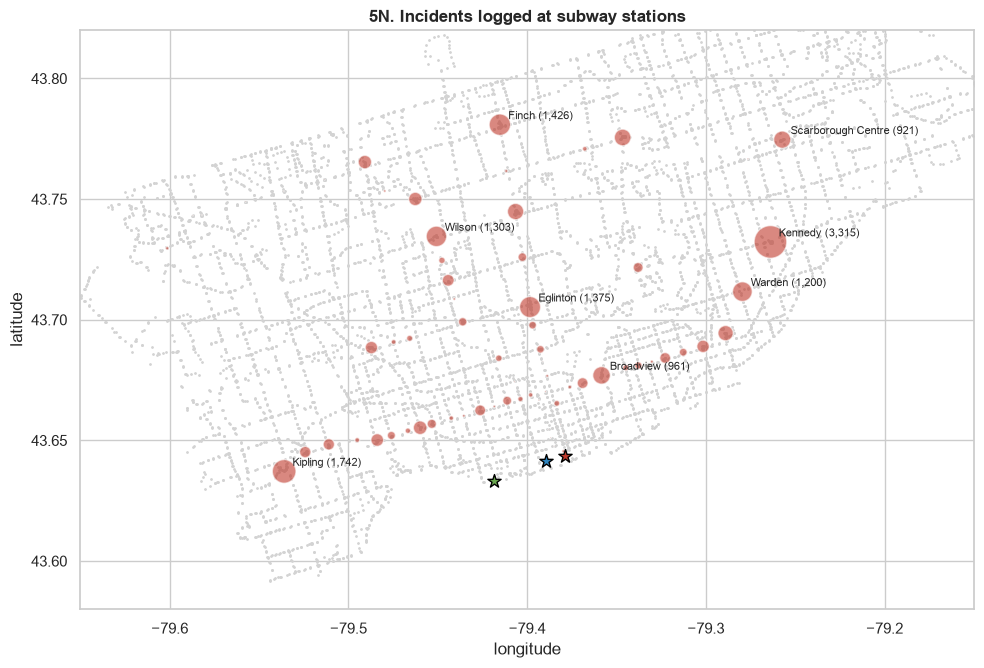

In [69]:
stations = pd.read_csv("../data/raw/Merged GTFS - TTC Routes and Schedules/stops.txt", dtype=str, usecols=["stop_name", "stop_lat", "stop_lon", "location_type"])
stations = stations[(stations["location_type"] == "1") & stations["stop_lat"].notna()].copy()
stations["key"] = stations["stop_name"].str.upper().str.replace(r"\s+", " ", regex=True).str.replace(" STATION", "", regex=False)
stations = stations.drop_duplicates("key").set_index("key")[["stop_lat", "stop_lon"]].astype(float)

place_key = place.str.replace(r" STA(TION)?$", "", regex=True)
station_counts = place_key[place.str.contains("STA", na=False)].value_counts()
station_counts = station_counts[station_counts.index.isin(stations.index)]
station_xy = stations.loc[station_counts.index].assign(incidents=station_counts.values)
print(f"{station_counts.sum():,} incidents ({station_counts.sum() / len(incidents):.1%}) matched to {len(station_counts)} stations")

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(gtfs_stops["stop_lon"], gtfs_stops["stop_lat"], s=1, color="lightgray")
ax.scatter(station_xy["stop_lon"], station_xy["stop_lat"], s=station_xy["incidents"] / 6, color="#c0392b", alpha=0.6, edgecolor="white")
for name, row in station_xy.nlargest(8, "incidents").iterrows():
    ax.annotate(f"{name.title()} ({int(row['incidents']):,})", (row["stop_lon"], row["stop_lat"]), xytext=(6, 4), textcoords="offset points", fontsize=8)
for name, (lat, lon) in VENUES_XY.items():
    ax.scatter(lon, lat, s=100, marker="*", color=venue_colors[name], edgecolor="black", zorder=5)
ax.set(title="5N. Incidents logged at subway stations", xlabel="longitude", ylabel="latitude", aspect=1.35)
ax.set_xlim(-79.65, -79.15)
ax.set_ylim(43.58, 43.82)
plt.tight_layout()

**How to read it:** each red bubble is a subway station where incidents were logged. A bigger bubble means more incidents. Stars are the venues.

**What stands out:** **22% of incidents (23,792) can be placed at 76 stations.** The biggest bubbles are at the **ends of the lines**: Kennedy (3,315), Kipling (1,742) and Finch (1,426). Stations near the downtown venues have **very small bubbles**.

**Why it matters:** station incidents are mostly about buses arriving and leaving terminals, far away from the venues. Station incidents are **not** useful for an "event near the venue" question. The venues are not near a major bus terminal.

### 5O. Do incidents on near-venue routes follow the same day-to-day pattern?
Incidents per day on the group of near-venue routes vs all other routes (both as a 7-day average).

Correlation between the two daily series: 0.49 | share of located incidents on near-venue routes: 9.1%


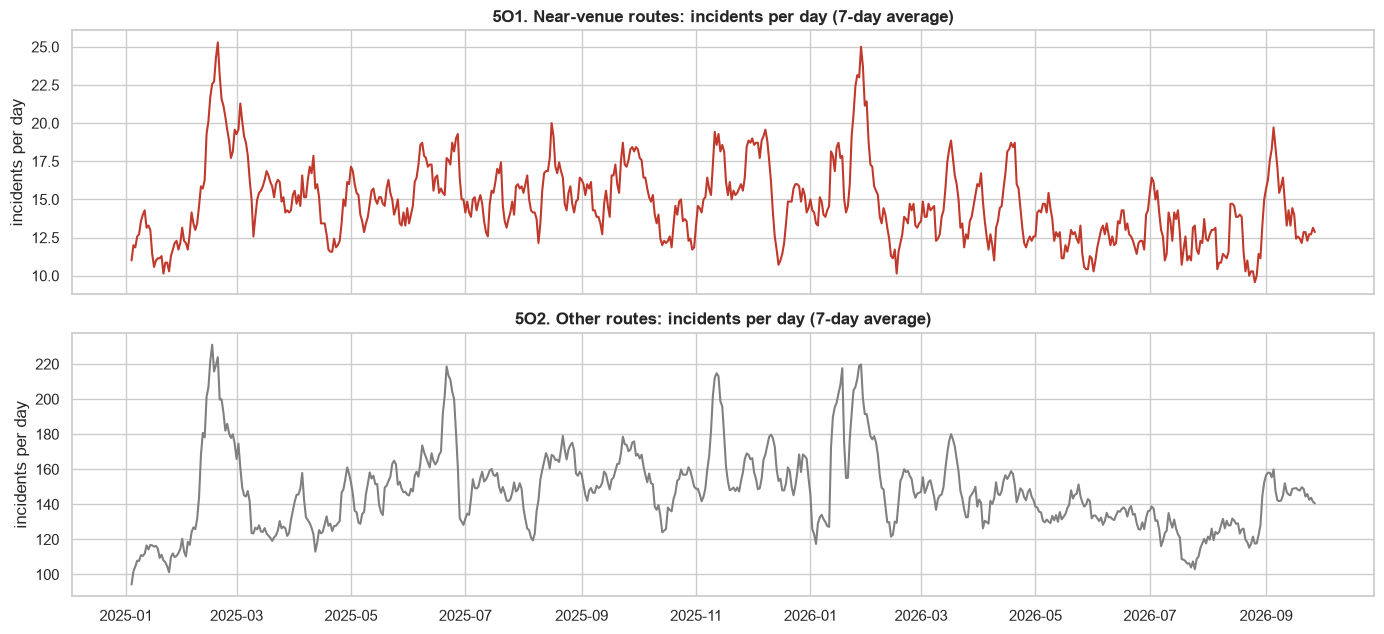

In [70]:
per_day = incidents.dropna(subset=["near_venue"]).groupby(["date", "near_venue"]).size().unstack(fill_value=0)
per_day = per_day.reindex(daily["date"], fill_value=0)
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
axes[0].plot(per_day.index, per_day[True].rolling(7, center=True).mean(), color="#c0392b")
axes[0].set(title="5O1. Near-venue routes: incidents per day (7-day average)", ylabel="incidents per day")
axes[1].plot(per_day.index, per_day[False].rolling(7, center=True).mean(), color="gray")
axes[1].set(title="5O2. Other routes: incidents per day (7-day average)", ylabel="incidents per day")
plt.tight_layout()
print(f"Correlation between the two daily series: {per_day[True].corr(per_day[False]):.2f} | share of located incidents on near-venue routes: {per_day[True].sum() / per_day.sum().sum():.1%}")

**How to read it:** the top line shows incidents per day on near-venue routes. The bottom line shows all the other routes. Both are smoothed over 7 days.

**What stands out:** the two lines look alike in shape but are not tightly linked (correlation 0.49). Near-venue routes are only **9% of located incidents**, about 15 incidents a day. The line is **much noisier** because it is a small group.

**Why it matters:** with only about 15 incidents a day on near-venue routes, an event effect would need to be large to stand out day by day. Hourly counts (about 0.6 per hour) will be even more sparse. We may need to combine all near-venue routes, or look at longer windows.

### Step 5 takeaways
- Incidents are **spread across the network**: it takes 37 of 251 routes to reach half of all incidents. The busiest are 52, 32, 102, 29 and 7.
- We **cannot judge one route against another** (no data on buses or trips; the number of stops is a weak stand-in). Compare a route with **its own normal level**.
- **Routes change over time**: route 32 and route 36 lost most of their incidents in 2026 (likely because of new light-rail lines). Use baselines from the same period.
- **21 routes are within 1 km of a venue** (33 within 3 km). They hold 9% of located incidents. A handful of them dominate: 29, 63, 929, 97, 75 and 320.
- Near-venue routes do **not** have more incidents overall, but they have **more diversions** (about 10% vs 7%), and **night routes** are over-represented (11.5% vs 2%). Night hours must be separated in notebook 03.
- "Near a venue" is a **route-level** label: an incident can be many kilometres from the venue. Station text is useful only for terminals far from the venues.
- About **15 incidents a day** fall on near-venue routes, so effects will be hard to see at the hourly level.

*(Numbers in the notes come from the data as run on this version.)*

## Step 6. Weather and holidays

Weather is the main alternative explanation in this project: heavy snow or rain produce many incidents and diversions on their own,
and events are seasonal (baseball in summer, hockey in winter). If we ignore weather, an event effect could be a weather effect, or be hidden by one.

Weather comes from **one station (Toronto Pearson airport), one value per day**, so we cannot see weather by hour. Variables:
`temp_mean_c` (mean temperature), `rain_mm`, `snow_cm`, `precip_mm` (total precipitation) and `snow_3d_cm` (snow in the last 3 days; snow keeps affecting roads after it falls).

To separate weather from the weekday pattern we also use `vs_normal` = incidents that day divided by the average for the same weekday.
**1.0 = a normal day for that weekday**, 1.2 = 20% more than normal.

In [71]:
weather_cols = ["temp_mean_c", "rain_mm", "snow_cm", "precip_mm", "snow_3d_cm"]
daily["vs_normal"] = daily["n_incidents"] / daily.groupby("weekday")["n_incidents"].transform("mean")

print(f"Days with any precipitation: {(daily['precip_mm'] > 0).sum()} of {len(daily)} | any snow: {(daily['snow_cm'] > 0).sum()} | "
      f"snow of 5+ cm: {(daily['snow_cm'] >= 5).sum()} | rain of 10+ mm: {(daily['rain_mm'] >= 10).sum()} | below -10 C: {(daily['temp_mean_c'] < -10).sum()} | above 25 C: {(daily['temp_mean_c'] > 25).sum()}")
daily[weather_cols].describe().round(1)

Days with any precipitation: 240 of 638 | any snow: 90 | snow of 5+ cm: 17 | rain of 10+ mm: 41 | below -10 C: 26 | above 25 C: 32


,temp_mean_c,rain_mm,snow_cm,precip_mm,snow_3d_cm
count,638.0,638.0,638.0,638.0,638.0
mean,9.8,2.0,0.5,2.3,1.4
std,11.3,6.0,2.5,6.2,4.8
min,-16.9,0.0,0.0,0.0,0.0
25%,0.3,0.0,0.0,0.0,0.0
50%,10.8,0.0,0.0,0.0,0.0
75%,20.0,0.3,0.0,1.2,0.2
max,30.2,48.4,46.2,48.4,47.2


**In plain words:** the table gives the typical and extreme values of each weather variable over the 638 days.

**What stands out:**
- Mean temperature is 9.8 C on average, from **-16.9 C to 30.2 C**.
- **Most days are dry: 398 of 638 (62%).** Snow fell on 90 days (14%), but only **17 days had 5 cm or more and 8 had 10 cm or more**.
- Heavy rain is also rare: 41 days with 10 mm or more, 17 with 20 mm or more.
- Extreme temperatures are not frequent either: 26 days below -10 C and 32 days above 25 C.

**Why it matters:** the "bad weather" days are a small group (a few dozen days). Any weather effect we measure rests on a small number of days, so it is fragile, and these days could easily fall on event or non-event days by chance.

### 6A. Weather through the period

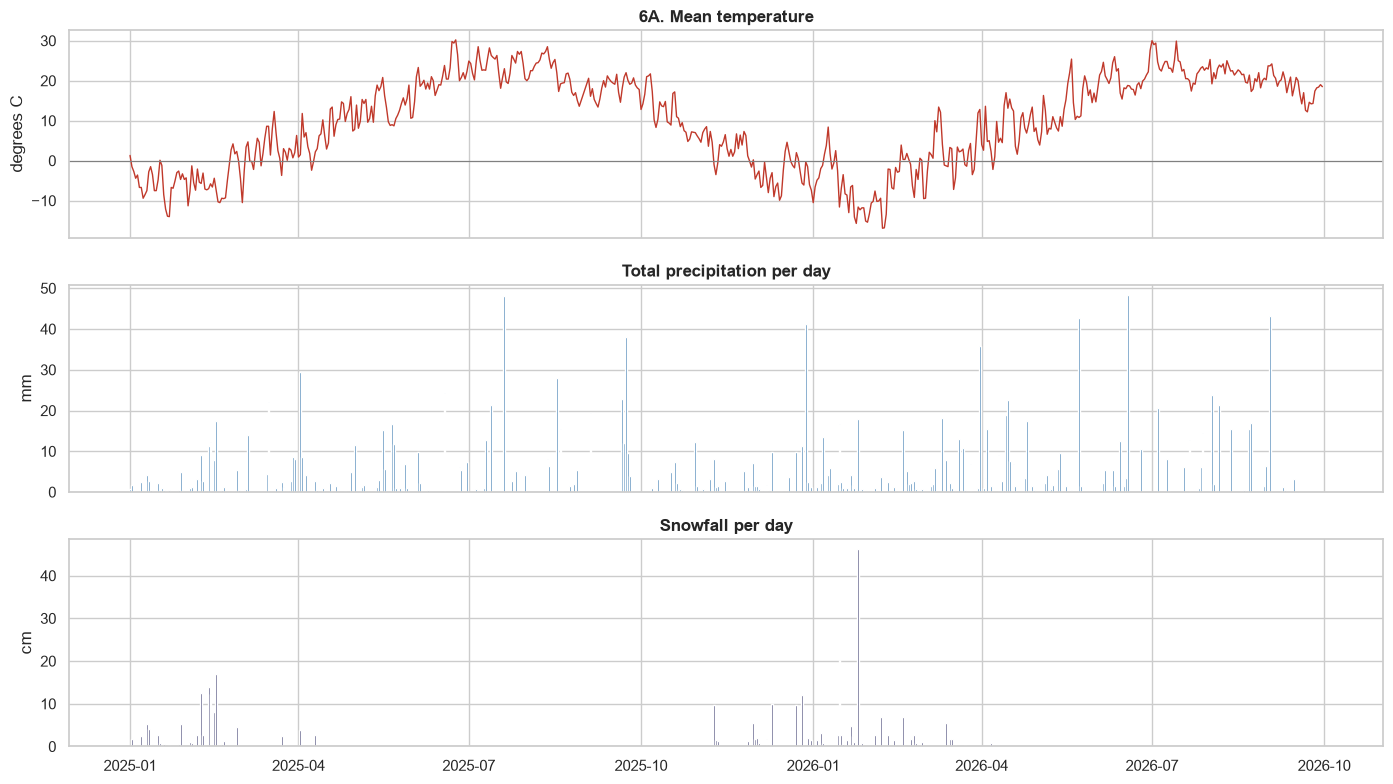

In [72]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
axes[0].plot(daily["date"], daily["temp_mean_c"], color="#c0392b", lw=1)
axes[0].axhline(0, color="gray", lw=0.8)
axes[0].set(title="6A. Mean temperature", ylabel="degrees C")
axes[1].bar(daily["date"], daily["precip_mm"], color="steelblue", width=1)
axes[1].set(title="Total precipitation per day", ylabel="mm")
axes[2].bar(daily["date"], daily["snow_cm"], color="#4c4c7a", width=1)
axes[2].set(title="Snowfall per day", ylabel="cm")
plt.tight_layout()

**How to read it:** three stacked charts with the same time axis: temperature (top), precipitation (middle) and snow (bottom).

**What stands out:**
- A clear seasonal swing: below zero from December to early March, and above 20 C in summer.
- Snow comes in a few **bursts**, mainly in February 2025 and in January and February 2026. The biggest snowfall is **46 cm on 2026-01-25**. The most precipitation is 48 mm on 2026-06-18.
- Rain is spread through the year as many small bars with a few big ones.

**Why it matters:** snow and cold arrive in the same months as hockey and basketball (winter) and are absent in baseball season (summer). That is why season and weather are tangled up with event type.

### 6B. How often is the weather bad?
Most days are mild and dry, so the heavy weather days are few.

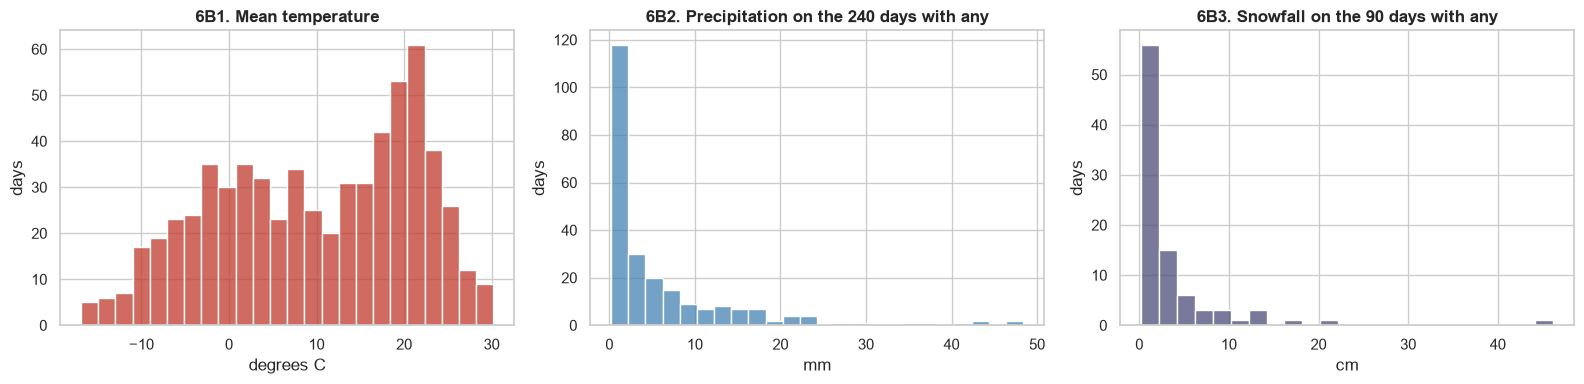

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(daily["temp_mean_c"], binwidth=2, color="#c0392b", ax=axes[0])
axes[0].set(title="6B1. Mean temperature", xlabel="degrees C", ylabel="days")
sns.histplot(daily.loc[daily["precip_mm"] > 0, "precip_mm"], binwidth=2, color="steelblue", ax=axes[1])
axes[1].set(title=f"6B2. Precipitation on the {(daily['precip_mm'] > 0).sum()} days with any", xlabel="mm", ylabel="days")
sns.histplot(daily.loc[daily["snow_cm"] > 0, "snow_cm"], binwidth=2, color="#4c4c7a", ax=axes[2])
axes[2].set(title=f"6B3. Snowfall on the {(daily['snow_cm'] > 0).sum()} days with any", xlabel="cm", ylabel="days")
plt.tight_layout()

**How to read it:** how many days fall into each value range. The middle and right charts only include days that had any precipitation or snow.

**What stands out:** temperature is spread over a wide range, from about -17 C to 30 C. Precipitation and snow are **crowded at the left**: most days with rain or snow have only a little, and days over 20 mm or 10 cm are rare.

**Why it matters:** because the extreme days are so few, weather effects are best looked at in groups (e.g. "10+ mm", "5+ cm"), not as a smooth line.

### 6C. Temperature
Left: average incidents per day in each temperature band. Right: the same, compared with a normal day for that weekday.

,days,incidents,vs_normal
temp_mean_c,,,
< -10,26,201.35,1.22
-10 to -5,53,182.42,1.06
-5 to 0,75,155.32,0.95
0 to 5,86,172.69,1.01
5 to 10,67,164.21,0.98
10 to 15,70,164.94,0.98
15 to 20,108,167.01,0.99
20 to 25,121,157.61,0.94
> 25,32,187.19,1.13


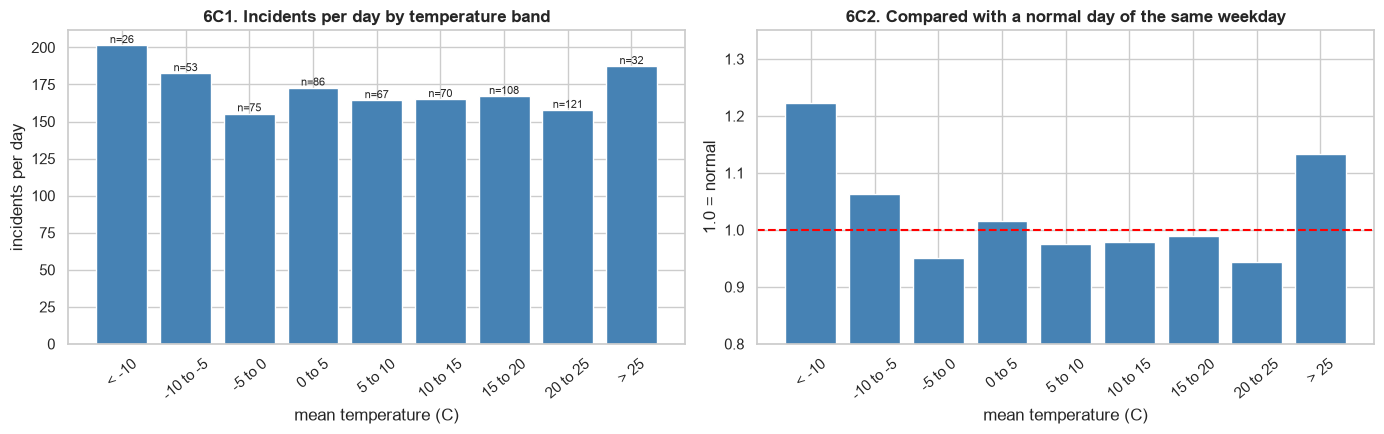

In [74]:
temp_band = pd.cut(daily["temp_mean_c"], [-40, -10, -5, 0, 5, 10, 15, 20, 25, 40],
                   labels=["< -10", "-10 to -5", "-5 to 0", "0 to 5", "5 to 10", "10 to 15", "15 to 20", "20 to 25", "> 25"])
by_temp = daily.groupby(temp_band, observed=True).agg(days=("date", "size"), incidents=("n_incidents", "mean"), vs_normal=("vs_normal", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bars = axes[0].bar(by_temp.index.astype(str), by_temp["incidents"], color="steelblue")
axes[0].bar_label(bars, labels=[f"n={d}" for d in by_temp["days"]], fontsize=8)
axes[0].set(title="6C1. Incidents per day by temperature band", xlabel="mean temperature (C)", ylabel="incidents per day")
bars = axes[1].bar(by_temp.index.astype(str), by_temp["vs_normal"], color="steelblue")
axes[1].axhline(1, color="red", ls="--")
axes[1].set(title="6C2. Compared with a normal day of the same weekday", xlabel="mean temperature (C)", ylabel="1.0 = normal", ylim=(0.8, 1.35))
for ax in axes:
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
by_temp.round(2)

**How to read it:** left: the average incidents per day for each temperature band (`n` = number of days). Right: the same, but compared with a normal day of the same weekday (1.0 = normal, red line).

**What stands out:** a **U shape**. Mild weather is close to normal (0.94 to 1.01). The extremes are higher: **below -10 C is 22% above normal (201 incidents a day, 26 days)** and **above 25 C is 13% above normal (187 a day, 32 days)**. The quietest bands are -5 to 0 C and 20 to 25 C.

**Why it matters:** both severe cold and heat go with more incidents (cold: equipment problems and snow; heat: air conditioning and traffic are possible explanations, which we cannot confirm). A straight line through temperature would miss this, so temperature should be handled in bands.

### 6D. Precipitation
Boxes show the spread of days in each class. `n` = number of days.

,days,incidents,vs_normal,diversions,delay_minutes
precip_class,,,,,
dry,398,162.35,0.97,12.13,3189.73
0-2 mm,109,170.11,1.01,11.62,3273.10
2-10 mm,83,173.83,1.02,12.00,3360.95
10-20 mm,31,207.77,1.23,14.48,4298.58
> 20 mm,17,177.71,1.14,13.82,3866.94


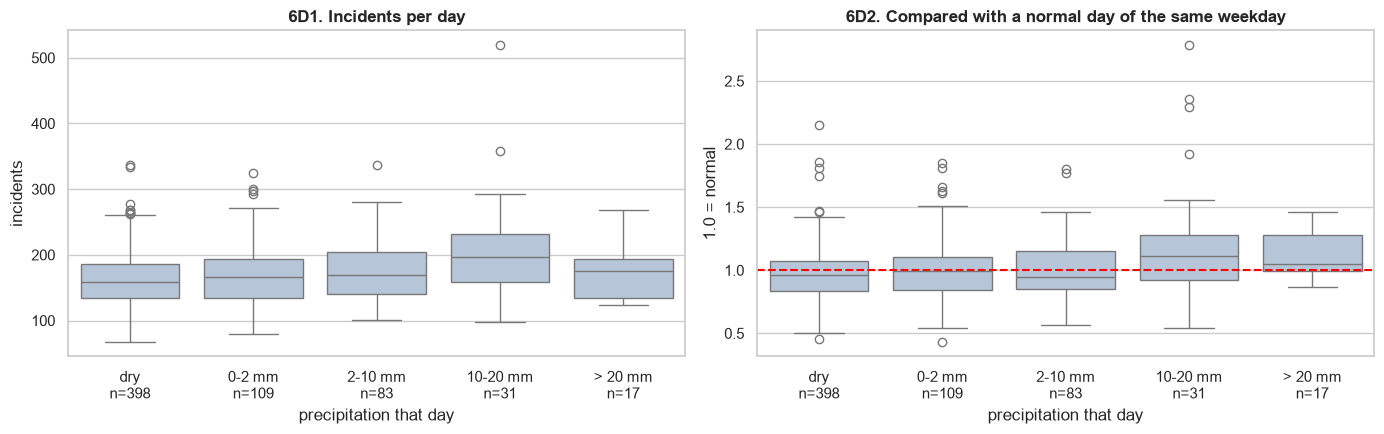

In [75]:
daily["precip_class"] = pd.cut(daily["precip_mm"], [-0.1, 0, 2, 10, 20, 200], labels=["dry", "0-2 mm", "2-10 mm", "10-20 mm", "> 20 mm"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=daily, x="precip_class", y="n_incidents", color="lightsteelblue", ax=axes[0])
axes[0].set(title="6D1. Incidents per day", xlabel="precipitation that day", ylabel="incidents")
sns.boxplot(data=daily, x="precip_class", y="vs_normal", color="lightsteelblue", ax=axes[1])
axes[1].axhline(1, color="red", ls="--")
axes[1].set(title="6D2. Compared with a normal day of the same weekday", xlabel="precipitation that day", ylabel="1.0 = normal")
counts = daily["precip_class"].value_counts()
for ax in axes:
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels([f"{c}\nn={counts[c]}" for c in counts.index.categories])
plt.tight_layout()
daily.groupby("precip_class", observed=True).agg(days=("date", "size"), incidents=("n_incidents", "mean"), vs_normal=("vs_normal", "mean"),
                                                 diversions=("n_diversion", "mean"), delay_minutes=("delay_min_total", "mean")).round(2)

**How to read it:** each box shows the middle half of days in that precipitation class. Left: incidents. Right: compared with a normal day of the same weekday.

**What stands out:**
- Dry days, light rain (0 to 2 mm) and moderate rain (2 to 10 mm) look the same (normal, 0.97 to 1.02).
- **10 to 20 mm: 208 incidents a day, 23% above normal** (31 days), with more diversions (14.5 vs 12.1 a day on dry days) and about 35% more delay minutes (4,299 vs 3,190).
- **Over 20 mm: only 14% above normal** (17 days), less than the class below it.
- The boxes are wide: many heavy-rain days are normal.

**Why it matters:** rain has a smaller and less regular effect than snow. Only heavier rain moves the numbers, and a few days drive that.

### 6E. Snow
Left: snow that fell that day. Right: snow that fell in the last 3 days (includes today).

,days,incidents,vs_normal,diversions,delay_minutes
snow_class,,,,,
none,548,164.76,0.98,12.14,3236.84
0-2 cm,56,172.64,1.05,11.68,3257.75
2-5 cm,17,182.94,1.04,11.65,3409.59
5-10 cm,10,193.80,1.14,14.20,4261.10
> 10 cm,7,292.00,1.81,18.14,6776.57


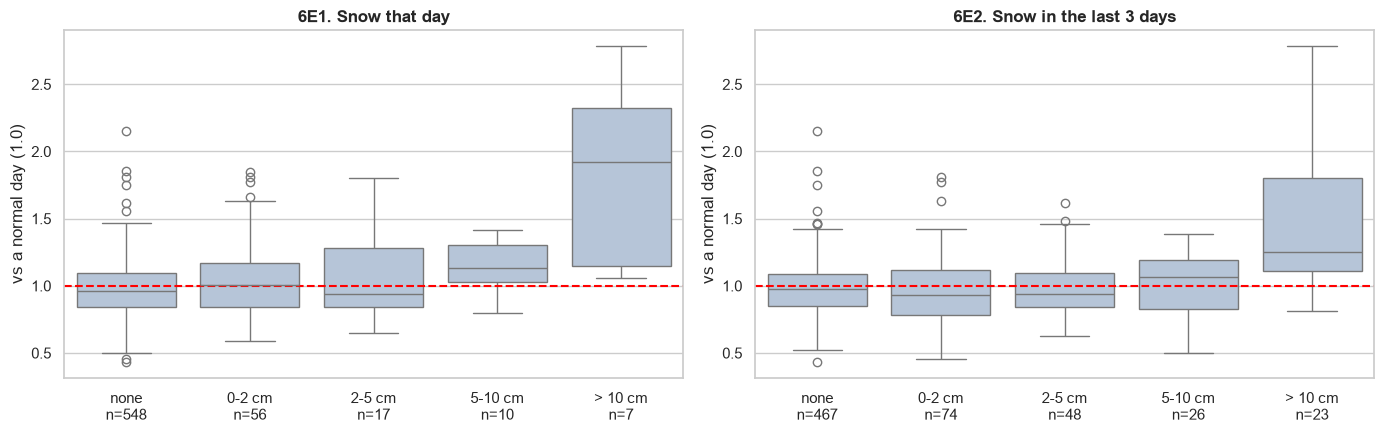

In [76]:
snow_bins, snow_labels = [-0.1, 0, 2, 5, 10, 100], ["none", "0-2 cm", "2-5 cm", "5-10 cm", "> 10 cm"]
daily["snow_class"] = pd.cut(daily["snow_cm"], snow_bins, labels=snow_labels)
daily["snow3_class"] = pd.cut(daily["snow_3d_cm"], snow_bins, labels=snow_labels)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, title in zip(axes, ["snow_class", "snow3_class"], ["6E1. Snow that day", "6E2. Snow in the last 3 days"]):
    sns.boxplot(data=daily, x=col, y="vs_normal", color="lightsteelblue", ax=ax)
    counts = daily[col].value_counts()
    ax.axhline(1, color="red", ls="--")
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels([f"{c}\nn={counts[c]}" for c in counts.index.categories])
    ax.set(title=title, xlabel="", ylabel="vs a normal day (1.0)")
plt.tight_layout()
daily.groupby("snow_class", observed=True).agg(days=("date", "size"), incidents=("n_incidents", "mean"), vs_normal=("vs_normal", "mean"),
                                               diversions=("n_diversion", "mean"), delay_minutes=("delay_min_total", "mean")).round(2)

**How to read it:** same style as 6D, for snow that fell that day (left) and in the last 3 days (right). The red line is a normal day.

**What stands out:** snow is the strongest weather effect so far:
- Light snow (under 5 cm) is close to normal (1.04 to 1.05).
- **5 to 10 cm: 14% above normal (10 days).**
- **More than 10 cm: 81% above normal (292 incidents a day vs 165 on days with no snow, 7 days)**, with 18 diversions a day (vs 12) and **about double the delay minutes (6,777 vs 3,237)**.
- Including the previous days, **more than 10 cm of snow in 3 days: 48% above normal (23 days).**

**Why it matters:** heavy snow can nearly double incidents. If one of these days has an event, the event would look very disruptive, so snowy days have to be controlled for or removed.

### 6F. Day by day: each outcome against each weather variable
One dot per day. Rows: incidents and diversions. Columns: precipitation and snow in the last 3 days.

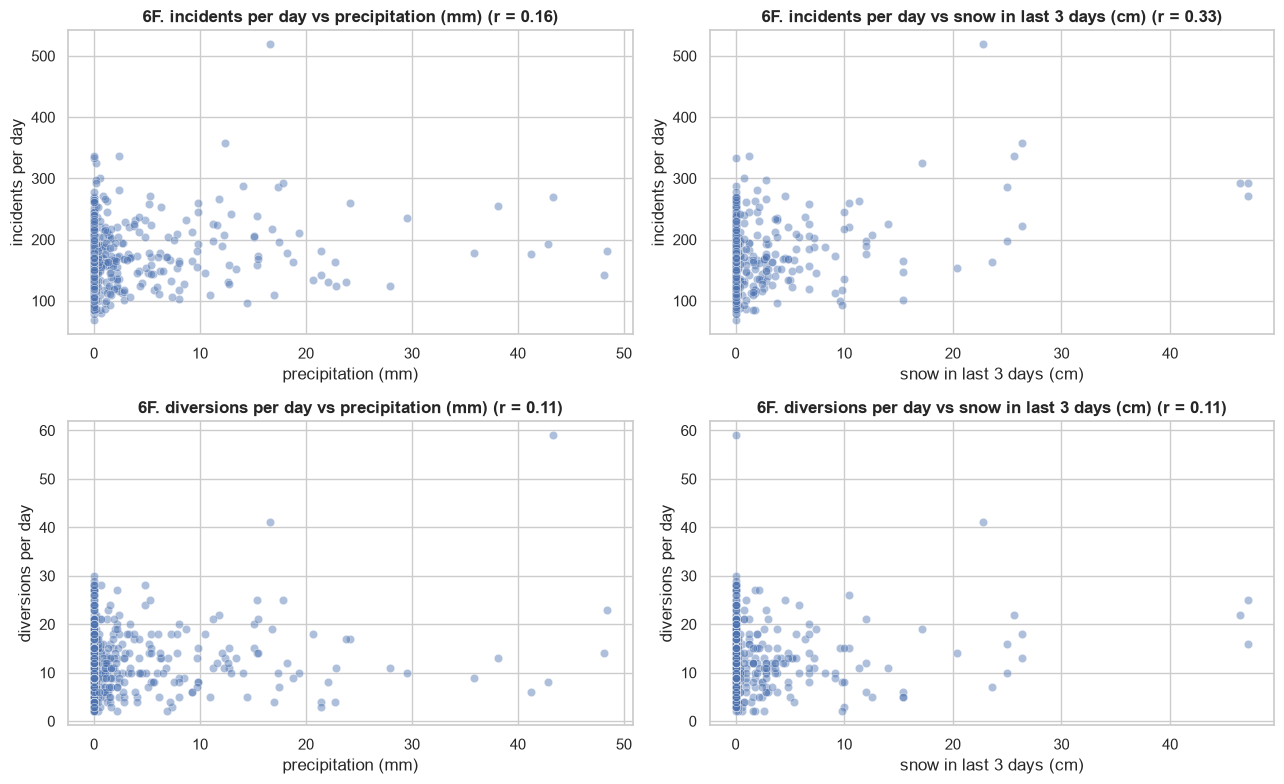

In [77]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, (outcome, label) in enumerate([("n_incidents", "incidents per day"), ("n_diversion", "diversions per day")]):
    for col, (weather, wlabel) in enumerate([("precip_mm", "precipitation (mm)"), ("snow_3d_cm", "snow in last 3 days (cm)")]):
        ax = axes[row, col]
        sns.scatterplot(data=daily, x=weather, y=outcome, alpha=0.45, ax=ax)
        ax.set(title=f"6F. {label} vs {wlabel} (r = {daily[outcome].corr(daily[weather]):.2f})", xlabel=wlabel, ylabel=label)
plt.tight_layout()

**How to read it:** each dot is one day. Top row: incidents; bottom row: diversions. Left: precipitation; right: snow in the last 3 days. The *r* value is the correlation.

**What stands out:**
- The links are weak overall (*r* = 0.11 to 0.33) because most days sit at "no weather, normal incidents".
- **Snow in the last 3 days has the clearest link with incidents (r = 0.33)**: the days with the most snow lie at the top right.
- For **precipitation, heavy rain days are not always busy**: most days over 20 mm have normal incident counts. The exception is **2026-09-02** (43 mm, **59 diversions**, the most of any day).

**Why it matters:** weather matters mostly on the rare extreme days, and not in a steady way. This also shows that one outlier day (2026-09-02) can create a lot of the apparent link between rain and diversions.

### 6G. How strongly is each weather variable linked to the outcomes?
Correlation: +1 = move together, 0 = unrelated. Weekday effect removed in the last column (`vs_normal`).

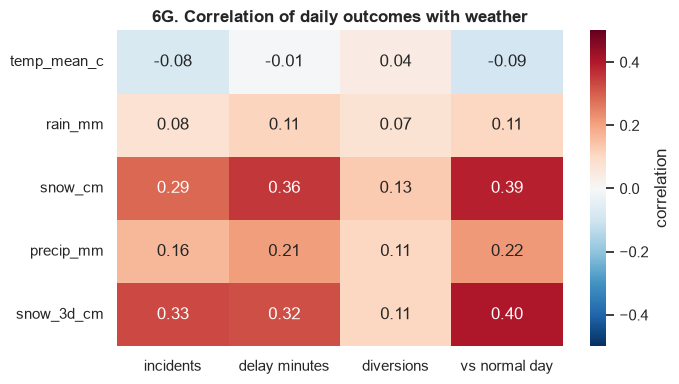

In [78]:
outcomes = {"n_incidents": "incidents", "delay_min_total": "delay minutes", "n_diversion": "diversions", "vs_normal": "vs normal day"}
corr = pd.DataFrame({label: [daily[outcome].corr(daily[w]) for w in weather_cols] for outcome, label in outcomes.items()}, index=weather_cols)
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5, ax=ax, cbar_kws={"label": "correlation"})
ax.set(title="6G. Correlation of daily outcomes with weather")
plt.tight_layout()

**How to read it:** each square is the correlation between a weather variable (rows) and an outcome (columns). Red = both go up together, blue = one goes up while the other goes down. The last column removes the weekday pattern.

**What stands out:**
- **Snow variables are the strongest**: snowfall and snow in the last 3 days have correlations of 0.39 to 0.40 with a day's incidents compared with normal.
- Precipitation is weaker (0.22) and rain alone is weak (0.11). Temperature is slightly negative (-0.09): colder is a bit busier, but the effect is mostly in the extremes (6C).
- Diversions are only weakly linked to any weather variable (0.04 to 0.13).

**Why it matters:** snow should be the main weather control. Diversions are *not* well explained by daily weather, which suggests they have other causes (roadworks, events, closures) beyond the daily weather we have.

### 6H. The ten busiest days and their weather
Bars are incidents. Labels show what the weather was.

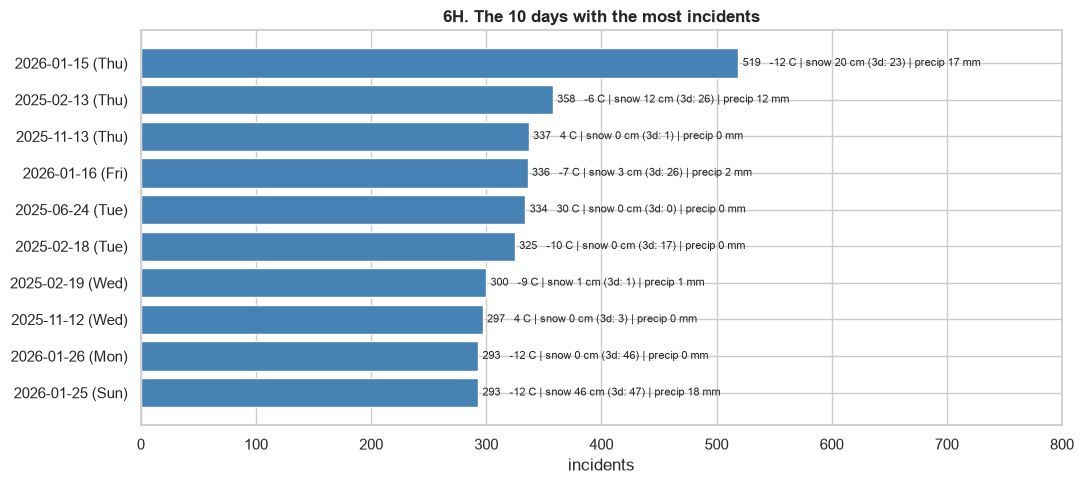

In [79]:
busiest = daily.nlargest(10, "n_incidents").sort_values("n_incidents")
labels = [f"{d:%Y-%m-%d (%a)}" for d in busiest["date"]]
notes = [f"{t:.0f} C | snow {s:.0f} cm (3d: {s3:.0f}) | precip {p:.0f} mm" for t, s, s3, p in
         zip(busiest["temp_mean_c"], busiest["snow_cm"], busiest["snow_3d_cm"], busiest["precip_mm"])]
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(labels, busiest["n_incidents"], color="steelblue")
ax.bar_label(bars, labels=[f"{n}   {note}" for n, note in zip(busiest["n_incidents"], notes)], fontsize=8, padding=3)
ax.set(title="6H. The 10 days with the most incidents", xlabel="incidents", xlim=(0, 800))
plt.tight_layout()

**How to read it:** the ten busiest days, with temperature, snowfall (and the 3-day total) and precipitation written next to each bar.

**What stands out:**
- **Seven of the ten are snow or deep-cold days**: Jan 15, 2026 (20 cm of snow, -12 C), Feb 13, 2025 (12 cm), Jan 16, 2026, Feb 18 and 19, 2025 (about -10 C), Jan 25 and 26, 2026 (46 cm, -12 C).
- **Three have no snow**: Nov 12 and 13, 2025 (4 C, dry) and June 24, 2025 (30 C).
- Nov 13, 2025 had a Maple Leafs home game, but **the day before, with no event, was nearly as busy** (297 vs 337).

**Why it matters:** most extreme days are weather days, but some are not explained by weather. A busy day that happens to have an event is not proof that the event caused it: Nov 12 shows the same level without one.

### 6I. Holidays and weekends
Public holidays are quiet days. The right chart shows each holiday against a normal day of the same weekday.

,days,incidents,delay_minutes
day_type,,,
ordinary weekday,441,181.0,3498.0
public holiday,15,118.0,2675.0
weekend,182,140.0,2865.0


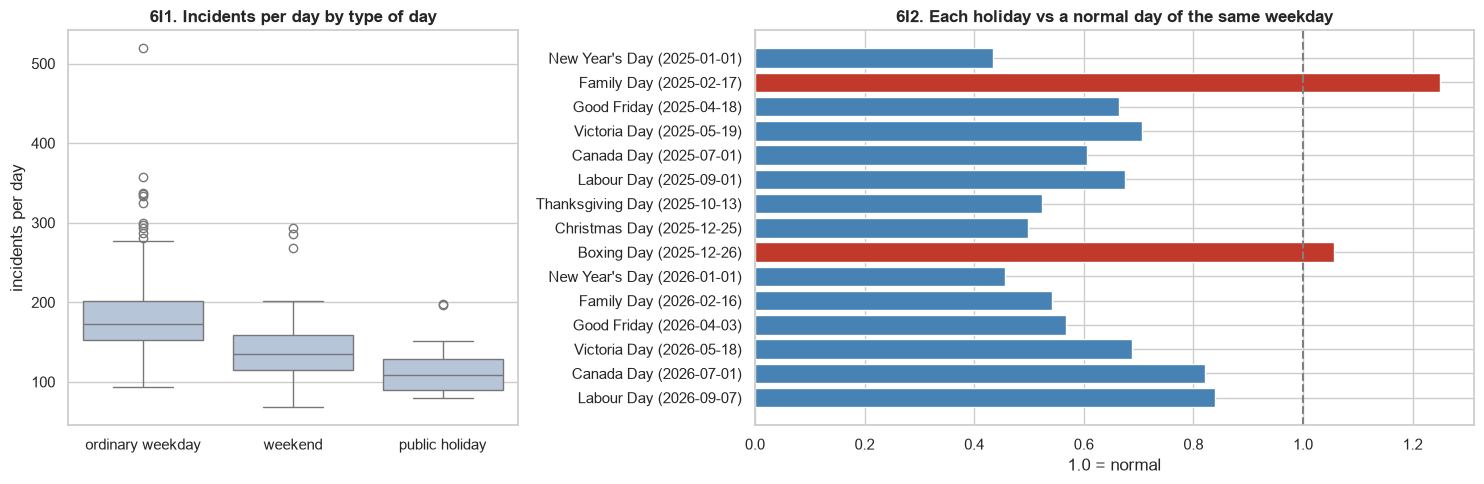

In [80]:
daily["day_type"] = np.select([daily["is_holiday"], daily["is_weekend"]], ["public holiday", "weekend", ][:2], default="ordinary weekday")
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.6]})
sns.boxplot(data=daily, x="day_type", y="n_incidents", order=["ordinary weekday", "weekend", "public holiday"], color="lightsteelblue", ax=axes[0])
axes[0].set(title="6I1. Incidents per day by type of day", xlabel="", ylabel="incidents per day")
hol = daily[daily["is_holiday"]].sort_values("date")
bars = axes[1].barh([f"{h} ({d:%Y-%m-%d})" for h, d in zip(hol["holiday"], hol["date"])][::-1], hol["vs_normal"].to_numpy()[::-1],
                    color=["#c0392b" if v > 1 else "steelblue" for v in hol["vs_normal"].to_numpy()[::-1]])
axes[1].axvline(1, color="gray", ls="--")
axes[1].set(title="6I2. Each holiday vs a normal day of the same weekday", xlabel="1.0 = normal")
plt.tight_layout()
daily.groupby("day_type").agg(days=("date", "size"), incidents=("n_incidents", "mean"), delay_minutes=("delay_min_total", "mean")).round(0)

**How to read it:** left: incidents per day for ordinary weekdays, weekends and public holidays. Right: each holiday compared with a normal day of the same weekday (red = busier than normal).

**What stands out:**
- Ordinary weekdays average **181 incidents**, weekends **140** and holidays **118** (15 days).
- **13 of 15 holidays were quieter than normal, at 43% to 84% of a normal day.** The quietest are New Year's Day (0.43 to 0.46), Christmas (0.50) and Thanksgiving (0.52).
- Two exceptions: **Family Day 2025 (1.25)**, during the cold February 2025 period, and Boxing Day 2025 (1.06).
- The 2026 summer holidays are less quiet than in 2025 (Canada Day 0.82 vs 0.61, Labour Day 0.84 vs 0.68).

**Why it matters:** holidays behave like quiet weekend days. Events on holidays (such as a Canada Day or Labour Day game) should be compared with other holidays or weekends, not ordinary weekdays.

### 6J. Season: temperature and incidents by calendar month

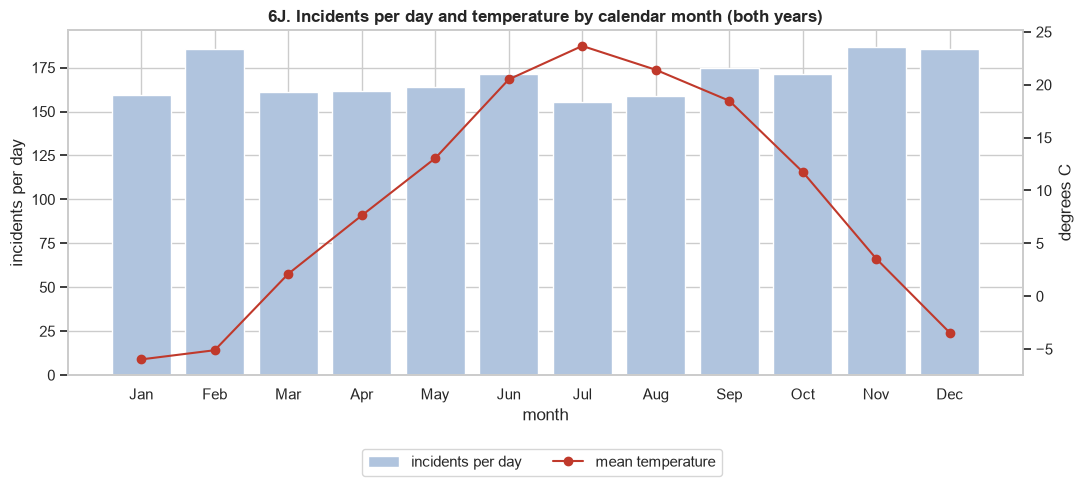

In [81]:
by_month = daily.groupby("month").agg(incidents=("n_incidents", "mean"), temp=("temp_mean_c", "mean"), snow=("snow_cm", "sum"), precip=("precip_mm", "sum"))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(by_month.index, by_month["incidents"], color="lightsteelblue", label="incidents per day")
ax.set(title="6J. Incidents per day and temperature by calendar month (both years)", xlabel="month", ylabel="incidents per day")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax2 = ax.twinx()
ax2.plot(by_month.index, by_month["temp"], color="#c0392b", marker="o", label="mean temperature")
ax2.set(ylabel="degrees C")
ax2.grid(False)
fig.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.0))
plt.tight_layout()

**How to read it:** the bars are incidents per day for each calendar month (2025 and 2026 combined) and the red line is the average temperature.

**What stands out:**
- The busiest months are **November (187), February and December (185 each)**. The quietest are **July (155), August and January (159 each)**.
- The temperature line (-6 C in January to 24 C in July) does not match the incident bars closely: January is the coldest month but one of the quietest, because January 2025 (126 a day) is low (see Step 1).
- The pattern is **not simply cold = busy**: November is busy, but mild.

**Why it matters:** month captures more than temperature (school year, holidays, logging, ridership). That is why month needs to be its own control in addition to weather.

### 6K. How much of the day-to-day variation do the calendar and weather explain?
A first look using the share of variation explained (R squared) by simple linear models of incidents per day. These models are only for orientation;
the proper model, with event variables, is in notebook 03. Years 2025 and 2026 are pooled.

,R2,adj. R2
weekday,0.215,0.207
weekday + month,0.266,0.245
weekday + month + holiday,0.301,0.281
+ weather,0.454,0.435


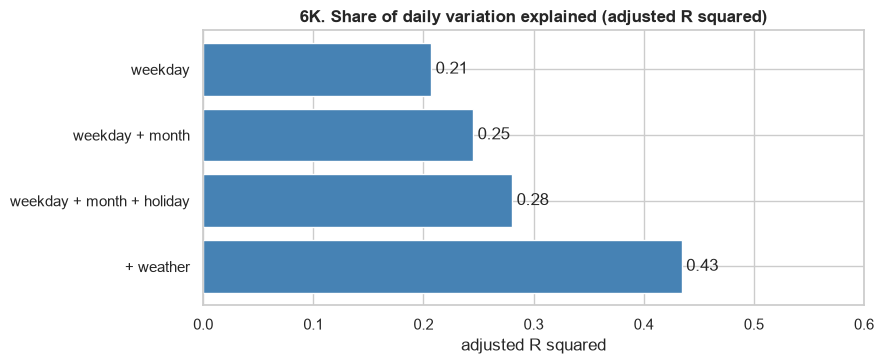

In [82]:
import statsmodels.formula.api as smf

formulas = {
    "weekday": "n_incidents ~ C(weekday)",
    "weekday + month": "n_incidents ~ C(weekday) + C(month)",
    "weekday + month + holiday": "n_incidents ~ C(weekday) + C(month) + is_holiday",
    "+ weather": "n_incidents ~ C(weekday) + C(month) + is_holiday + temp_mean_c + precip_mm + snow_cm + snow_3d_cm",
}
fits = {name: smf.ols(formula, data=daily.assign(is_holiday=daily["is_holiday"].astype(int))).fit() for name, formula in formulas.items()}
r2 = pd.DataFrame({"R2": [f.rsquared for f in fits.values()], "adj. R2": [f.rsquared_adj for f in fits.values()]}, index=list(fits))
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh(r2.index[::-1], r2["adj. R2"].to_numpy()[::-1], color="steelblue")
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set(title="6K. Share of daily variation explained (adjusted R squared)", xlabel="adjusted R squared", xlim=(0, 0.6))
plt.tight_layout()
r2.round(3)

**How to read it:** each bar is a simple model of incidents per day. A longer bar means the factors in the model explain more of the day-to-day ups and downs (adjusted R squared; 0.20 = 20%).

**What stands out:**
- **Weekday alone explains 21%.** Adding month brings it to 25%, and public holidays to 28%.
- **Adding the four weather variables brings it to 44%**, a big jump: weather adds about 15 percentage points, more than month and holiday together (7 points).
- **56% of the variation is still unexplained.**

**Why it matters:** weather has to be in the final model, or we would credit events with effects that weather explains. And there is still a lot left over, so other things (including events) have room to matter.

### 6L. Do event days and non-event days have the same weather?
This is the confounding problem in one picture: if the weather differs, a raw comparison is unfair.

,days,temp,share_snow,share_heavy_rain,share_cold,share_weekend
has_event,,,,,,
no event,297,8.9,18.5,5.1,14.8,22.9
event day,341,10.6,10.3,7.6,10.0,33.4


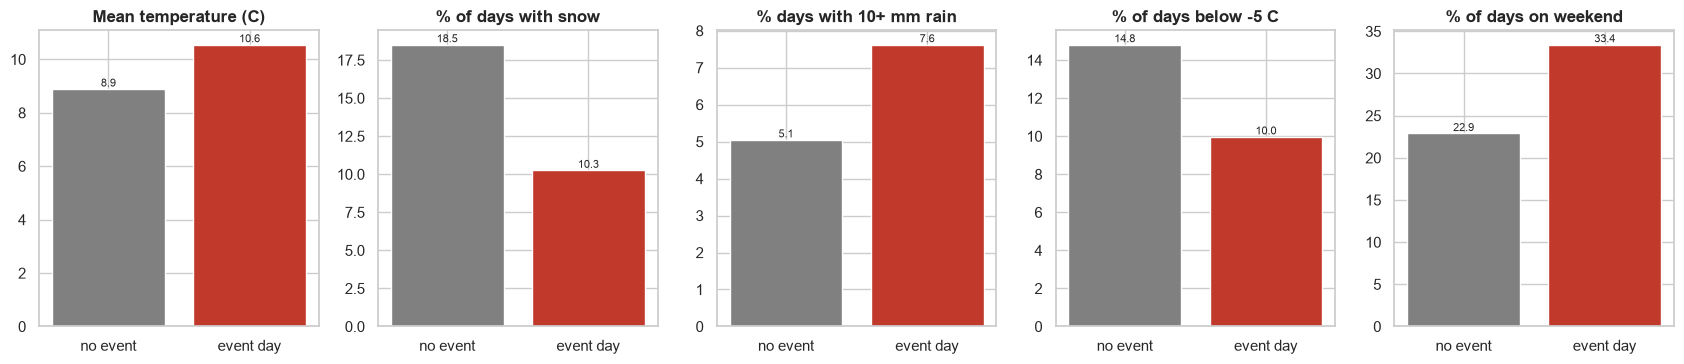

In [83]:
weather_by_event = daily.groupby("has_event").agg(
    days=("date", "size"), temp=("temp_mean_c", "mean"), share_snow=("snow_cm", lambda s: (s > 0).mean() * 100),
    share_heavy_rain=("rain_mm", lambda s: (s >= 10).mean() * 100), share_cold=("temp_mean_c", lambda s: (s < -5).mean() * 100),
    share_weekend=("is_weekend", lambda s: s.mean() * 100)).rename(index={False: "no event", True: "event day"})
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
for ax, (col, title) in zip(axes, [("temp", "Mean temperature (C)"), ("share_snow", "% of days with snow"), ("share_heavy_rain", "% days with 10+ mm rain"),
                                   ("share_cold", "% of days below -5 C"), ("share_weekend", "% of days on weekend")]):
    ax.bar(weather_by_event.index, weather_by_event[col], color=["gray", "#c0392b"])
    ax.bar_label(ax.containers[0], fmt="%.1f", fontsize=8)
    ax.set(title=title)
plt.tight_layout()
weather_by_event.round(1)

**How to read it:** the five small charts compare days with an event (red) and days without (grey) on weather and weekday.

**What stands out:**
- Event days are **milder**: 10.6 C vs 8.9 C on average.
- **Snow falls on 10% of event days but 18% of non-event days.** Days below -5 C are 10% vs 15%.
- Event days are **more often weekends** (33% vs 23%) and have slightly more heavy-rain days (7.6% vs 5.1%).
- Raw average incidents are even **a little lower on event days (165 vs 171)**.

**Why it matters:** this is why the raw comparison cannot be trusted. Event days are *easier* days (milder weather, more weekends), so events look harmless or even helpful when we compare raw averages. The real question needs weekday, month, weather and holidays held equal, which is the job of notebook 03.

### Step 6 takeaways
- **Snow is the strongest weather effect.** Days with more than 10 cm of snow have **81% more incidents** than a normal day of the same weekday (about double the delay minutes). Only 7 days are like that, and 17 days had 5 cm or more.
- **Cold and heat extremes also raise incidents** (below -10 C: +22%; above 25 C: +13%). Ordinary rain barely matters; only heavy rain (10 mm or more) does, and not steadily.
- **Weather explains a lot**: it lifts the explained share of daily incidents from 28% (weekday, month, holiday) to **44%**. 56% is still unexplained.
- **Weather does not explain diversions well** (correlations of 0.04 to 0.13). Their biggest day (2026-09-02, 43 mm) is a single outlier.
- **Holidays are quiet** (118 incidents a day vs 181 on ordinary weekdays). Compare holiday events with holidays.
- **Event days are easier days**: milder, less snow, more weekends. The raw event vs non-event gap (165 vs 171 a day) would make events look harmless. It is **confounded**.
- Not every extreme day is a weather day (Nov 12 and 13, 2025; June 24, 2025). A single busy day with an event is not evidence by itself.

**What notebook 03 must control for:** weekday, month, holidays, snow (today and last 3 days), temperature extremes and heavy rain.

*(Numbers in the notes come from the data as run on this version.)*

## Step 7. The event calendar

`events` has one row per event per day (a multi-day event such as the CNE has one row for each day). It holds Toronto **home games** (Blue Jays, Maple Leafs, Raptors, Toronto FC),
the six FIFA World Cup 2026 matches in Toronto, and hand-collected city events (parades, festivals, the marathon).

**Event window** (from notebook 01): from 2 hours before the start to 2 hours after the end. For sports the end time is not known, so the end is **start + 3 hours**.
Events with no start time (CNE, TIFF, the marathon) count as **event days** but have no hourly window.

This step does not look at incidents yet. It asks what the calendar looks like: what types, when, how many, and how much of the calendar it covers.

In [84]:
events = pd.read_csv(PROCESSED / "events.csv", parse_dates=["date", "start", "end", "window_start", "window_end"])
TYPE_ORDER = ["mlb", "nhl", "nba", "mls", "world_cup", "parade", "festival", "road_race"]
TYPE_NAMES = {"mlb": "MLB (Blue Jays)", "nhl": "NHL (Maple Leafs)", "nba": "NBA (Raptors)", "mls": "MLS (Toronto FC)",
              "world_cup": "World Cup 2026", "parade": "Parade", "festival": "Festival", "road_race": "Road race"}
TYPE_COLORS = dict(zip(TYPE_ORDER, ["#2e86c1", "#1f3a5f", "#c0392b", "#6aa84f", "#f1c232", "#8e7cc3", "#e69138", "#7f7f7f"]))
hourly = pd.read_csv(PROCESSED / "hourly.csv", parse_dates=["datetime", "date"])

by_type = events.groupby("event_type").agg(
    events=("event_id", "nunique"), event_days=("date", "nunique"),
    with_time_window=("window_start", lambda s: s.notna().sum()),
    venues=("venue", "nunique"),
).reindex(TYPE_ORDER)
print(f"{events['event_id'].nunique()} events on {events['date'].nunique()} different days "
      f"({events['date'].nunique() / len(daily):.0%} of the {len(daily)} days) | {hourly['in_event_window'].sum():,} hours inside a window "
      f"({hourly['in_event_window'].mean():.1%} of all hours)")
by_type

358 events on 341 different days (53% of the 638 days) | 2,546 hours inside a window (16.6% of all hours)


,events,event_days,with_time_window,venues
event_type,,,,
mlb,172,172,172,1
nhl,70,70,70,1
nba,68,68,68,1
mls,31,31,31,1
world_cup,6,6,6,1
parade,5,5,5,3
festival,5,60,2,3
road_race,1,2,0,1


**In plain words:** the table counts what is in the calendar. 358 events fall on **341 different days (53% of all 638 days)**, and **2,546 hours (16.6% of all hours) are inside an event window**.

**What stands out:**
- **Baseball dominates**: 172 Blue Jays home games, then 70 Maple Leafs, 68 Raptors and 31 Toronto FC games.
- The **small groups** are tiny: **6 World Cup matches, 5 parades, 5 festivals and 1 road race (the marathon)**.
- Festivals have 60 event-days but only 2 have a start time (so the other 3 have no hourly window). The marathon has none.
- Each sports type uses a single venue.

**Why it matters:** the sports are big enough to analyse separately. The World Cup, parades and the marathon are too few for a separate result. They have to be grouped (for example "major city events") or described as case studies.

### 7A. How many events of each type?

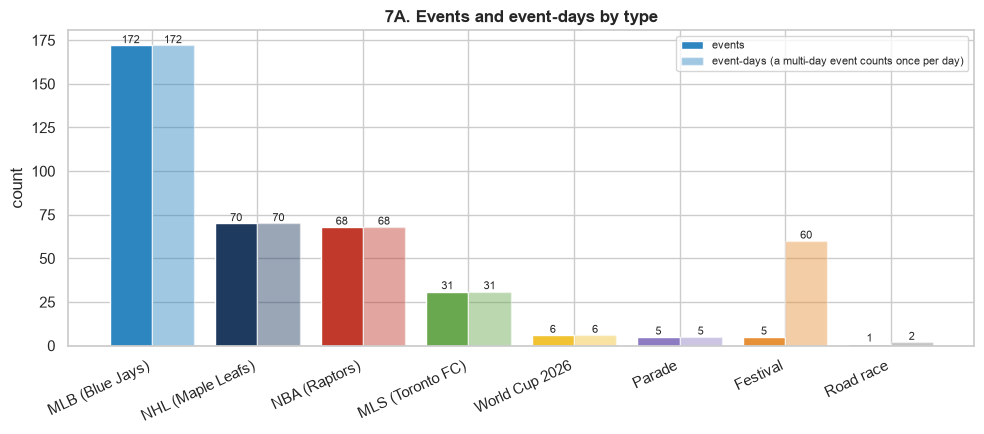

In [85]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(by_type))
ax.bar(x - 0.2, by_type["events"], width=0.4, color=[TYPE_COLORS[t] for t in by_type.index], label="events")
ax.bar(x + 0.2, by_type["event_days"], width=0.4, color=[TYPE_COLORS[t] for t in by_type.index], alpha=0.45, label="event-days (a multi-day event counts once per day)")
ax.set_xticks(x)
ax.set_xticklabels([TYPE_NAMES[t] for t in by_type.index], rotation=25, ha="right")
ax.bar_label(ax.containers[0], fontsize=8)
ax.bar_label(ax.containers[1], fontsize=8)
ax.set(title="7A. Events and event-days by type", ylabel="count")
ax.legend(fontsize=8)
plt.tight_layout()

**How to read it:** dark bars are events, pale bars are event-days (a multi-day event counts once per day).

**What stands out:** the **festival bar is the only one where the two differ a lot** (5 events but 60 event-days, because the CNE and TIFF last two to three weeks). For everything else, an event is one day.

**Why it matters:** the "event-day" view makes festivals look like a major part of the calendar (60 of 341 days), even though only a few events are involved and most of those days have no hourly window. Counting events or event-days changes the picture.

### 7B. Timeline
One dot = one event-day.

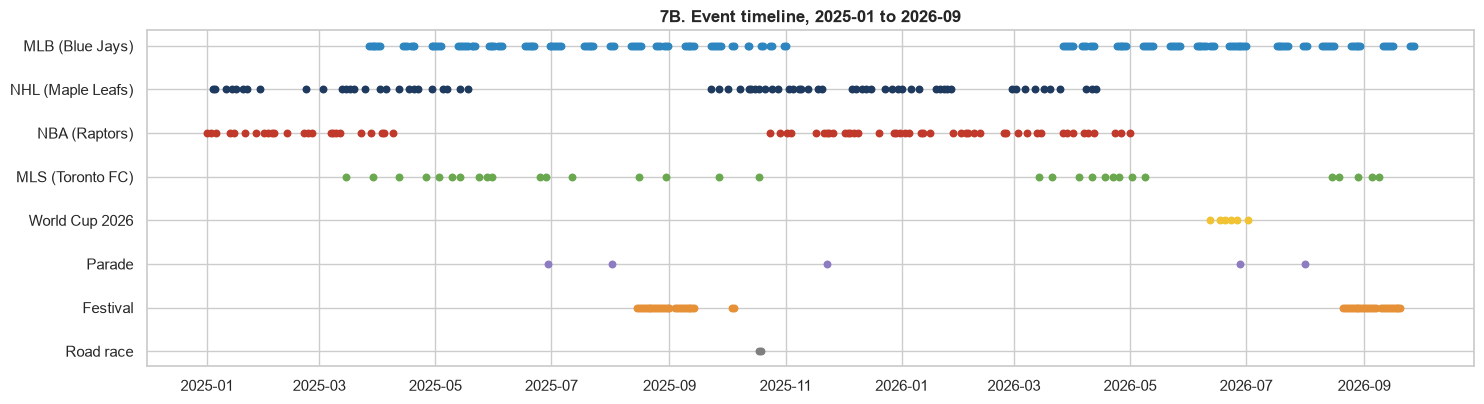

In [86]:
fig, ax = plt.subplots(figsize=(15, 4.2))
for i, t in enumerate(TYPE_ORDER):
    rows = events[events["event_type"] == t]
    ax.scatter(rows["date"], [i] * len(rows), s=22, color=TYPE_COLORS[t])
ax.set_yticks(range(len(TYPE_ORDER)))
ax.set_yticklabels([TYPE_NAMES[t] for t in TYPE_ORDER])
ax.invert_yaxis()
ax.set(title="7B. Event timeline, 2025-01 to 2026-09", xlabel="")
plt.tight_layout()

**How to read it:** each dot is an event-day; each row is an event type.

**What stands out:**
- **Baseball (top row) fills April to October**, with a clear gap in the winter. Late October to early November 2025 includes the Blue Jays' World Series home games.
- **Hockey and basketball (rows 2 and 3) fill October to April**, the opposite season.
- The **World Cup** has 6 dots in June and early July 2026. Parades and festivals are single dots or short runs in summer and autumn.

**Why it matters:** the sports seasons hardly overlap, so sport and season are tangled together. Hockey/basketball compare with winter days, and baseball with summer days.

### 7C. Events per month, by type

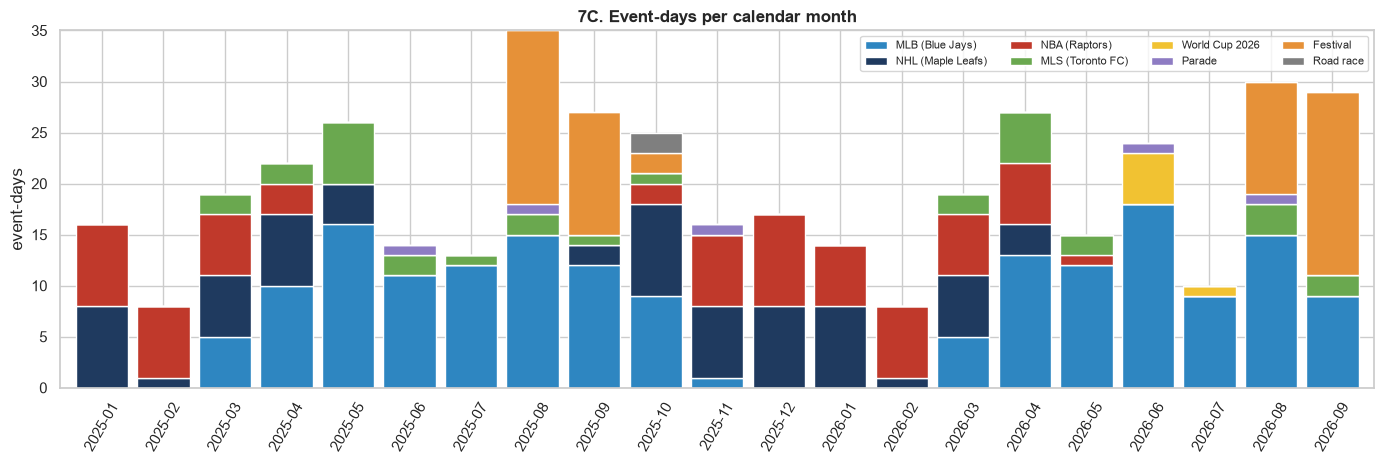

In [87]:
month_type = pd.crosstab(events["date"].dt.to_period("M").astype(str), events["event_type"]).reindex(columns=TYPE_ORDER, fill_value=0)
fig, ax = plt.subplots(figsize=(14, 4.8))
month_type.plot.bar(stacked=True, ax=ax, color=[TYPE_COLORS[t] for t in month_type.columns], width=0.85)
ax.set(title="7C. Event-days per calendar month", xlabel="", ylabel="event-days")
ax.tick_params(axis="x", rotation=60)
ax.legend([TYPE_NAMES[t] for t in month_type.columns], ncol=4, fontsize=8)
plt.tight_layout()

**How to read it:** each bar is a month, stacked by event type.

**What stands out:**
- The busiest months are **August 2025 (35 event-days, mostly the CNE)**, September 2026 (29), and June 2026 (24).
- Winter months are lighter: **February 2025 and 2026 have only 8 event-days**, December 2025 17.
- **July 2026 is the quietest summer month** (10 event-days: 9 Blue Jays games and 1 World Cup match).

**Why it matters:** the number of events varies a lot by month, and the share of hours in a window goes from 9% (February) to 24% (May 2025, April and June 2026). A month with few events gives us less to compare.

### 7D. Which weekdays? Events with a start time, by weekday

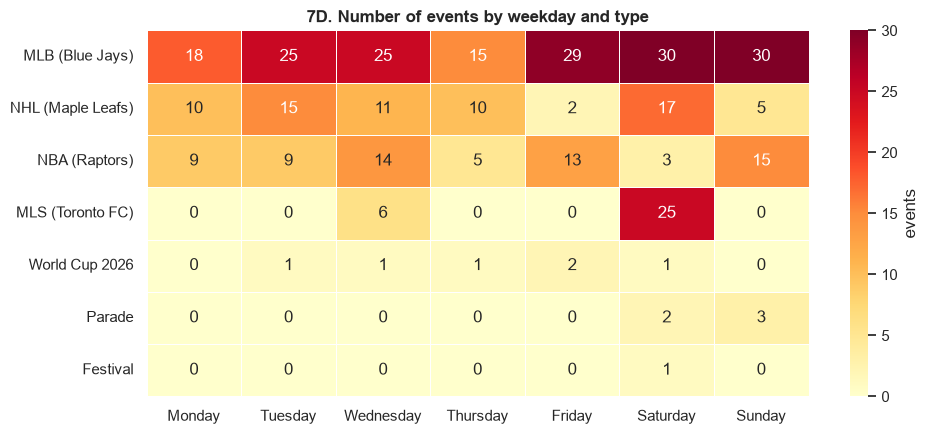

In [88]:
timed = events[events["start"].notna()].drop_duplicates("event_id")
wd_type = pd.crosstab(timed["event_type"], timed["start"].dt.day_name()).reindex(index=[t for t in TYPE_ORDER if t in timed["event_type"].unique()], columns=WEEKDAYS, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(wd_type, annot=True, fmt="d", cmap="YlOrRd", linewidths=0.4, ax=ax, cbar_kws={"label": "events"})
ax.set_yticklabels([TYPE_NAMES[t] for t in wd_type.index], rotation=0)
ax.set(title="7D. Number of events by weekday and type", xlabel="", ylabel="")
plt.tight_layout()

**How to read it:** each square counts events of a type that started on that weekday.

**What stands out:**
- **Toronto FC plays almost only on Saturday (25 of 31).**
- Baseball is spread over all days (Thursday is lowest, with 15 games; Saturday and Sunday have 30 each).
- Basketball peaks on Sunday (15), Wednesday (14) and Friday (13). Hockey peaks on Saturday (17) and Tuesday (15).
- Parades are on weekends (Saturday and Sunday).

**Why it matters:** different event types sit on different weekdays, and weekday changes incidents a lot (Sunday 125 vs Friday 187 incidents). Each type has to be compared against the same weekday, not against all days.

### 7E. At what time of day do events start?

Events with a start time: 353 | start at 19:00 or later: 65% | start before 17:00: 30%


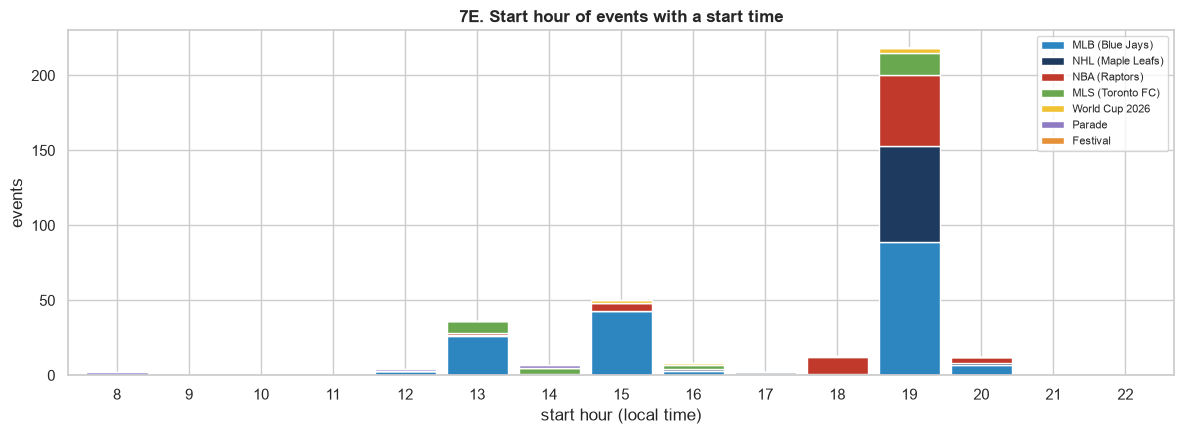

In [89]:
start_hour = pd.crosstab(timed["start"].dt.hour, timed["event_type"]).reindex(index=range(8, 23), fill_value=0)
start_hour = start_hour.reindex(columns=[t for t in TYPE_ORDER if t in start_hour.columns])
fig, ax = plt.subplots(figsize=(12, 4.5))
start_hour.plot.bar(stacked=True, ax=ax, color=[TYPE_COLORS[t] for t in start_hour.columns], width=0.85)
ax.set(title="7E. Start hour of events with a start time", xlabel="start hour (local time)", ylabel="events")
ax.tick_params(axis="x", rotation=0)
ax.legend([TYPE_NAMES[t] for t in start_hour.columns], fontsize=8)
plt.tight_layout()
print(f"Events with a start time: {len(timed)} | start at 19:00 or later: {(timed['start'].dt.hour >= 19).mean():.0%} | start before 17:00: {(timed['start'].dt.hour < 17).mean():.0%}")

**How to read it:** the number of events by hour of start, stacked by type.

**What stands out:** **65% of the 353 events with a start time start at 19:00 or later.** The next group is the afternoon: 30% start before 17:00.
- Hockey is almost all at 19:00 (64 of 70).
- Baseball has three groups: evening (89 at 19:00), afternoon games (43 at 15:00) and early games (26 at 13:00).
- Toronto FC (15 of 31 at 19:00) and the World Cup (3 of 6) have a mix of afternoon and evening starts, and **parades start in the morning or midday** (8:00 to 14:00).

**Why it matters:** the incident baseline is very different at 7 pm (about 7 an hour on a weekday) than at 3 pm (12). The start hour has to be matched with the same hour on non-event days.

### 7F. Venues

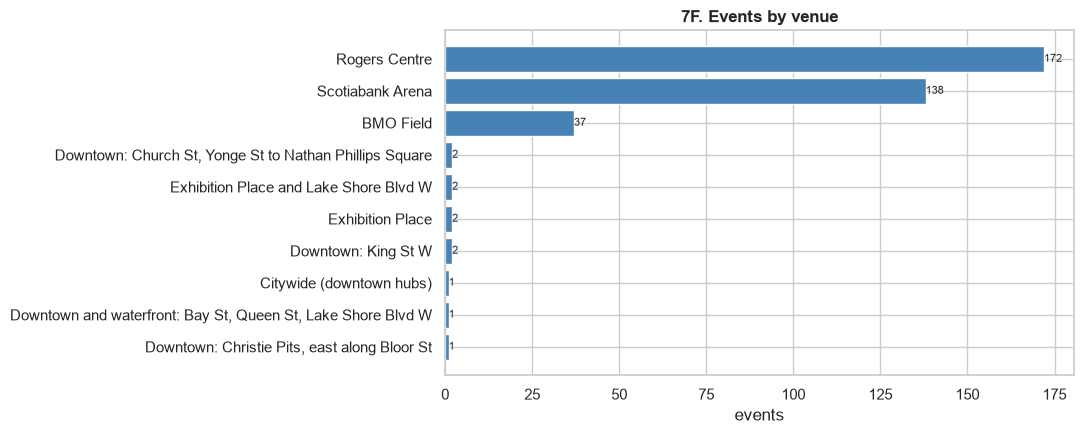

In [90]:
venue_counts = events.drop_duplicates("event_id")["venue"].replace({"BMO Field (Toronto Stadium)": "BMO Field"}).value_counts().iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.barh(venue_counts.index.str.slice(0, 60), venue_counts.values, color="steelblue")
ax.bar_label(bars, fontsize=8)
ax.set(title="7F. Events by venue", xlabel="events")
plt.tight_layout()

**How to read it:** the number of events at each venue.

**What stands out:** **Rogers Centre (172)** and **Scotiabank Arena (138: 70 hockey and 68 basketball)** have most of the events, then **BMO Field (37: 31 MLS and 6 World Cup)**. City events are one or two per location (the CNE and Caribana at Exhibition Place, Pride, TIFF and the marathon downtown).

**Why it matters:** Rogers Centre and Scotiabank Arena are only about 1 km apart, so both are served by the same downtown routes. We will not be able to separate their effects on routes, only on event type and timing.

### 7G. Calendar heatmap of event days
One cell = one day (same layout as 1D). Colour = number of events that day.

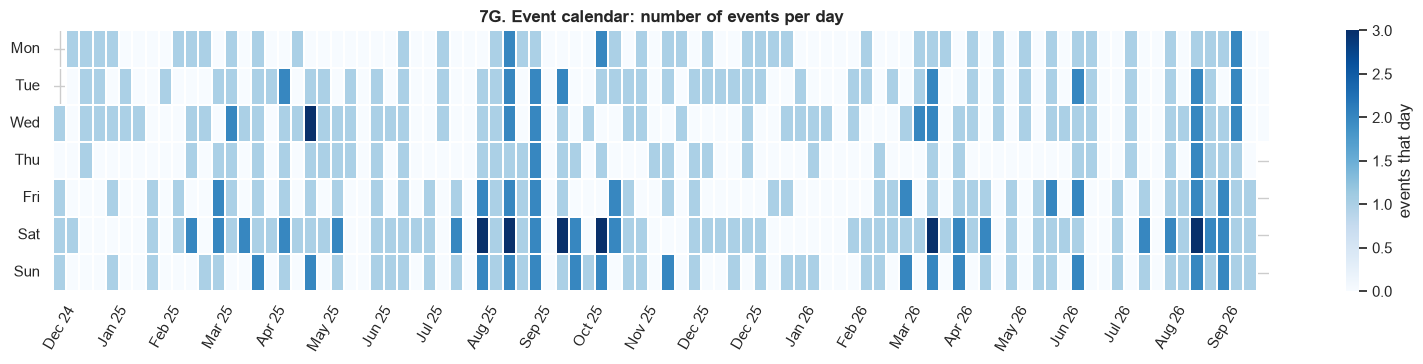

In [91]:
cal_events = daily.assign(week=daily["date"].dt.to_period("W-SUN").dt.start_time, weekday_no=daily["date"].dt.day_of_week)
grid_events = cal_events.pivot(index="weekday_no", columns="week", values="n_events")
fig, ax = plt.subplots(figsize=(16, 3.8))
sns.heatmap(grid_events, cmap="Blues", ax=ax, linewidths=0.3, linecolor="white", cbar_kws={"label": "events that day"})
ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
ax.set_xticks(np.arange(0, grid_events.shape[1], 4) + 0.5)
ax.set_xticklabels([week.strftime("%b %y") for week in grid_events.columns[::4]], rotation=60)
ax.set(title="7G. Event calendar: number of events per day", xlabel="", ylabel="")
plt.tight_layout()

**How to read it:** one cell per day (same layout as 1D). Darker blue = more events that day. White = none.

**What stands out:** between March and October almost every week has events, and weekends are the days most often filled. In winter the pattern is thinner (about 2 to 4 events a week), and there are visible gaps.

**Why it matters:** there are plenty of non-event days to compare with in winter, and fewer in summer, when events are on most days.

### 7H. Several events on the same day
How many days have 0, 1, 2, 3 events, and which types go together?

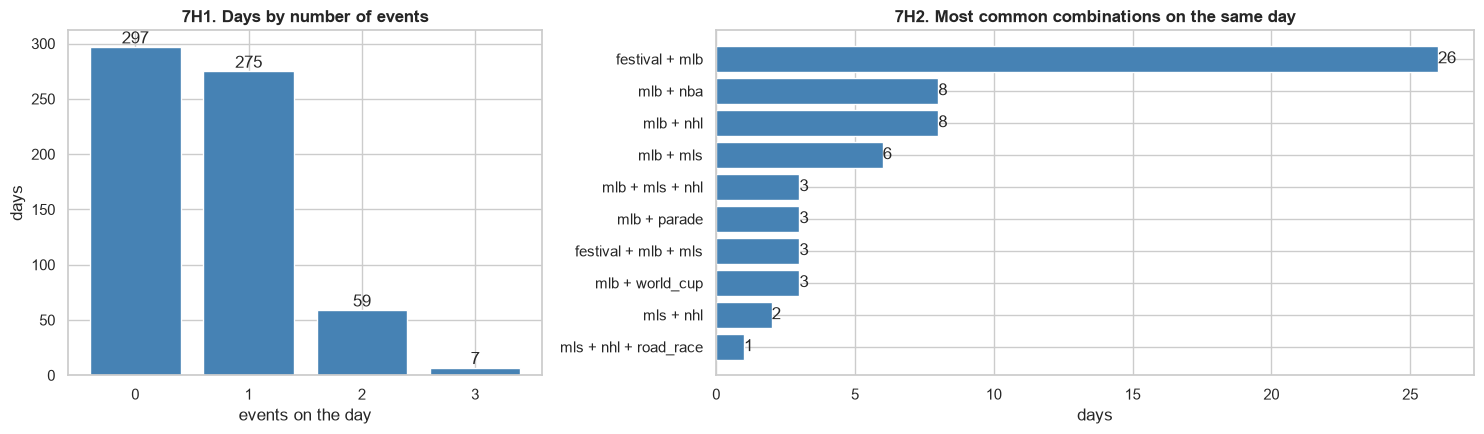

In [92]:
n_events_per_day = daily["n_events"].value_counts().sort_index()
combos = events.groupby("date")["event_type"].agg(lambda s: " + ".join(sorted(set(s)))).value_counts()
combos_multi = combos[combos.index.str.contains(r"\+")].head(10).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
bars = axes[0].bar(n_events_per_day.index.astype(str), n_events_per_day.values, color="steelblue")
axes[0].bar_label(bars)
axes[0].set(title="7H1. Days by number of events", xlabel="events on the day", ylabel="days")
axes[1].barh(combos_multi.index, combos_multi.values, color="steelblue")
axes[1].bar_label(axes[1].containers[0])
axes[1].set(title="7H2. Most common combinations on the same day", xlabel="days")
plt.tight_layout()

**How to read it:** left: how many days had 0, 1, 2 or 3 events. Right: the combinations of types on days with more than one event.

**What stands out:**
- **297 days have no event, 275 days one event, 59 days two and 7 days three.**
- The most common double days are **festival + baseball (26)**, baseball + basketball (8) and baseball + hockey (8). The largest group of overlaps is the CNE or TIFF on a baseball day.
- The most common single-type days are baseball only (111), basketball only (59) and hockey only (56).

**Why it matters:** on 66 days we cannot tell which event an incident belongs to. Those days are best flagged as "multiple events" or analysed separately.

### 7I. Hours inside an event window
How much of the day is covered, hour by hour? (Share of days on which this hour is inside at least one window.)

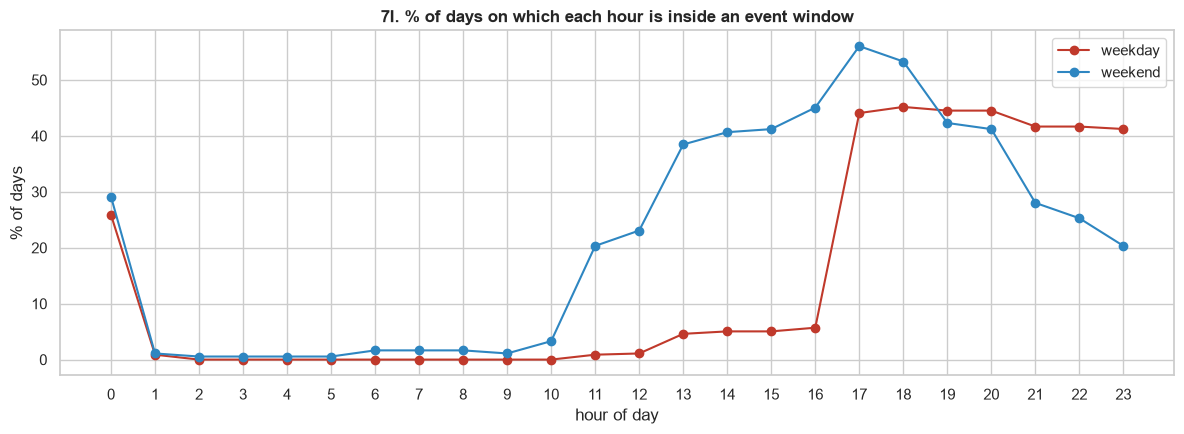

In [93]:
cover_hour = hourly.groupby(["hour", hourly["is_weekend"].map({False: "weekday", True: "weekend"})])["in_event_window"].mean().unstack() * 100
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(cover_hour.index, cover_hour["weekday"], marker="o", color="#c0392b", label="weekday")
ax.plot(cover_hour.index, cover_hour["weekend"], marker="o", color="#2e86c1", label="weekend")
ax.set_xticks(range(24))
ax.set(title="7I. % of days on which each hour is inside an event window", xlabel="hour of day", ylabel="% of days")
ax.legend()
plt.tight_layout()

**How to read it:** for each hour of the day, the percentage of days (weekdays in red, weekends in blue) on which that hour falls inside at least one event window.

**What stands out:**
- **Weekdays**: windows are almost absent until 4 pm (under 6%), then **jump to 41 to 45% of days from 5 pm to midnight**.
- **Weekends**: windows start earlier (about 20% at 11 am) and are **38 to 56% of days from 1 pm to 8 pm**, peaking at 5 pm.
- At 0:00 (just after midnight) about 26 to 29% of days are in a window, from games that run late (window end after midnight).
- Early morning (1 to 10 am) has almost no windows.

**Why it matters:** the evening event hours are very common. 40 to 45% of weekday evening hours are event hours, so there are still 55% non-event hours for comparison. The morning has nothing to compare: the event analysis is about **afternoon and evening hours**.

### 7J. Window hours: how many overlap?

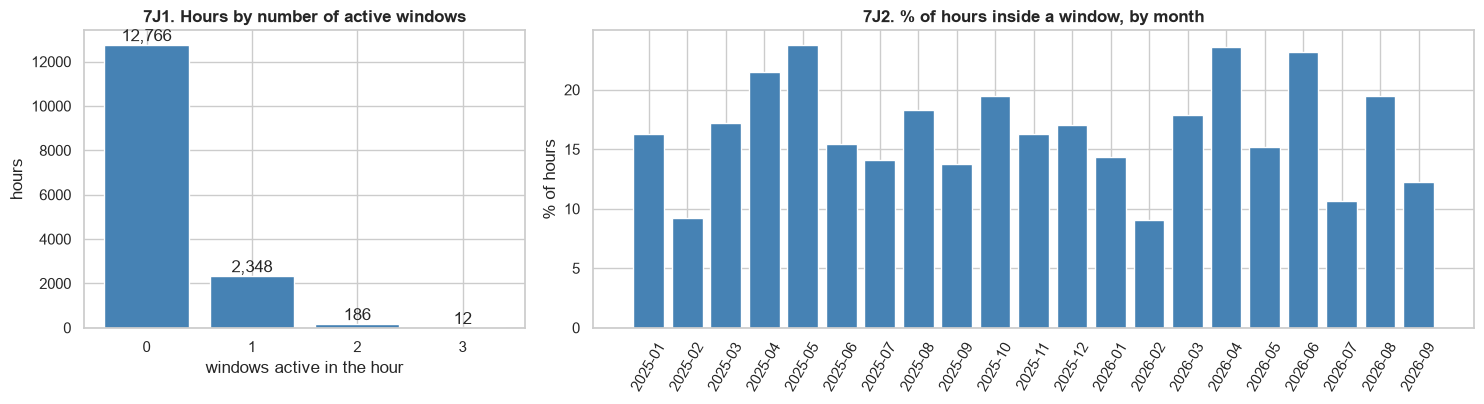

In [94]:
overlap = hourly["n_events_active"].value_counts().sort_index()
window_by_month = hourly.groupby(hourly["date"].dt.to_period("M").astype(str))["in_event_window"].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 2]})
bars = axes[0].bar(overlap.index.astype(str), overlap.values, color="steelblue")
axes[0].bar_label(bars, fmt="{:,.0f}")
axes[0].set(title="7J1. Hours by number of active windows", xlabel="windows active in the hour", ylabel="hours")
axes[1].bar(window_by_month.index, window_by_month.values, color="steelblue")
axes[1].set(title="7J2. % of hours inside a window, by month", xlabel="", ylabel="% of hours")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()

**How to read it:** left: how many hours have 0, 1, 2 or 3 windows active at once. Right: share of all hours that are inside a window, by month.

**What stands out:**
- **Almost all window hours are single (2,348 of 2,546)**, 186 hours have two events and only 12 have three.
- The share of hours in a window goes from **9% in February to 24% in May 2025, April 2026 and June 2026**.

**Why it matters:** we can treat "in an event window" as a yes/no flag with little loss. And some months are heavily event-covered (spring), so these months provide less contrast.

### 7K. Event days and the weekday
Share of days of each weekday that have at least one event, next to the event-free share. Events cluster on some weekdays.

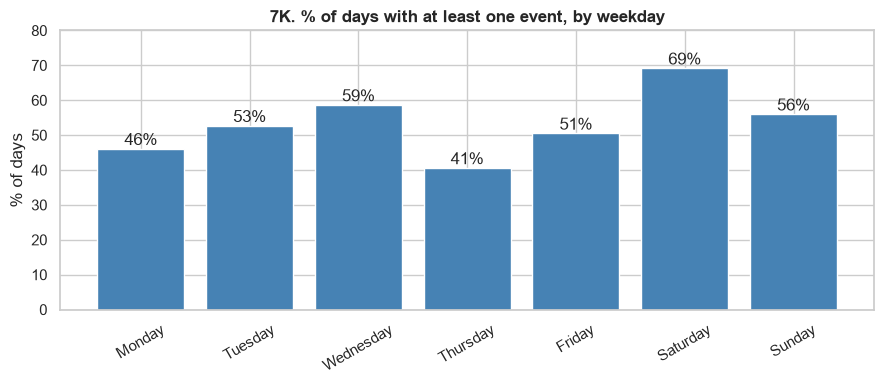

In [95]:
share_event_weekday = daily.groupby("weekday")["has_event"].mean().reindex(WEEKDAYS) * 100
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(share_event_weekday.index, share_event_weekday.values, color="steelblue")
ax.bar_label(bars, fmt="%.0f%%")
ax.set(title="7K. % of days with at least one event, by weekday", ylabel="% of days", ylim=(0, 80))
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()

**How to read it:** the share of days with at least one event, for each weekday.

**What stands out:** **Saturday is the most event-heavy day (69%)**, followed by Wednesday (59%) and Sunday (56%). **Thursday has the fewest (41%)**, and Monday 46%.

**Why it matters:** events pile up on Saturdays and Wednesdays. If Saturdays are generally different (they are: fewer incidents than weekdays), a raw event-day average mixes in the weekday effect.

### 7L. Weather on event days, by type
Temperature on the days of each event type. Different types fall in different seasons.

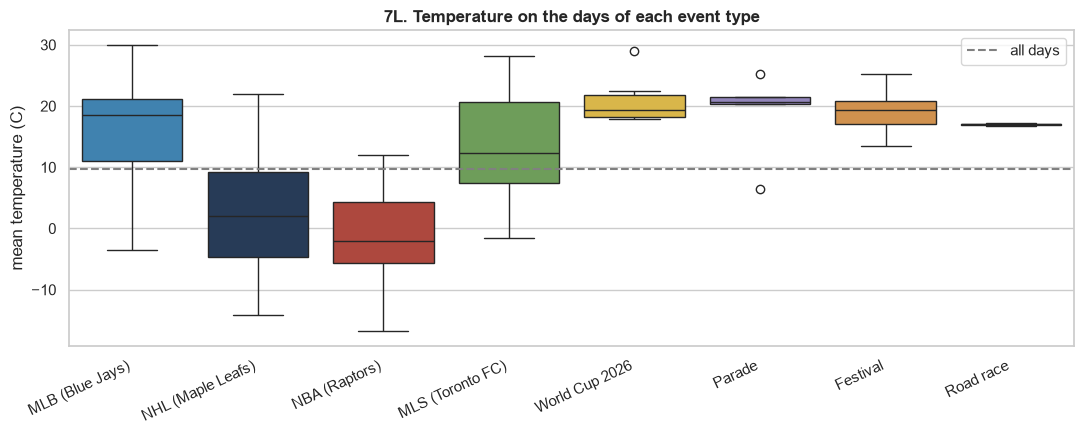

In [96]:
day_type_temp = events.drop_duplicates(["date", "event_type"]).merge(daily[["date", "temp_mean_c", "snow_cm"]], on="date")
order = [t for t in TYPE_ORDER if t in day_type_temp["event_type"].unique()]
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=day_type_temp, x="event_type", y="temp_mean_c", order=order, hue="event_type", palette=TYPE_COLORS, legend=False, ax=ax)
ax.axhline(daily["temp_mean_c"].mean(), color="gray", ls="--", label="all days")
ax.set_xticks(range(len(order)))
ax.set_xticklabels([TYPE_NAMES[t] for t in order], rotation=25, ha="right")
ax.set(title="7L. Temperature on the days of each event type", xlabel="", ylabel="mean temperature (C)")
ax.legend()
plt.tight_layout()

**How to read it:** each box shows the temperature range on the days of that event type. The grey dashed line is the average of all days (9.8 C).

**What stands out:**
- **Basketball and hockey are cold-weather sports**: basketball days have a median temperature of about -2 C (down to -17 C), and hockey about 2 C (down to -14 C).
- **Baseball** is warm, with a median of about 18 C. **Toronto FC (12 C), the World Cup, parades and festivals** are mild to warm (17 to 21 C).

**Why it matters:** hockey and basketball days sit in the cold, snowy part of the year (when incidents are higher, see Step 6) and the other types in the warm part. Without controlling for weather and month, hockey and basketball could look harmful just because of the snow.

### 7M. Holidays and weekends
How many events fall on a weekend or public holiday?

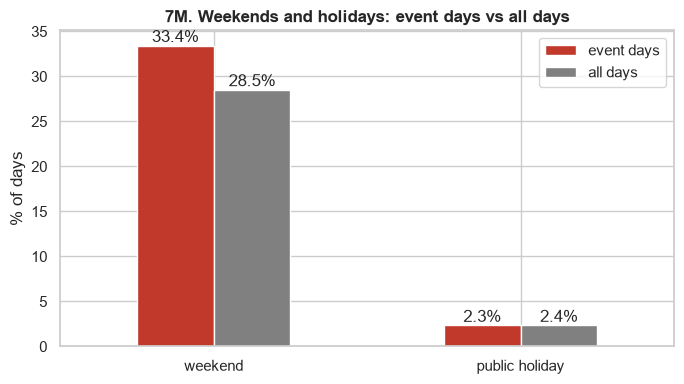

In [97]:
event_days = daily[daily["has_event"]]
share_day_type = pd.DataFrame({
    "event days": [event_days["is_weekend"].mean(), event_days["is_holiday"].mean()],
    "all days": [daily["is_weekend"].mean(), daily["is_holiday"].mean()],
}, index=["weekend", "public holiday"]) * 100
fig, ax = plt.subplots(figsize=(7, 4))
share_day_type.plot.bar(ax=ax, color=["#c0392b", "gray"], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
ax.set(title="7M. Weekends and holidays: event days vs all days", ylabel="% of days")
plt.tight_layout()

**How to read it:** the share of event days (red) and of all days (grey) that are weekends or public holidays.

**What stands out:** event days are slightly more often **weekends (33% vs 28.5% of all days)**. Public holidays are the same (2.3% vs 2.4%).

**Why it matters:** the weekend tilt is real but not large against all days (it is bigger against non-event days: 33% vs 23%, see 6L). Holidays are not a problem here.

### 7N. A first, unfair look: incidents on event days
Average incidents per day for each event type, against a normal day of the same weekday. **This is only a preview** and is expected to mislead:
event types fall in different seasons and weather (see 7L), and the weekday and holiday mix differs. The fair comparison is for notebook 03.

,days,incidents_per_day,vs_normal
MLB (Blue Jays),172.0,162.17,0.98
NHL (Maple Leafs),70.0,171.70,1.02
NBA (Raptors),68.0,162.46,0.98
MLS (Toronto FC),31.0,160.81,1.00
World Cup 2026,6.0,168.83,0.94
Parade,5.0,124.80,0.91
Festival,60.0,166.18,1.01
Road race,2.0,120.00,0.86
any event,341.0,165.05,0.99
no event,297.0,170.93,1.01


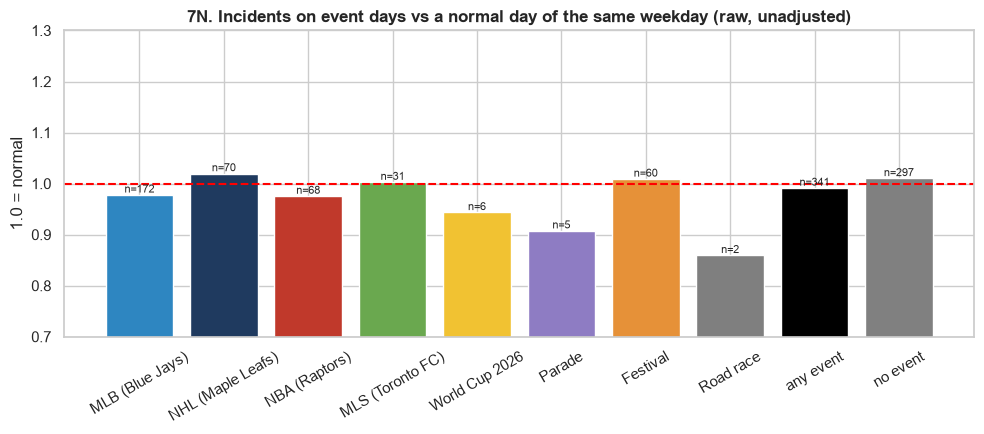

In [98]:
rows = {}
for t in TYPE_ORDER:
    flag = daily[f"has_{t}"] if f"has_{t}" in daily else None
    if flag is not None and flag.any():
        rows[TYPE_NAMES[t]] = {"days": int(flag.sum()), "incidents_per_day": daily.loc[flag, "n_incidents"].mean(), "vs_normal": daily.loc[flag, "vs_normal"].mean()}
rows["any event"] = {"days": int(daily["has_event"].sum()), "incidents_per_day": daily.loc[daily["has_event"], "n_incidents"].mean(), "vs_normal": daily.loc[daily["has_event"], "vs_normal"].mean()}
rows["no event"] = {"days": int((~daily["has_event"]).sum()), "incidents_per_day": daily.loc[~daily["has_event"], "n_incidents"].mean(), "vs_normal": daily.loc[~daily["has_event"], "vs_normal"].mean()}
preview = pd.DataFrame(rows).T

fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [TYPE_COLORS[t] for t in TYPE_ORDER if TYPE_NAMES[t] in preview.index] + ["black", "gray"]
bars = ax.bar(preview.index, preview["vs_normal"], color=colors)
ax.bar_label(bars, labels=[f"n={int(n)}" for n in preview["days"]], fontsize=8)
ax.axhline(1, color="red", ls="--")
ax.set(title="7N. Incidents on event days vs a normal day of the same weekday (raw, unadjusted)", ylabel="1.0 = normal", ylim=(0.7, 1.3))
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
preview.round(2)

**How to read it:** for each event type, incidents on its days compared with a normal day of the same weekday (1.0 = normal, red line). `n` is the number of days. **This is the raw, unadjusted view and should not be trusted.**

**What stands out:** everything is close to 1.0: baseball 0.98, basketball 0.98, Toronto FC 1.00, hockey 1.02 and festivals 1.01. **Any event: 0.99; no event: 1.01.** The small groups are noisier (World Cup 0.94 on 6 days, parades 0.91 on 5, road race 0.86 on 2).

**Why it matters:** this raw view shows no event effect. But Steps 3 to 6 showed that the comparison is unfair: hockey and basketball days are in snow season (which raises incidents) and baseball days in summer (which is quieter, and had fewer incidents in 2026). Weekday is handled here, but weather and season are not. An effect could be hidden. And the daily total mixes event hours with the other 20 hours of the day, which dilutes any evening effect. This is why notebook 03 looks at **the event hours** with controls.

### Step 7 takeaways
- The calendar has **358 events on 341 days (53% of days)** and **2,546 event-window hours (16.6% of all hours)**.
- **Sports are large enough to analyse:** baseball 172, hockey 70, basketball 68, Toronto FC 31. **The World Cup (6), parades (5), festivals (5) and the marathon (1) are too few** to analyse alone and should be grouped or treated as case studies.
- **Timing:** 65% of events start at 19:00 or later. Windows cover **40 to 45% of weekday hours from 5 pm to midnight** and 38 to 56% of weekend hours from 1 pm to 8 pm. The morning has no events, so the event analysis is about **afternoon and evening hours**.
- **Event types are tangled up with season and weather:** hockey and basketball in the cold snowy months, baseball and the rest in warm months. Events also pile up on **Saturdays (69% of Saturdays)**, and Toronto FC plays almost only on Saturdays.
- **Overlaps are small:** 66 days have two or more events (mostly the CNE or TIFF with a baseball game). Flag them.
- **The raw comparison shows nothing** (0.99 vs 1.01), which cannot be trusted: events fall on easier days (weekends, mild weather) and the daily total dilutes event hours.
- Limits of the calendar: only **home games** (no away games), the end of a game is a 3-hour guess, no attendance, and the hand-made city events may be incomplete.

*(Numbers in the notes come from the data as run on this version.)*

## Step 8. Takeaways: what the patterns mean for notebook 03

Steps 1 to 7 described the data. This step puts it together: how big are the things we can already see, what does the data allow us to measure,
and what should the event analysis in notebook 03 look like.

### 8A. How big are the factors we already see?
Each bar is a change in daily incidents. The question is whether an event effect would be big enough to stand out next to them.

,% change
Public holiday vs ordinary weekday,-34.7
Sunday vs Friday,-33.3
Any event day vs a normal day (raw),-0.9
Heat (above 25 C),13.3
Busiest 3 months vs quietest 3 months,17.7
Severe cold (below -10 C),22.2
Heavy rain (10-20 mm),22.7
Heavy snow (10+ cm that day),81.5


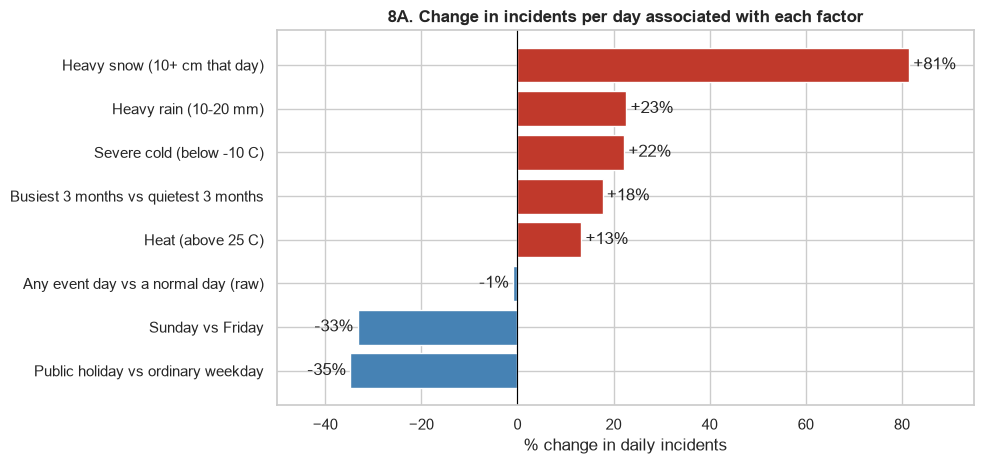

In [99]:
ordinary_weekday = daily.loc[~daily["is_weekend"] & ~daily["is_holiday"], "n_incidents"].mean()
by_weekday_mean = daily.groupby("weekday")["n_incidents"].mean()
month_means = daily.groupby("month")["n_incidents"].mean().sort_values()
factors = pd.Series({
    "Heavy snow (10+ cm that day)": daily.loc[daily["snow_cm"] > 10, "vs_normal"].mean() - 1,
    "Heavy rain (10-20 mm)": daily.loc[daily["precip_mm"].between(10, 20, inclusive="right"), "vs_normal"].mean() - 1,
    "Severe cold (below -10 C)": daily.loc[daily["temp_mean_c"] < -10, "vs_normal"].mean() - 1,
    "Heat (above 25 C)": daily.loc[daily["temp_mean_c"] > 25, "vs_normal"].mean() - 1,
    "Busiest 3 months vs quietest 3 months": month_means.iloc[-3:].mean() / month_means.iloc[:3].mean() - 1,
    "Sunday vs Friday": by_weekday_mean["Sunday"] / by_weekday_mean["Friday"] - 1,
    "Public holiday vs ordinary weekday": daily.loc[daily["is_holiday"], "n_incidents"].mean() / ordinary_weekday - 1,
    "Any event day vs a normal day (raw)": daily.loc[daily["has_event"], "vs_normal"].mean() - 1,
}) * 100
factors = factors.sort_values()

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(factors.index, factors.values, color=["#c0392b" if v > 0 else "steelblue" for v in factors.values])
ax.bar_label(bars, fmt="%+.0f%%", padding=3)
ax.axvline(0, color="black", lw=0.8)
ax.set(title="8A. Change in incidents per day associated with each factor", xlabel="% change in daily incidents")
ax.set_xlim(-50, 95)
plt.tight_layout()
factors.round(1).to_frame("% change")

**How to read it:** each bar is how much busier (red) or quieter (blue) a day is with that factor present. The last bar is the raw event comparison from 7N.

**What stands out:** weather, weekday, holiday and season each move daily incidents by **13% to 81%**. The raw event comparison is **about -1%**. If events add something, it is small next to these, and it has to be measured with these factors held equal.

### 8B. What the data allows: event windows and comparison hours
For each event type, the number of timed windows, the hours inside them, and how many **non-event hours** exist for the same weekday and hour (the comparison pool).

In [100]:
timed_events = events.dropna(subset=["window_start"]).drop_duplicates("event_id")
window_hours = pd.DataFrame(
    [(row.event_type, row.event_id, hour) for row in timed_events.itertuples()
     for hour in pd.date_range(row.window_start.floor("h"), row.window_end, freq="h", inclusive="left")],
    columns=["event_type", "event_id", "datetime"],
).merge(hourly[["datetime", "weekday", "hour"]], on="datetime")
hourly["weekday"] = pd.Categorical(hourly["weekday"], categories=WEEKDAYS, ordered=True)
pool_size = hourly[~hourly["in_event_window"]].groupby(["weekday", "hour"], observed=True).size().rename("comparison_hours")
window_hours["weekday"] = pd.Categorical(window_hours["weekday"], categories=WEEKDAYS, ordered=True)
window_hours = window_hours.join(pool_size, on=["weekday", "hour"])

feasibility = window_hours.groupby("event_type").agg(
    windows=("event_id", "nunique"), window_hours=("datetime", "size"),
    median_comparison_hours=("comparison_hours", "median"), fewest_comparison_hours=("comparison_hours", "min"),
).reindex(TYPE_ORDER).dropna()
feasibility.index = [TYPE_NAMES[t] for t in feasibility.index]

evening = hourly[hourly["hour"].between(17, 23) & ~hourly["in_event_window"]]
near_hourly = incidents[incidents["near_venue"] == True].groupby(incidents["datetime"].dt.floor("h")).size().reindex(hourly["datetime"], fill_value=0)
print(f"Incidents per hour, 5 pm to midnight, outside windows: all routes {evening['n_incidents'].mean():.1f} | "
      f"routes near a venue {near_hourly.loc[evening["datetime"]].mean():.2f} (about {near_hourly.loc[evening["datetime"]].mean() * 7:.0f} per 7-hour window)")
feasibility.astype(int)

Incidents per hour, 5 pm to midnight, outside windows: all routes 7.2 | routes near a venue 0.61 (about 4 per 7-hour window)


,windows,window_hours,median_comparison_hours,fewest_comparison_hours
MLB (Blue Jays),172,1372,50,33
NHL (Maple Leafs),70,506,48,33
NBA (Raptors),68,527,50,33
MLS (Toronto FC),31,239,51,33
World Cup 2026,6,42,50,33
Parade,5,54,55,33
Festival,1,16,83,33


**How to read it:** per event type, the number of event windows with a start time, the hours inside those windows, and the **comparison pool**: how many hours with no event window exist for the same weekday and hour of day (for example, all non-event Wednesdays at 8 pm).

**What stands out:**
- **Baseball (172 windows, 1,372 hours), hockey (70, 506), basketball (68, 527) and Toronto FC (31, 239)** have enough windows to analyse by type.
- **The World Cup (6 windows, 42 hours), parades (5, 54) and festivals (1 window with a time, 16 hours)** are far too few for their own estimates.
- Every event hour has **about 50 comparison hours** (at least 33) with the same weekday and hour but no event. That is a sound baseline.
- **The routes near a venue are very sparse**: about **0.6 incidents per hour** from 5 pm to midnight, or roughly 4 in one event window (compared with 7.2 an hour across all routes). A single event has too little data, so effects must be **pooled across many events of the same type**.

### 8C. What we learned, step by step, and what it means for notebook 03

| Step | What the patterns show | What it means for notebook 03 |
|---|---|---|
| **1. Volume** | About 170 incidents a day (70 to 519). The level drifts: lower in 2026, low in January 2025, a few extreme days. | Compare within the same period. Flag the extreme days and check results without them. |
| **2. Delay size** | Median delay 14 min, mean 24.7. The longest 10% of incidents hold half of all delay minutes. Delays are rounded (10, 15, 20, 30). `min_gap` repeats `min_delay`. | Use incident counts, medians, capped minutes and "long delay" shares. Do not use raw means or `min_gap`. |
| **3. Hour of day** | Strong daily rhythm: quiet night, jump at 5 am, afternoon peak (2 to 6 pm), weekdays very different from weekends, Sunday the quietest. | Compare each event hour with the **same day of week and hour** (Saturday and Sunday are not alike). Focus on afternoon and evening. Treat night (0 to 5 am) separately. |
| **4. Causes** | Diversions (`MFDV`) are 7% of incidents but 36% of delay minutes and 89% of incidents of an hour or more. Parade holds are rare (about 85). **The coding scheme changed on 2026-04-01** and `MFUS` changed twice. | Make `MFDV` and the cause groups the main cause outcomes. Do not compare single codes across April 2026. Do not use `MFUS`. |
| **5. Places** | 21 routes are within 1 km of a venue (9% of incidents), dominated by routes 29, 63, 929, 97, 75 and 320. "Near" is a route label, not an incident location. Routes change over time (32, 36). Night routes are over-represented. | Near-venue vs other routes is a **secondary** comparison, pooled across events. Use each route's own baseline. Handle night hours separately. |
| **6. Weather and holidays** | Snow is the strongest effect (+81% above 10 cm). Cold (+22%), heat (+13%) and heavy rain (+23%) matter less. Holidays are quiet (-35%). Weather lifts the explained share of daily variation from 28% to 44%. | Control for weekday, month, holiday, snow (today and last 3 days), temperature extremes and heavy rain. Repeat without snow days. |
| **7. Events** | 358 events on 341 days (2,546 window hours). 65% start at 19:00 or later. Event days are easier days (milder, more weekends). Sports are numerous, other event types few. The raw comparison is flat (0.99 vs 1.01). | Analyse baseball, hockey, basketball and Toronto FC separately. Group or describe the World Cup, parades and festivals as case studies. Flag the 66 multi-event days and the days of events with no start time (CNE, TIFF, marathon). |

### 8D. Proposed design for notebook 03

This is a proposal built from what the patterns showed. It answers the four research questions in the README.

**1. Unit and comparison.** The unit is **one hour**. An event hour is compared with other hours with the **same day of week and hour of day** that are **outside any window**, in the same part of the year, with weather held equal.
This answers question 1 (are event days and hours different) and question 2 (which types and venues), by running it separately for baseball, hockey, basketball and Toronto FC.

**2. Outcomes, in order of priority.**
1. Incidents per hour (all routes).
2. Diversions (`MFDV`) per hour. It is the cause most tied to road closures and it is stable across the coding change.
3. Capped delay minutes per hour.
4. The share of incidents that last more than 30 minutes.

**3. Scope.** Afternoon and evening hours (about 11:00 to 1 am), where nearly all windows lie. Night hours are analysed separately, or left out.

**4. Controls.** Day of week × hour of day, month (or period), public holiday, snow today and over 3 days, temperature extremes, heavy rain, year or coding period (before and after 2026-04-01), and a flag for the days of events with no start time (CNE, TIFF, the marathon), which have no hourly window.

**5. Time around the event.** Look at each hour from 2 hours before the start to 5 hours after (question 3), since the effect may be strongest around arrival and departure.

**6. Near vs far.** Compare the same event hours on the 21 near-venue routes and on all other routes (question 3). With about 4 incidents per window on near-venue routes the result needs many windows, so pool events of the same type.

**7. Causes.** Look at the cause groups and `MFDV` (question 4). Parade holds (`MFPR`) are too rare for a result.

**8. Robustness (notebook 04).** Placebo (fake event dates should show no effect), other window lengths (1 and 3 hours instead of 2), without snow days, without winter months, without January 2025, without the 66 multi-event days, and only the coding period after 2026-04-01.

### 8E. Limits to keep in mind
- **No exposure data.** We do not know how many buses run on each route and hour, so busy hours and routes are partly just busy service.
- **Incidents, not traffic.** The data records *service incidents* logged by staff. It does not measure road speed or traffic volume, so conclusions are about **bus service disruptions**, not "traffic".
- **Hand-entered values.** Delay minutes are rounded and the location text is free and cut at 22 characters.
- **The coding scheme changed** on 2026-04-01 (36 new codes, `MFUS` redefined).
- **One weather station, one value per day.** We cannot see weather by hour, or by neighbourhood.
- **The calendar is partial.** Only home games, a 3-hour guess for the game length, no attendance, and hand-made city events that may be incomplete.
- **"Near a venue" is a route label** (1 km from a stop), not an incident location. Rogers Centre and Scotiabank Arena are about 1 km apart, so their effects cannot be separated by route.
- **Short period.** About 21 months, with only one summer in 2025 and one in 2026, and a World Cup of just 6 matches.
- **Association, not proof.** Even with controls, the design shows differences linked to events and cannot prove that events caused them.

### 8F. Decisions we still need to make
1. **How near is "near"?** 1 km (21 routes) or 3 km (33 routes)? A wider limit gives more data but dilutes the signal.
2. **Which outcome comes first?** Incidents per hour, or diversions per hour? (Suggested: both, with `MFDV` as the main cause outcome.)
3. **Case studies.** Do we analyse the World Cup, Pride, Caribana, the CNE and TIFF only as short case studies?
4. **Early January 2025.** The first month has a low level (126 a day). Keep it, or leave it out of the main analysis?
5. **Game length.** Keep the 3-hour guess for the end of games, and test 2 and 4 hours in notebook 04?